# Temporal relation prediction (Allen 13 relations) - Kaggle notebook
**Step 1: setup, CONFIG, tokenizer.** Run cells in order. Edit only CONFIG (cell 2) to change an experiment.

In [1]:
# Cell 1: imports, versions, seed helper, device
import os, sys, random, platform
import numpy as np
import torch
import transformers
import sklearn

print("python       :", platform.python_version())
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("numpy        :", np.__version__)
print("scikit-learn :", sklearn.__version__)


def set_seed(seed: int) -> None:
    """Seed python, numpy, torch and torch.cuda."""
    if not isinstance(seed, int):
        raise TypeError(f"set_seed: seed must be int, got {type(seed).__name__}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


if not torch.cuda.is_available():
    raise RuntimeError(
        "Cell 1 (device): no CUDA GPU found. In Kaggle, set Settings > Accelerator "
        "to a GPU and restart the session."
    )
DEVICE = torch.device("cuda")
_props = torch.cuda.get_device_properties(0)
print("device       :", DEVICE)
print("GPU          :", _props.name)
print(f"GPU memory   : {_props.total_memory / 1024**3:.1f} GiB")

python       : 3.13.16
torch        : 2.11.0+cu130
transformers : 5.20.2
numpy        : 2.1.3
scikit-learn : 1.6.1
device       : cuda
GPU          : Tesla T4
GPU memory   : 14.6 GiB


In [2]:
# Cell 2: CONFIG (the only place to edit settings) + seeding
CONFIG = {
    # ---- paths ----
    "train_path": "/kaggle/input/datasets/heytamjid/temporal-relation/records/train.jsonl",
    "val_path":   "/kaggle/input/datasets/heytamjid/temporal-relation/records/validation.jsonl",
    "test_path":  "/kaggle/input/datasets/heytamjid/temporal-relation/records/test.jsonl",
    "bert_path":  "bert-base-cased",     # a LOCAL FOLDER with the cased BERT, or the name "bert-base-cased": cell 3 then downloads it (Internet on)
    "bert_download_dir": "/kaggle/working/bert-base-cased",   # where cell 3 puts that download (cell 3 then sets bert_path to this folder)
    "out_dir":    "/kaggle/working",
    # value of the "split" field expected inside each file
    "split_field_values": {"train": "train", "val": "validation", "test": "test"},

    # ---- general ----
    "seed": 42,
    "max_len": 512,

    # ---- EventTransformer ----
    "use_event_transformer": True,
    "et_layers": 2,
    "et_heads": 8,
    "et_ff": 3072,
    "et_dropout": 0.1,

    # ---- pair MLP ----
    "mlp_hidden": [512, 256],
    "mlp_dropout": 0.1,

    # ---- loss ----
    "lambda_aux": 0.5,
    "class_weight_mode": "inv_sqrt",     # "none" | "inv_sqrt"
    "loss_reduction": "pair",            # "pair" | "stem"

    # ---- optimisation ----
    "lr_bert": 2e-5,
    "lr_new": 1e-4,
    "weight_decay": 0.01,
    "warmup_frac": 0.1,
    "grad_clip": 1.0,
    "stems_per_step": 2,
    "accum_steps": 4,
    "max_epochs": 20,
    "patience": 3,

    # ---- memory / runtime ----
    "use_amp": True,
    "use_grad_ckpt": False,
    "windows_per_chunk": None,           # None = all windows of a stem at once
    "max_run_hours": 8.0,
    "num_workers": 0,                    # DataLoader workers (0 or 2)
    "marker_init_std": 0.02,             # std of the Gaussian noise added to the mean embedding for the 2 marker vectors
    "mem_test_max_stems": 8,             # memory test (cell 24): largest batch of stems to try
    "mem_safety_frac": 0.9,              # memory test: a batch "fits" if its peak is below this fraction of GPU memory

    # ---- bookkeeping ----
    "run_name": "exp1",
    "resume": None,                      # path of a checkpoint (e.g. "/kaggle/working/exp1/last.pt") to continue a run, or None
    "log_every_steps": 20,               # print a training line every N optimizer steps

    # ---- sanity tests (Step 10) ----
    "sanity_overfit_stems": 4,           # test B: number of train stems to overfit
    "sanity_overfit_steps": 200,         # test B: optimizer steps (constant learning rate)
    "sanity_overfit_acc_min": 0.95,      # test B passes if accuracy on those stems is at least this
    "sanity_overfit_f1_min": 0.90,       # ... and macro_f1_present at least this
    "sanity_random_draws": 200,          # test C: draws of the train-frequency sampler
    "sanity_cost_steps": 20,             # test D: real optimizer steps timed
    "smoke_max_groups": 10,              # cell 47: the 2-step test may use up to this many accumulation groups of stems, because the fp16 GradScaler
                                         # skips the first steps while its scale is too large (overflow); only successful steps count

    # ---- experiments (Step 11) ----
    "experiments": {                     # name -> CONFIG overrides; the FIRST entry is the reference the other two are compared with
        "exp1_base": {"use_event_transformer": False, "lambda_aux": 0.0},     # no EventTransformer, no auxiliary loss
        "exp2_et":   {"use_event_transformer": True,  "lambda_aux": 0.0},     # + EventTransformer
        "exp3_aux":  {"use_event_transformer": False, "lambda_aux": 0.5},     # + auxiliary endpoint loss
    },
    "results_file": "results.csv",       # written in out_dir, one row per finished (or stopped) run
    "exp_delete_last_pt": True,          # delete last.pt after a FINISHED run (best.pt is kept) to save ~1.4 GiB each
    "exp_noise_gap": 0.01,               # macro-F1 gaps up to this (1 point) are called "within noise"
    "exp_relation_gap": 0.05,            # per-relation F1 change (5 points) listed as "helped" / "hurt"
    "subsample_pairs_per_relation": 1000,   # cells 61-63 (quick check): keep at most this many training pairs of each relation
    "exp_recheck_tol": 1e-3,             # best.pt re-evaluated on validation must agree with the training log within this
}


# CONFIG keys that an experiment may NOT override (paths, bookkeeping)
EXPERIMENT_FORBIDDEN_KEYS = ("run_name", "resume", "out_dir", "experiments", "train_path", "val_path", "test_path", "bert_path", "bert_download_dir")


def validate_config(cfg: dict) -> None:
    """Raise a precise error if any CONFIG value is out of range."""
    def need(cond, msg):
        if not cond:
            raise ValueError(f"CONFIG: {msg}")

    need(cfg["class_weight_mode"] in ("none", "inv_sqrt"),
         f"class_weight_mode must be 'none' or 'inv_sqrt', got {cfg['class_weight_mode']!r}")
    need(cfg["loss_reduction"] in ("pair", "stem"),
         f"loss_reduction must be 'pair' or 'stem', got {cfg['loss_reduction']!r}")
    need(isinstance(cfg["max_len"], int) and 3 <= cfg["max_len"] <= 512,
         f"max_len must be an int in [3, 512], got {cfg['max_len']!r}")
    need(768 % cfg["et_heads"] == 0,
         f"et_heads={cfg['et_heads']} must divide d_model=768")
    need(isinstance(cfg["mlp_hidden"], (list, tuple)) and len(cfg["mlp_hidden"]) >= 1
         and all(isinstance(h, int) and h > 0 for h in cfg["mlp_hidden"]),
         f"mlp_hidden must be a non-empty list of positive ints, got {cfg['mlp_hidden']!r}")
    for k in ("et_dropout", "mlp_dropout", "warmup_frac"):
        need(0.0 <= cfg[k] < 1.0, f"{k} must be in [0, 1), got {cfg[k]!r}")
    for k in ("lr_bert", "lr_new", "grad_clip", "max_run_hours"):
        need(cfg[k] > 0, f"{k} must be > 0, got {cfg[k]!r}")
    need(cfg["weight_decay"] >= 0 and cfg["lambda_aux"] >= 0,
         "weight_decay and lambda_aux must be >= 0")
    for k in ("et_layers", "et_ff", "stems_per_step", "accum_steps", "max_epochs", "patience"):
        need(isinstance(cfg[k], int) and cfg[k] >= 1, f"{k} must be an int >= 1, got {cfg[k]!r}")
    need(cfg["windows_per_chunk"] is None
         or (isinstance(cfg["windows_per_chunk"], int) and cfg["windows_per_chunk"] >= 1),
         f"windows_per_chunk must be None or an int >= 1, got {cfg['windows_per_chunk']!r}")
    for k in ("use_event_transformer", "use_amp", "use_grad_ckpt"):
        need(isinstance(cfg[k], bool), f"{k} must be a bool, got {cfg[k]!r}")
    need(isinstance(cfg["split_field_values"], dict)
         and set(cfg["split_field_values"]) == {"train", "val", "test"}
         and all(isinstance(v, str) and v for v in cfg["split_field_values"].values()),
         f"split_field_values must map train/val/test to non-empty strings, got {cfg['split_field_values']!r}")
    need(isinstance(cfg["num_workers"], int) and cfg["num_workers"] >= 0,
         f"num_workers must be an int >= 0, got {cfg['num_workers']!r}")
    need(cfg["marker_init_std"] > 0, f"marker_init_std must be > 0, got {cfg['marker_init_std']!r}")
    need(isinstance(cfg["mem_test_max_stems"], int) and cfg["mem_test_max_stems"] >= 1,
         f"mem_test_max_stems must be an int >= 1, got {cfg['mem_test_max_stems']!r}")
    need(0 < cfg["mem_safety_frac"] <= 1, f"mem_safety_frac must be in (0, 1], got {cfg['mem_safety_frac']!r}")
    need(cfg["resume"] is None or (isinstance(cfg["resume"], str) and cfg["resume"] != ""),
         f"resume must be None or a checkpoint path, got {cfg['resume']!r}")
    need(isinstance(cfg["log_every_steps"], int) and cfg["log_every_steps"] >= 1,
         f"log_every_steps must be an int >= 1, got {cfg['log_every_steps']!r}")
    need(all(isinstance(cfg[k], int) and cfg[k] >= 1 for k in ("sanity_overfit_stems", "sanity_overfit_steps", "sanity_random_draws", "sanity_cost_steps")),
         "sanity_overfit_stems, sanity_overfit_steps, sanity_random_draws and sanity_cost_steps must be ints >= 1")
    need(0 < cfg["sanity_overfit_acc_min"] <= 1 and 0 < cfg["sanity_overfit_f1_min"] <= 1, "sanity_overfit_acc_min / f1_min must be in (0, 1]")
    need(isinstance(cfg["smoke_max_groups"], int) and cfg["smoke_max_groups"] >= 2, f"smoke_max_groups must be an int >= 2, got {cfg['smoke_max_groups']!r}")
    exps = cfg["experiments"]
    need(isinstance(exps, dict) and len(exps) == 3 and all(isinstance(k, str) and isinstance(v, dict) for k, v in exps.items()),
         "experiments must be a dict of exactly 3 entries {name: {CONFIG key: value}}; the first is the reference")
    for ename, ov in exps.items():
        need(ename != "" and ename.isascii() and all(c.isalnum() or c in "_.-" for c in ename),
             f"experiment name {ename!r} may only contain letters, digits, '_', '.', '-' (it becomes a folder name)")
        badk = [k for k in ov if k not in cfg or k in EXPERIMENT_FORBIDDEN_KEYS]
        need(not badk, f"experiment {ename!r} overrides {badk}, which are not CONFIG keys an experiment may change")
    need(isinstance(cfg["subsample_pairs_per_relation"], int) and cfg["subsample_pairs_per_relation"] >= 1,
         f"subsample_pairs_per_relation must be an int >= 1, got {cfg['subsample_pairs_per_relation']!r}")
    need(isinstance(cfg["results_file"], str) and cfg["results_file"] != "" and os.path.basename(cfg["results_file"]) == cfg["results_file"],
         f"results_file must be a plain file name, got {cfg['results_file']!r}")
    need(isinstance(cfg["exp_delete_last_pt"], bool), f"exp_delete_last_pt must be a bool, got {cfg['exp_delete_last_pt']!r}")
    need(0 < cfg["exp_noise_gap"] < 1 and 0 < cfg["exp_relation_gap"] < 1 and cfg["exp_recheck_tol"] > 0,
         "exp_noise_gap and exp_relation_gap must be in (0, 1) and exp_recheck_tol > 0")
    need(isinstance(cfg["bert_path"], str) and cfg["bert_path"] != "" and isinstance(cfg["bert_download_dir"], str) and cfg["bert_download_dir"] != "",
         "bert_path and bert_download_dir must be non-empty strings")
    need(isinstance(cfg["run_name"], str) and cfg["run_name"].strip() != "",
         "run_name must be a non-empty string")


validate_config(CONFIG)
os.makedirs(CONFIG["out_dir"], exist_ok=True)
set_seed(CONFIG["seed"])
print(f"CONFIG OK | run_name={CONFIG['run_name']} | seed={CONFIG['seed']} | out_dir={CONFIG['out_dir']}")

CONFIG OK | run_name=exp1 | seed=42 | out_dir=/kaggle/working


In [3]:
# Cell 3: cased tokenizer plus the two event markers
from transformers import AutoTokenizer

EVT_START, EVT_END = "[EVT_START]", "[EVT_END]"
EXPECTED_BASE_VOCAB = 28996            # bert-base-cased
EXPECTED_ID = {EVT_START: 28996, EVT_END: 28997}
EXPECTED_LEN_AFTER = 28998

_bp = CONFIG["bert_path"]
if "<" in _bp or ">" in _bp:
    raise ValueError(f"Cell 3: CONFIG['bert_path'] is still a placeholder: {_bp!r}. Edit CONFIG in cell 2.")

BERT_HF_REPO = "google-bert/bert-base-cased"               # where bert-base-cased lives on the Hub (the short name is an old alias whose Xet download endpoint answers 404)
BERT_AUTO_NAMES = ("bert-base-cased", BERT_HF_REPO)        # values of CONFIG["bert_path"] that trigger the download
BERT_NEEDS = [["config.json"], ["tokenizer.json", "vocab.txt"], ["model.safetensors", "pytorch_model.bin"]]   # each list: at least one of these files


def bert_folder_missing(folder):
    """Descriptions of what a BERT folder lacks (empty list = complete)."""
    return [" or ".join(group) for group in BERT_NEEDS if not any(os.path.isfile(os.path.join(folder, f)) for f in group)]


if os.path.isdir(_bp):
    pass                                                   # a local folder: used as it is
elif _bp in BERT_AUTO_NAMES:
    _dl = CONFIG["bert_download_dir"]
    if os.path.isdir(_dl) and not bert_folder_missing(_dl):
        print(f"Cell 3: '{BERT_HF_REPO}' is already in {_dl}; using it (no download)")
    else:
        print(f"Cell 3: '{BERT_HF_REPO}' is not a local folder; downloading it from the Hugging Face Hub into {_dl} (needs Internet on) ...")
        try:
            from huggingface_hub import snapshot_download
            # first try: skip the TensorFlow / Flax copies and the .bin duplicate; if no weights arrive, a second try also takes pytorch_model.bin
            for _ignore in (["*.h5", "*.msgpack", "*.ot", "*.bin"], ["*.h5", "*.msgpack", "*.ot"]):
                snapshot_download(BERT_HF_REPO, local_dir=_dl, ignore_patterns=_ignore)
                if not bert_folder_missing(_dl):
                    break
        except Exception as err:
            raise RuntimeError(f"Cell 3: could not download '{BERT_HF_REPO}' into {_dl}: {type(err).__name__}: {err}. "
                               f"Is Internet turned on in the notebook settings? Otherwise upload the folder as a Kaggle dataset "
                               f"and set CONFIG['bert_path'] to it.") from err
        print(f"Cell 3: download finished: {sorted(os.listdir(_dl))}")
    _bp = CONFIG["bert_path"] = _dl                        # from here on every cell uses the local folder
else:
    raise FileNotFoundError(f"Cell 3: CONFIG['bert_path'] = {_bp!r} is neither an existing folder nor one of {BERT_AUTO_NAMES}")
_missing = bert_folder_missing(_bp)
if _missing:
    raise FileNotFoundError(f"Cell 3: the BERT folder {_bp!r} lacks {_missing}")
print(f"Cell 3: BERT folder = {_bp}")

tokenizer = AutoTokenizer.from_pretrained(_bp, do_lower_case=False, use_fast=True)

if len(tokenizer) != EXPECTED_BASE_VOCAB:
    raise RuntimeError(
        f"Cell 3: tokenizer at {_bp!r} has {len(tokenizer)} tokens before adding markers; "
        f"expected {EXPECTED_BASE_VOCAB} (bert-base-cased). Wrong vocabulary (uncased gives 30522)."
    )

n_added = tokenizer.add_special_tokens({"additional_special_tokens": [EVT_START, EVT_END]})
if n_added != 2:
    raise RuntimeError(f"Cell 3: expected 2 new tokens added, got {n_added}. "
                       f"Markers may already exist in the vocabulary.")

for tok, want in EXPECTED_ID.items():
    got = tokenizer.convert_tokens_to_ids(tok)
    assert got == want, f"Cell 3: id of {tok} is {got}, expected {want}"
assert len(tokenizer) == EXPECTED_LEN_AFTER, \
    f"Cell 3: len(tokenizer)={len(tokenizer)}, expected {EXPECTED_LEN_AFTER}"

print("tokenizer class :", type(tokenizer).__name__)
print("len(tokenizer)  :", len(tokenizer))
print("marker ids      :", {t: tokenizer.convert_tokens_to_ids(t) for t in (EVT_START, EVT_END)})
print("cls/sep/pad ids :", tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id)

Cell 3: 'google-bert/bert-base-cased' is not a local folder; downloading it from the Hugging Face Hub into /kaggle/working/bert-base-cased (needs Internet on) ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Cell 3: download finished: ['.cache', '.gitattributes', 'README.md', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']
Cell 3: BERT folder = /kaggle/working/bert-base-cased
tokenizer class : BertTokenizer
len(tokenizer)  : 28998
marker ids      : {'[EVT_START]': 28996, '[EVT_END]': 28997}
cls/sep/pad ids : 101 102 0


In [4]:
# Cell 4: tokenizer test
TEST_TEXT = "He [EVT_START]took the call[EVT_END] outside."

ids = tokenizer.encode(TEST_TEXT, add_special_tokens=False)   # same convention as full_input_ids
toks = tokenizer.convert_ids_to_tokens(ids)
print("tokens:", toks)
print("ids   :", ids)

# each marker appears exactly once, as a single token with the right id
for m in (EVT_START, EVT_END):
    n_tok = toks.count(m)
    n_id = ids.count(EXPECTED_ID[m])
    assert n_tok == 1, f"Cell 4: token {m} appears {n_tok} times in {toks}, expected 1"
    assert n_id == 1, f"Cell 4: id {EXPECTED_ID[m]} appears {n_id} times in {ids}, expected 1"
    assert ids[toks.index(m)] == EXPECTED_ID[m], f"Cell 4: {m} has wrong id {ids[toks.index(m)]}"

# markers must come in order and enclose the event words
assert toks.index(EVT_START) < toks.index(EVT_END), "Cell 4: [EVT_END] appears before [EVT_START]"
inside = toks[toks.index(EVT_START) + 1: toks.index(EVT_END)]
assert inside == ["took", "the", "call"], f"Cell 4: tokens between markers are {inside}, expected ['took','the','call']"

# cased: "He" keeps its capital letter
assert toks[0] == "He", f"Cell 4: first token is {toks[0]!r}, expected 'He' (tokenizer is lower-casing?)"
assert tokenizer.convert_tokens_to_ids("He") != tokenizer.unk_token_id, "Cell 4: 'He' is not in the vocabulary"
assert "he" not in toks and "[UNK]" not in toks, f"Cell 4: unexpected lower-cased or UNK token in {toks}"

# with specials added by the tokenizer: [CLS] ... [SEP]
ids_full = tokenizer.encode(TEST_TEXT, add_special_tokens=True)
assert ids_full[0] == 101 and ids_full[-1] == 102 and ids_full[1:-1] == ids, \
    f"Cell 4: [CLS]/[SEP] wrapping wrong: {ids_full}"

print("TOKENIZER TEST PASSED")

tokens: ['He', '[EVT_START]', 'took', 'the', 'call', '[EVT_END]', 'outside', '.']
ids   : [1124, 28996, 1261, 1103, 1840, 28997, 1796, 119]
TOKENIZER TEST PASSED


## Step 2: load the three files, validate every stem, statistics, class weights
Cell 5 defines constants and `validate_stem`. Cell 6 loads and validates (stems with problems are skipped, never repaired).

In [5]:
# Cell 5: constants, validate_stem, jsonl reader (definitions only, reads no data)
import json, copy, collections

SIG = [[0,0,0,0],[0,0,1,0],[0,0,2,0],[1,0,2,0],[2,0,2,0],[2,0,2,1],[1,0,2,1],
       [0,0,2,1],[0,0,2,2],[1,0,2,2],[2,0,2,2],[2,1,2,2],[2,2,2,2]]
RELATION_NAMES = ["before", "meets", "overlaps", "starts", "during", "finishes", "equal",
                  "finished-by", "contains", "started-by", "overlapped-by", "met-by", "after"]
NUM_CLASSES = 13
SPLITS = ("train", "val", "test")                 # keys of the CONFIG paths: train_path, val_path, test_path
START_ID = EXPECTED_ID[EVT_START]                 # 28996, from cell 3
END_ID = EXPECTED_ID[EVT_END]                     # 28997, from cell 3

# --- sanity checks on the constants themselves ---
assert len(SIG) == NUM_CLASSES and all(len(r) == 4 for r in SIG), "SIG must be 13 rows x 4 columns"
assert len({tuple(r) for r in SIG}) == NUM_CLASSES, "SIG rows must be unique"
assert len(RELATION_NAMES) == NUM_CLASSES, "RELATION_NAMES must have 13 entries"
_flip = {0: 2, 1: 1, 2: 0}
for _c in range(NUM_CLASSES):                     # converse of class c must be class 12 - c
    _ss, _se, _es, _ee = SIG[_c]
    assert SIG[NUM_CLASSES - 1 - _c] == [_flip[_ss], _flip[_es], _flip[_se], _flip[_ee]], \
        f"SIG: converse of class {_c} ({RELATION_NAMES[_c]}) is not class {NUM_CLASSES - 1 - _c}"
assert set(CONFIG["split_field_values"]) == set(SPLITS), \
    f"CONFIG['split_field_values'] keys must be {SPLITS}; re-run cell 2 after editing it"


def _check_stem(stem, expected_split, max_len, add):
    """All checks. `add(tag, message)` records one problem. Missing fields raise and are caught by validate_stem."""
    events, pairs, windows, ids = stem["events"], stem["pairs"], stem["windows"], stem["full_input_ids"]
    _ = stem["stem_id"], stem["narrative_group"], stem["token_count"]       # must exist
    n = len(events)

    # 1. counts and pair coverage
    if stem["event_count"] != n:
        add("count", f"event_count={stem['event_count']} but len(events)={n}")
    exp_pairs = n * (n - 1) // 2
    if stem["pair_count"] != len(pairs) or len(pairs) != exp_pairs:
        add("count", f"pair_count={stem['pair_count']}, len(pairs)={len(pairs)}, expected n(n-1)/2={exp_pairs} for n={n}")
    seen, bad_idx = collections.Counter(), 0
    for p in pairs:
        i, j = p["event_i"], p["event_j"]
        if isinstance(i, int) and isinstance(j, int) and 0 <= i < j < n:
            seen[(i, j)] += 1
        else:
            bad_idx += 1
    n_dup = sum(1 for v in seen.values() if v > 1)
    n_missing = exp_pairs - len(seen)
    if bad_idx or n_dup or n_missing:
        add("pairs", f"{bad_idx} pair(s) with invalid indices (need 0<=i<j<{n}), {n_dup} duplicated, {n_missing} missing")

    # 2. labels
    bad_label = bad_sig = 0
    for p in pairs:
        lab = p["label_id"]
        if not isinstance(lab, int) or isinstance(lab, bool) or not 0 <= lab < NUM_CLASSES:
            bad_label += 1
        elif list(p["endpoint_labels"]) != SIG[lab]:
            bad_sig += 1
    if bad_label:
        add("label", f"{bad_label} pair(s) with label_id outside 0..{NUM_CLASSES - 1}")
    if bad_sig:
        add("label", f"{bad_sig} pair(s) with endpoint_labels != SIG[label_id]")

    # 3. marker counts in full_input_ids
    n_s, n_e = ids.count(START_ID), ids.count(END_ID)
    if n_s != n or n_e != n:
        add("markers", f"full_input_ids has {n_s} x {START_ID} and {n_e} x {END_ID}, expected {n} of each")

    # 4. per-event checks (global positions, then window positions)
    bad = collections.defaultdict(list)           # check name -> list of event positions that failed
    prev_end_marker = -1
    for k, e in enumerate(events):
        if e["event_index"] != k or e["event_id"] != f"E{k + 1}":
            bad["event_index/event_id not in text order"].append(k)
        sm, em, ts, te = e["start_marker_token"], e["end_marker_token"], e["token_start"], e["token_end"]
        if not (0 <= sm < len(ids) and 0 <= em < len(ids)):
            bad["marker position outside full_input_ids"].append(k)
            continue
        if ids[sm] != START_ID:
            bad[f"full_input_ids[start_marker_token] != {START_ID}"].append(k)
        if ids[em] != END_ID:
            bad[f"full_input_ids[end_marker_token] != {END_ID}"].append(k)
        if ts != sm + 1:
            bad["token_start != start_marker_token + 1"].append(k)
        if te != em:
            bad["token_end != end_marker_token"].append(k)
        if not te > ts:
            bad["token_end <= token_start (empty event)"].append(k)
        if sm <= prev_end_marker:
            bad["event overlaps or precedes the previous event"].append(k)
        prev_end_marker = em

        wi = e["window_index"]
        if not (isinstance(wi, int) and 0 <= wi < len(windows)):
            bad["window_index out of range"].append(k)
            continue
        wid = windows[wi]["input_ids"]
        wts, wte, wsm, wem = e["window_token_start"], e["window_token_end"], e["window_start_marker"], e["window_end_marker"]
        if not (0 <= wsm < len(wid) and 0 <= wem < len(wid) and 0 <= wts <= wte <= len(wid)):
            bad["window position outside window input_ids"].append(k)
            continue
        if wid[wts:wte] != ids[ts:te]:
            bad["window tokens != full_input_ids tokens"].append(k)
        if wid[wsm] != START_ID:
            bad[f"window input_ids[window_start_marker] != {START_ID}"].append(k)
        if wid[wem] != END_ID:
            bad[f"window input_ids[window_end_marker] != {END_ID}"].append(k)
        if wts != wsm + 1 or wte != wem:
            bad["window_token_start/end not between the window markers"].append(k)
    for what, ks in bad.items():
        add("event", f"{what} for {len(ks)} event(s), first at events[{ks[0]}]")

    # 5. window sizes
    if stem["window_count"] != len(windows):
        add("window", f"window_count={stem['window_count']} but len(windows)={len(windows)}")
    for w in windows:
        if len(w["input_ids"]) > max_len:
            add("window", f"window {w['window_index']} has {len(w['input_ids'])} tokens > max_len={max_len}")
        if len(w["attention_mask"]) != len(w["input_ids"]):
            add("window", f"window {w['window_index']}: len(attention_mask)={len(w['attention_mask'])} != len(input_ids)={len(w['input_ids'])}")

    # 6. split field
    if stem["split"] != expected_split:
        add("split", f"split field is {stem['split']!r}, file is {expected_split!r}")


def validate_stem(stem, expected_split, max_len):
    """Return a list of problems (empty list = stem is fine). Never raises on malformed data."""
    problems = []
    def add(tag, msg):
        problems.append(f"{tag}: {msg}")
    try:
        _check_stem(stem, expected_split, max_len, add)
    except (KeyError, TypeError, IndexError, AttributeError) as err:
        add("malformed", f"{type(err).__name__}: {err}")
    return problems


def read_jsonl(path, split_key):
    """Read one stem per line. Raises with the file and line number on any problem."""
    if "<" in path or ">" in path:
        raise ValueError(f"Cell 5: CONFIG['{split_key}_path'] is still a placeholder: {path!r}. Edit CONFIG in cell 2.")
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Cell 5: CONFIG['{split_key}_path'] is not a file: {path!r}")
    out = []
    with open(path, encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError as err:
                raise ValueError(f"Cell 5: {path!r} line {line_no} is not valid JSON: {err}") from err
    if not out:
        raise ValueError(f"Cell 5: {path!r} contains no stems")
    return out


print("definitions OK | START_ID =", START_ID, "| END_ID =", END_ID, "| classes =", NUM_CLASSES)

definitions OK | START_ID = 28996 | END_ID = 28997 | classes = 13


In [6]:
# Cell 6: read the three files, validate every stem, skip (never repair) bad stems
DATA = {}                 # split -> list of valid stems (used from now on)
SKIPPED = {}              # split -> list of (stem_id, problems)
ALL_IDS = {}              # split -> stem_id of EVERY stem read (valid or not), for the leakage check
ALL_GROUPS = {}           # split -> narrative_group of EVERY stem read

for sp in SPLITS:
    path = CONFIG[f"{sp}_path"]
    stems = read_jsonl(path, sp)
    expected_split = CONFIG["split_field_values"][sp]
    DATA[sp], SKIPPED[sp] = [], []
    ALL_IDS[sp] = [s.get("stem_id") for s in stems]
    ALL_GROUPS[sp] = [s.get("narrative_group") for s in stems]
    for s in stems:
        problems = validate_stem(s, expected_split, CONFIG["max_len"])
        if problems:
            SKIPPED[sp].append((s.get("stem_id"), problems))
            shown = "; ".join(problems[:3]) + (f" (+{len(problems) - 3} more)" if len(problems) > 3 else "")
            print(f"WARNING skipped [{sp}] stem_id={s.get('stem_id')}: {shown}")
        else:
            DATA[sp].append(s)
    if not DATA[sp]:
        seen_splits = dict(collections.Counter(s.get("split") for s in stems))
        raise RuntimeError(
            f"Cell 6: every stem of {path!r} was skipped. 'split' values found in the file: {seen_splits}; "
            f"CONFIG['split_field_values']['{sp}'] is {expected_split!r}. Fix CONFIG or the file."
        )

print("\n=== read / kept / skipped ===")
for sp in SPLITS:
    n_read = len(DATA[sp]) + len(SKIPPED[sp])
    tags = collections.Counter(p.split(":", 1)[0] for _, probs in SKIPPED[sp] for p in probs)
    print(f"{sp:5s}: read {n_read:5d} | kept {len(DATA[sp]):5d} | skipped {len(SKIPPED[sp]):5d}"
          + (f" | problem tags {dict(tags)}" if tags else ""))


=== read / kept / skipped ===
train: read   236 | kept   236 | skipped     0
val  : read    31 | kept    31 | skipped     0
test : read    34 | kept    34 | skipped     0


In [7]:
# Cell 7: self-test of validate_stem (corrupt a copy of a good stem; every corruption must be detected)
_sp = SPLITS[0]
_good = DATA[_sp][0]
_expected = CONFIG["split_field_values"][_sp]
assert validate_stem(_good, _expected, CONFIG["max_len"]) == [], "a stem that was kept must validate cleanly"

_e0 = _good["events"][0]
_wi = _e0["window_index"]
_wts, _wsm = _e0["window_token_start"], _e0["window_start_marker"]

def _set(d, k, v): d[k] = v

MUTATIONS = {
    "event_count +1":            lambda s: _set(s, "event_count", s["event_count"] + 1),
    "pair removed":              lambda s: s["pairs"].pop(),
    "pair duplicated":           lambda s: s["pairs"].append(copy.deepcopy(s["pairs"][0])),
    "label_id = 13":             lambda s: _set(s["pairs"][0], "label_id", 13),
    "endpoint_labels wrong":     lambda s: _set(s["pairs"][0], "endpoint_labels", SIG[(s["pairs"][0]["label_id"] + 1) % NUM_CLASSES]),
    "extra start marker":        lambda s: s["full_input_ids"].append(START_ID),
    "start_marker_token + 1":    lambda s: _set(s["events"][0], "start_marker_token", s["events"][0]["start_marker_token"] + 1),
    "token_start + 1":           lambda s: _set(s["events"][0], "token_start", s["events"][0]["token_start"] + 1),
    "window tokens changed":     lambda s: s["windows"][_wi]["input_ids"].__setitem__(_wts, (s["windows"][_wi]["input_ids"][_wts] + 1) % START_ID),
    "window marker overwritten": lambda s: s["windows"][_wi]["input_ids"].__setitem__(_wsm, 1),
    "window longer than max_len": lambda s: s["windows"][0]["input_ids"].extend([0] * (CONFIG["max_len"] + 1)),
    "attention_mask shortened":  lambda s: s["windows"][0]["attention_mask"].pop(),
    "split field wrong":         lambda s: _set(s, "split", "something_else"),
    "required field missing":    lambda s: s.pop("events"),
}
for name, mutate in MUTATIONS.items():
    corrupted = copy.deepcopy(_good)
    mutate(corrupted)
    probs = validate_stem(corrupted, _expected, CONFIG["max_len"])
    assert probs, f"Cell 7: validate_stem did NOT detect corruption '{name}'"
    print(f"detected  {name:28s} -> {probs[0][:90]}")
print(f"\nVALIDATE_STEM SELF-TEST PASSED ({len(MUTATIONS)}/{len(MUTATIONS)} corruptions detected)")

detected  event_count +1               -> count: event_count=18 but len(events)=17
detected  pair removed                 -> count: pair_count=136, len(pairs)=135, expected n(n-1)/2=136 for n=17
detected  pair duplicated              -> count: pair_count=136, len(pairs)=137, expected n(n-1)/2=136 for n=17
detected  label_id = 13                -> label: 1 pair(s) with label_id outside 0..12
detected  endpoint_labels wrong        -> label: 1 pair(s) with endpoint_labels != SIG[label_id]
detected  extra start marker           -> markers: full_input_ids has 18 x 28996 and 17 x 28997, expected 17 of each
detected  start_marker_token + 1       -> event: full_input_ids[start_marker_token] != 28996 for 1 event(s), first at events[0]
detected  token_start + 1              -> event: token_start != start_marker_token + 1 for 1 event(s), first at events[0]
detected  window tokens changed        -> event: window tokens != full_input_ids tokens for 1 event(s), first at events[0]
detected  window ma

In [8]:
# Cell 8: statistics per split (valid stems only)
def split_stats(stems):
    return {
        "stems": len(stems),
        "events": sum(len(s["events"]) for s in stems),
        "pairs": sum(len(s["pairs"]) for s in stems),
        "stems with >1 window": sum(1 for s in stems if len(s["windows"]) > 1),
        "max events in a stem": max(len(s["events"]) for s in stems),
        "max token_count": max(s["token_count"] for s in stems),
        "max pairs in a stem": max(len(s["pairs"]) for s in stems),
    }

STATS = {sp: split_stats(DATA[sp]) for sp in SPLITS}
print(f"{'':24s}" + "".join(f"{sp:>10s}" for sp in SPLITS))
for key in STATS[SPLITS[0]]:
    print(f"{key:24s}" + "".join(f"{STATS[sp][key]:>10d}" for sp in SPLITS))
print(f"{'skipped stems':24s}" + "".join(f"{len(SKIPPED[sp]):>10d}" for sp in SPLITS))

                             train       val      test
stems                          236        31        34
events                        4583       636       704
pairs                        54953      8122     10725
stems with >1 window            32         3         5
max events in a stem            58        53        78
max token_count               1324      1051      1589
max pairs in a stem           1653      1378      3003
skipped stems                    0         0         0


In [9]:
# Cell 9: class distribution per split
LABEL_COUNTS = {sp: np.zeros(NUM_CLASSES, dtype=np.int64) for sp in SPLITS}
for sp in SPLITS:
    for s in DATA[sp]:
        for p in s["pairs"]:
            LABEL_COUNTS[sp][p["label_id"]] += 1
    assert LABEL_COUNTS[sp].sum() == STATS[sp]["pairs"], \
        f"Cell 9: {sp}: class counts sum to {LABEL_COUNTS[sp].sum()} but there are {STATS[sp]['pairs']} pairs"

print(f"{'id':>2s} {'relation':14s}" + "".join(f"{sp + ' n':>10s}{'%':>8s}" for sp in SPLITS))
for c in range(NUM_CLASSES):
    row = f"{c:>2d} {RELATION_NAMES[c]:14s}"
    for sp in SPLITS:
        row += f"{LABEL_COUNTS[sp][c]:>10d}{100.0 * LABEL_COUNTS[sp][c] / LABEL_COUNTS[sp].sum():>8.2f}"
    print(row)
print(f"{'':>2s} {'total':14s}" + "".join(f"{LABEL_COUNTS[sp].sum():>10d}{100.0:>8.2f}" for sp in SPLITS))

for sp in SPLITS:
    for c in range(NUM_CLASSES):
        if LABEL_COUNTS[sp][c] == 0:
            print(f"WARNING: class {c} ({RELATION_NAMES[c]}) has ZERO examples in {sp}")

id relation         train n       %     val n       %    test n       %
 0 before             33276   60.55      4498   55.38      5224   48.71
 1 meets               1559    2.84       233    2.87       160    1.49
 2 overlaps             734    1.34        82    1.01       554    5.17
 3 starts               359    0.65        60    0.74        76    0.71
 4 during              1669    3.04       245    3.02       285    2.66
 5 finishes             212    0.39        20    0.25        65    0.61
 6 equal               1896    3.45       188    2.31       428    3.99
 7 finished-by          584    1.06        42    0.52       150    1.40
 8 contains            2800    5.10       449    5.53       402    3.75
 9 started-by           144    0.26        26    0.32        84    0.78
10 overlapped-by        448    0.82        13    0.16       340    3.17
11 met-by               465    0.85        23    0.28        78    0.73
12 after              10807   19.67      2243   27.62      2879 

In [10]:
# Cell 10: leakage check (all stems read, including skipped ones). Stops if any overlap is found.
leak_found = False
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    ov_ids = sorted(set(ALL_IDS[a]) & set(ALL_IDS[b]), key=str)
    ov_groups = sorted((set(ALL_GROUPS[a]) & set(ALL_GROUPS[b])) - {None}, key=str)
    print(f"{a:5s}/{b:5s}: stem_id overlap = {len(ov_ids)} | narrative_group overlap = {len(ov_groups)}")
    if ov_ids:
        print(f"   overlapping stem_id values ({a}/{b}): {ov_ids}")
    if ov_groups:
        print(f"   overlapping narrative_group values ({a}/{b}): {ov_groups}")
    leak_found = leak_found or bool(ov_ids) or bool(ov_groups)

for sp in SPLITS:                                  # extra: duplicates inside one split (warning only)
    dup = [k for k, v in collections.Counter(ALL_IDS[sp]).items() if v > 1]
    if dup:
        print(f"WARNING: {sp} contains duplicated stem_id values: {dup}")
if any(g is None for sp in SPLITS for g in ALL_GROUPS[sp]):
    print("WARNING: some stems have no narrative_group; they are ignored in the group overlap")

if leak_found:
    raise RuntimeError("Cell 10: leakage between splits (see the overlapping values printed above). Fix the data before training.")
print("LEAKAGE CHECK PASSED: all six overlaps are empty")

train/val  : stem_id overlap = 0 | narrative_group overlap = 0
train/test : stem_id overlap = 0 | narrative_group overlap = 0
val  /test : stem_id overlap = 0 | narrative_group overlap = 0
LEAKAGE CHECK PASSED: all six overlaps are empty


In [11]:
# Cell 11: class weights from TRAIN only
def compute_class_weights(counts, mode):
    """mode 'inv_sqrt': w_c = 1/sqrt(count_c) for count_c > 0, mean over those classes = 1; absent classes get 1.0.
       mode 'none'    : all ones. Returns a float32 tensor of shape (13,)."""
    counts = np.asarray(counts, dtype=np.float64)
    assert counts.shape == (NUM_CLASSES,), f"compute_class_weights: counts shape {counts.shape}, expected ({NUM_CLASSES},)"
    present = counts > 0
    w = np.ones(NUM_CLASSES, dtype=np.float64)
    if mode == "none":
        pass
    elif mode == "inv_sqrt":
        if not present.any():
            raise ValueError("compute_class_weights: the train set has no labelled pair")
        raw = 1.0 / np.sqrt(counts[present])
        w[present] = raw / raw.mean()
        assert abs(w[present].mean() - 1.0) < 1e-6, "compute_class_weights: mean over present classes is not 1"
    else:
        raise ValueError(f"compute_class_weights: unknown mode {mode!r}")
    out = torch.tensor(w, dtype=torch.float32)
    assert out.shape == (NUM_CLASSES,), f"class weights shape {tuple(out.shape)}, expected ({NUM_CLASSES},)"
    return out

CLASS_WEIGHTS = compute_class_weights(LABEL_COUNTS["train"], CONFIG["class_weight_mode"])

print(f"class_weight_mode = {CONFIG['class_weight_mode']!r} (computed from TRAIN only)")
print(f"{'id':>2s} {'relation':14s}{'train n':>10s}{'weight':>10s}")
for c in range(NUM_CLASSES):
    print(f"{c:>2d} {RELATION_NAMES[c]:14s}{LABEL_COUNTS['train'][c]:>10d}{CLASS_WEIGHTS[c].item():>10.4f}")
    if LABEL_COUNTS["train"][c] == 0:
        print(f"WARNING: class {c} ({RELATION_NAMES[c]}) has 0 train examples -> weight set to 1.0")
_present = torch.tensor(LABEL_COUNTS["train"] > 0)
print(f"mean weight over classes present in train: {CLASS_WEIGHTS[_present].mean().item():.6f}")
print("CLASS_WEIGHTS:", [round(x, 4) for x in CLASS_WEIGHTS.tolist()])

class_weight_mode = 'inv_sqrt' (computed from TRAIN only)
id relation         train n    weight
 0 before             33276    0.1474
 1 meets               1559    0.6810
 2 overlaps             734    0.9925
 3 starts               359    1.4191
 4 during              1669    0.6582
 5 finishes             212    1.8467
 6 equal               1896    0.6175
 7 finished-by          584    1.1127
 8 contains            2800    0.5082
 9 started-by           144    2.2407
10 overlapped-by        448    1.2704
11 met-by               465    1.2469
12 after              10807    0.2587
mean weight over classes present in train: 1.000000
CLASS_WEIGHTS: [0.1474, 0.681, 0.9925, 1.4191, 0.6582, 1.8467, 0.6175, 1.1127, 0.5082, 2.2407, 1.2704, 1.2469, 0.2587]


## Step 3: Dataset, collate function, loader
Cell 12 defines `StemDataset`, `collate_stems`, `EpochSampler` and `build_loader`. Cells 13-17 test them.

In [12]:
# Cell 12: StemDataset, collate_stems, EpochSampler, build_loader (definitions only)
from torch.utils.data import Dataset, DataLoader, Sampler

PAD_ID, CLS_ID, SEP_ID = tokenizer.pad_token_id, tokenizer.cls_token_id, tokenizer.sep_token_id
assert (PAD_ID, CLS_ID, SEP_ID) == (0, 101, 102), f"Cell 12: unexpected special ids pad/cls/sep = {(PAD_ID, CLS_ID, SEP_ID)}"


class StemDataset(Dataset):
    """One item = one stem (the raw dict). No tensor work here."""
    def __init__(self, stems):
        if not isinstance(stems, list) or len(stems) == 0:
            raise ValueError("StemDataset: stems must be a non-empty list of stem dicts")
        self.stems = stems

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, idx):
        return self.stems[idx]


def collate_stems(batch):
    """List of B stem dicts -> dict of padded window tensors, an event table and a pair table (see keys below)."""
    B = len(batch)
    if B == 0:
        raise ValueError("collate_stems: empty batch")

    # ---- windows (stored unpadded; padded here) ----
    rows_ids, rows_mask, rows_tt, window_stem, offsets = [], [], [], [], []
    for b, s in enumerate(batch):
        offsets.append(len(rows_ids))
        for k, w in enumerate(s["windows"]):
            n_tok = len(w["input_ids"])
            if w["window_index"] != k:
                raise ValueError(f"collate_stems: stem {s['stem_id']}: windows[{k}] has window_index {w['window_index']}")
            if not (len(w["attention_mask"]) == len(w["token_type_ids"]) == n_tok):
                raise ValueError(f"collate_stems: stem {s['stem_id']} window {k}: input_ids/attention_mask/token_type_ids lengths differ")
            rows_ids.append(w["input_ids"]); rows_mask.append(w["attention_mask"]); rows_tt.append(w["token_type_ids"])
            window_stem.append(b)
    W = len(rows_ids)
    win_len = [len(r) for r in rows_ids]
    L = max(win_len)
    input_ids = torch.full((W, L), PAD_ID, dtype=torch.long)
    attention_mask = torch.zeros((W, L), dtype=torch.long)
    token_type_ids = torch.zeros((W, L), dtype=torch.long)
    for r in range(W):
        n_tok = win_len[r]
        input_ids[r, :n_tok] = torch.tensor(rows_ids[r], dtype=torch.long)
        attention_mask[r, :n_tok] = torch.tensor(rows_mask[r], dtype=torch.long)
        token_type_ids[r, :n_tok] = torch.tensor(rows_tt[r], dtype=torch.long)

    # ---- event table: stem order, then text order ----
    ev_stem, ev_pos, ev_window, ev_start, ev_end, n_events = [], [], [], [], [], []
    for b, s in enumerate(batch):
        n_events.append(len(s["events"]))
        for pos, e in enumerate(s["events"]):
            if e["event_index"] != pos:
                raise ValueError(f"collate_stems: stem {s['stem_id']}: events[{pos}] has event_index {e['event_index']}")
            wi = e["window_index"]
            if not 0 <= wi < len(s["windows"]):
                raise ValueError(f"collate_stems: stem {s['stem_id']} event {pos}: window_index {wi} not in 0..{len(s['windows']) - 1}")
            row = offsets[b] + wi
            st, en = e["window_token_start"], e["window_token_end"]
            if not 1 <= st < en <= win_len[row] - 1:
                raise ValueError(f"collate_stems: stem {s['stem_id']} event {pos}: span [{st},{en}) not inside window {wi} "
                                 f"(length {win_len[row]}, [CLS]/[SEP] excluded)")
            ev_stem.append(b); ev_pos.append(pos); ev_window.append(row); ev_start.append(st); ev_end.append(en)

    # ---- pair table (pairs i<j only, in the order stored in the stem) ----
    pr_stem, pr_i, pr_j, pr_label, pr_end, orig_i, orig_j = [], [], [], [], [], [], []
    for b, s in enumerate(batch):
        n = len(s["events"])
        for p in s["pairs"]:
            i, j, lab = p["event_i"], p["event_j"], p["label_id"]
            if not 0 <= i < j < n:
                raise ValueError(f"collate_stems: stem {s['stem_id']}: pair ({i},{j}) violates 0 <= i < j < {n}")
            if not 0 <= lab < NUM_CLASSES or len(p["endpoint_labels"]) != 4:
                raise ValueError(f"collate_stems: stem {s['stem_id']}: bad label_id/endpoint_labels in pair ({i},{j})")
            pr_stem.append(b); pr_i.append(i); pr_j.append(j); pr_label.append(lab); pr_end.append(p["endpoint_labels"])
            orig_i.append(p["original_event_i"]); orig_j.append(p["original_event_j"])

    long_t = lambda x: torch.tensor(x, dtype=torch.long)
    out = {
        "input_ids": input_ids, "attention_mask": attention_mask, "token_type_ids": token_type_ids,
        "window_stem": long_t(window_stem),
        "ev_stem": long_t(ev_stem), "ev_pos": long_t(ev_pos), "ev_window": long_t(ev_window),
        "ev_start": long_t(ev_start), "ev_end": long_t(ev_end), "n_events": long_t(n_events),
        "pr_stem": long_t(pr_stem), "pr_i": long_t(pr_i), "pr_j": long_t(pr_j), "pr_label": long_t(pr_label),
        "pr_endpoints": torch.tensor(pr_end, dtype=torch.long).reshape(-1, 4),
        "stem_ids": [s["stem_id"] for s in batch],
        "orig_event_i": orig_i, "orig_event_j": orig_j,
    }
    E, P = len(ev_stem), len(pr_stem)
    for k in ("input_ids", "attention_mask", "token_type_ids"):
        assert out[k].shape == (W, L), f"collate_stems: {k} shape {tuple(out[k].shape)}, expected {(W, L)}"
    assert out["window_stem"].shape == (W,)
    for k in ("ev_stem", "ev_pos", "ev_window", "ev_start", "ev_end"):
        assert out[k].shape == (E,), f"collate_stems: {k} shape {tuple(out[k].shape)}, expected {(E,)}"
    assert out["n_events"].shape == (B,) and int(out["n_events"].sum()) == E
    for k in ("pr_stem", "pr_i", "pr_j", "pr_label"):
        assert out[k].shape == (P,), f"collate_stems: {k} shape {tuple(out[k].shape)}, expected {(P,)}"
    assert out["pr_endpoints"].shape == (P, 4) and len(orig_i) == len(orig_j) == P and len(out["stem_ids"]) == B
    return out


class EpochSampler(Sampler):
    """Order of STEMS (never pairs). shuffle=True -> a permutation fixed by seed + epoch; shuffle=False -> 0..n-1."""
    def __init__(self, n, shuffle, seed, epoch):
        if not (isinstance(seed, int) and isinstance(epoch, int) and epoch >= 0):
            raise TypeError(f"EpochSampler: seed must be int and epoch an int >= 0, got {seed!r}, {epoch!r}")
        self.n, self.shuffle, self.seed, self.epoch = n, shuffle, seed, epoch

    def __iter__(self):
        if not self.shuffle:
            return iter(range(self.n))
        g = torch.Generator()
        g.manual_seed(self.seed + self.epoch)
        return iter(torch.randperm(self.n, generator=g).tolist())

    def __len__(self):
        return self.n


def build_loader(stems, shuffle, seed, epoch):
    """Loader over stems; batch size = CONFIG['stems_per_step']; no sorting by length; reproducible per (seed, epoch)."""
    ds = StemDataset(stems)
    return DataLoader(ds, batch_size=CONFIG["stems_per_step"], sampler=EpochSampler(len(ds), shuffle, seed, epoch),
                      collate_fn=collate_stems, num_workers=CONFIG["num_workers"], drop_last=False)


print(f"definitions OK | stems_per_step={CONFIG['stems_per_step']} | num_workers={CONFIG['num_workers']} | pad/cls/sep = {PAD_ID}/{CLS_ID}/{SEP_ID}")

definitions OK | stems_per_step=2 | num_workers=0 | pad/cls/sep = 0/101/102


In [13]:
# Cell 13: one batch from the train loader: every shape, sampler reproducibility, decode three random events
import math

loader = build_loader(DATA["train"], shuffle=True, seed=CONFIG["seed"], epoch=0)
assert len(loader) == math.ceil(len(DATA["train"]) / CONFIG["stems_per_step"])
TEST_BATCH = next(iter(loader))
BY_ID = {s["stem_id"]: s for s in DATA["train"]}
assert len(BY_ID) == len(DATA["train"]), "Cell 13: duplicated stem_id in train"
TEST_STEMS = [BY_ID[i] for i in TEST_BATCH["stem_ids"]]

print(f"batch of {len(TEST_STEMS)} stems, stem_ids = {TEST_BATCH['stem_ids']}")
for k, v in TEST_BATCH.items():
    if torch.is_tensor(v):
        print(f"  {k:15s} {str(tuple(v.shape)):14s} {str(v.dtype)}")
    else:
        print(f"  {k:15s} list of length {len(v)}")
W, L = TEST_BATCH["input_ids"].shape
E = TEST_BATCH["ev_stem"].shape[0]
P = TEST_BATCH["pr_stem"].shape[0]
print(f"W={W} windows, L={L}, E={E} events, P={P} pairs, n_events={TEST_BATCH['n_events'].tolist()}")

# --- sampler: reproducible per (seed, epoch), different across epochs, identity when shuffle=False ---
order0 = list(loader.sampler)
assert order0 == list(build_loader(DATA["train"], True, CONFIG["seed"], 0).sampler), "same seed+epoch must give the same order"
assert order0 != list(build_loader(DATA["train"], True, CONFIG["seed"], 1).sampler), "epoch 1 must give a different order"
assert sorted(order0) == list(range(len(DATA["train"]))), "order must be a permutation of the stems"
assert list(build_loader(DATA["val"], False, CONFIG["seed"], 0).sampler) == list(range(len(DATA["val"])))
print("sampler OK: reproducible for (seed, epoch), different for the next epoch, a permutation of stems, identity if shuffle=False")

# --- decode three random events and compare with events[k]['text'] ignoring spaces ---
rng = random.Random(CONFIG["seed"])
for k in rng.sample(range(E), 3):
    ev = TEST_STEMS[int(TEST_BATCH["ev_stem"][k])]["events"][int(TEST_BATCH["ev_pos"][k])]
    ids = TEST_BATCH["input_ids"][int(TEST_BATCH["ev_window"][k]), int(TEST_BATCH["ev_start"][k]):int(TEST_BATCH["ev_end"][k])]
    decoded = tokenizer.decode(ids.tolist())
    ok = "".join(decoded.split()) == "".join(ev["text"].split())
    print(f"  event row {k:3d} stem={TEST_STEMS[int(TEST_BATCH['ev_stem'][k])]['stem_id']} {ev['event_id']}: "
          f"decoded={decoded!r} | text={ev['text']!r} | match={ok}")
    assert ok, f"Cell 13: decoded event does not match its text (event row {k})"

# --- exhaustive: the sliced ids equal full_input_ids[token_start:token_end] for every event of the batch ---
k = 0
for b, s in enumerate(TEST_STEMS):
    for pos, ev in enumerate(s["events"]):
        got = TEST_BATCH["input_ids"][int(TEST_BATCH["ev_window"][k]), int(TEST_BATCH["ev_start"][k]):int(TEST_BATCH["ev_end"][k])].tolist()
        assert got == s["full_input_ids"][ev["token_start"]:ev["token_end"]], f"Cell 13: id mismatch stem {s['stem_id']} event {pos}"
        assert int(TEST_BATCH["ev_stem"][k]) == b and int(TEST_BATCH["ev_pos"][k]) == pos
        k += 1
assert k == E
print(f"DECODE TEST PASSED: 3 random events match their text; all {E} event spans equal full_input_ids slices")

batch of 2 stems, stem_ids = [353, 131]
  input_ids       (2, 422)       torch.int64
  attention_mask  (2, 422)       torch.int64
  token_type_ids  (2, 422)       torch.int64
  window_stem     (2,)           torch.int64
  ev_stem         (28,)          torch.int64
  ev_pos          (28,)          torch.int64
  ev_window       (28,)          torch.int64
  ev_start        (28,)          torch.int64
  ev_end          (28,)          torch.int64
  n_events        (2,)           torch.int64
  pr_stem         (191,)         torch.int64
  pr_i            (191,)         torch.int64
  pr_j            (191,)         torch.int64
  pr_label        (191,)         torch.int64
  pr_endpoints    (191, 4)       torch.int64
  stem_ids        list of length 2
  orig_event_i    list of length 191
  orig_event_j    list of length 191
W=2 windows, L=422, E=28 events, P=191 pairs, n_events=[11, 17]
sampler OK: reproducible for (seed, epoch), different for the next epoch, a permutation of stems, identity if sh

In [14]:
# Cell 14: pair table equals the raw pairs, and SIG[pr_label] == pr_endpoints
exp = {"pr_stem": [], "pr_i": [], "pr_j": [], "pr_label": [], "pr_endpoints": []}
exp_oi, exp_oj = [], []
for b, s in enumerate(TEST_STEMS):
    for p in s["pairs"]:
        exp["pr_stem"].append(b); exp["pr_i"].append(p["event_i"]); exp["pr_j"].append(p["event_j"])
        exp["pr_label"].append(p["label_id"]); exp["pr_endpoints"].append(p["endpoint_labels"])
        exp_oi.append(p["original_event_i"]); exp_oj.append(p["original_event_j"])
        assert [p["ss_label"], p["se_label"], p["es_label"], p["ee_label"]] == p["endpoint_labels"], \
            f"Cell 14: ss/se/es/ee_label differ from endpoint_labels in stem {s['stem_id']} pair {p['pair_index']}"

for key, want in exp.items():
    want_t = torch.tensor(want, dtype=torch.long)
    assert torch.equal(TEST_BATCH[key], want_t), f"Cell 14: {key} differs from the raw pairs"
assert TEST_BATCH["orig_event_i"] == exp_oi and TEST_BATCH["orig_event_j"] == exp_oj, "Cell 14: original event ids differ"
assert (TEST_BATCH["pr_i"] < TEST_BATCH["pr_j"]).all(), "Cell 14: a pair has i >= j"
assert torch.equal(torch.tensor(SIG, dtype=torch.long)[TEST_BATCH["pr_label"]], TEST_BATCH["pr_endpoints"]), \
    "Cell 14: SIG[pr_label] != pr_endpoints"
for b, s in enumerate(TEST_STEMS):                       # pairs per stem = n(n-1)/2
    n = int(TEST_BATCH["n_events"][b])
    assert int((TEST_BATCH["pr_stem"] == b).sum()) == n * (n - 1) // 2, f"Cell 14: wrong pair count for stem {s['stem_id']}"
print(f"PAIR TEST PASSED: {P} pairs match the raw pairs (label, endpoints, i<j, original ids) and SIG[pr_label] == pr_endpoints")
print("first 3 pairs:", [(int(TEST_BATCH['pr_stem'][r]), int(TEST_BATCH['pr_i'][r]), int(TEST_BATCH['pr_j'][r]),
                          RELATION_NAMES[int(TEST_BATCH['pr_label'][r])], TEST_BATCH['pr_endpoints'][r].tolist(),
                          TEST_BATCH['orig_event_i'][r], TEST_BATCH['orig_event_j'][r]) for r in range(3)])

PAIR TEST PASSED: 191 pairs match the raw pairs (label, endpoints, i<j, original ids) and SIG[pr_label] == pr_endpoints
first 3 pairs: [(0, 0, 1, 'after', [2, 2, 2, 2], 'E4', 'E3'), (0, 0, 2, 'after', [2, 2, 2, 2], 'E4', 'E9'), (0, 0, 3, 'met-by', [2, 1, 2, 2], 'E4', 'E8')]


In [15]:
# Cell 15: padding, attention mask, [CLS] and [SEP]
ids_t, mask_t = TEST_BATCH["input_ids"], TEST_BATCH["attention_mask"]
true_len = torch.tensor([len(w["input_ids"]) for s in TEST_STEMS for w in s["windows"]], dtype=torch.long)
assert true_len.shape == (W,)
assert torch.equal(mask_t.sum(dim=1), true_len), "Cell 15: mask row sums differ from the real window lengths"
assert torch.equal(mask_t.bool(), torch.arange(L)[None, :] < true_len[:, None]), "Cell 15: mask is not 1 on real tokens and 0 on padding"
assert torch.equal(ids_t == PAD_ID, mask_t == 0), "Cell 15: attention_mask is not 0 exactly where input_ids is padding (a real token with id 0?)"
assert (ids_t[:, 0] == CLS_ID).all(), "Cell 15: a window does not start with [CLS]=101"
assert (ids_t[torch.arange(W), true_len - 1] == SEP_ID).all(), "Cell 15: a window does not end with [SEP]=102 at its last real position"
assert ((TEST_BATCH["token_type_ids"] != 0).sum() == 0), "Cell 15: unexpected non-zero token_type_ids"
print(f"window lengths: {true_len.tolist()} | padded length L={L} | padded positions = {int((mask_t == 0).sum())}")
print("MASK TEST PASSED: mask is 0 exactly on padding, every window starts with 101 and ends with 102 at its last real position")

window lengths: [284, 422] | padded length L=422 | padded positions = 138
MASK TEST PASSED: mask is 0 exactly on padding, every window starts with 101 and ends with 102 at its last real position


In [16]:
# Cell 16: first train stem with window_count > 1 -> its events point to different windows
MW = next((s for s in DATA["train"] if s["window_count"] > 1), None)
if MW is None:
    raise RuntimeError("Cell 16: no train stem has window_count > 1")
print(f"stem_id={MW['stem_id']} window_count={MW['window_count']} events={len(MW['events'])} token_count={MW['token_count']}")
for w in MW["windows"]:
    print(f"  window {w['window_index']}: global tokens [{w['global_token_start']},{w['global_token_end']}) "
          f"length={len(w['input_ids'])} rescue={w['is_rescue_window']}")
print("window_index per event (text order):", [e["window_index"] for e in MW["events"]])
print("events per window:", dict(collections.Counter(e["window_index"] for e in MW["events"])))

other = next(s for s in DATA["train"] if s is not MW)
mb = collate_stems([other, MW])                          # MW is stem 1 of this batch, so its windows start at a non-zero offset
off = len(other["windows"])
rows = mb["ev_window"][mb["ev_stem"] == 1].tolist()
print(f"in a batch [other, MW]: MW's windows start at row {off}; ev_window rows of MW events:", rows)
assert rows == [off + e["window_index"] for e in MW["events"]], "Cell 16: ev_window != first-window offset + window_index"
assert (mb["window_stem"][off:] == 1).all() and (mb["window_stem"][:off] == 0).all(), "Cell 16: window_stem wrong"
k = 0
for b, s in enumerate([other, MW]):
    for ev in s["events"]:
        got = mb["input_ids"][int(mb["ev_window"][k]), int(mb["ev_start"][k]):int(mb["ev_end"][k])].tolist()
        assert got == s["full_input_ids"][ev["token_start"]:ev["token_end"]], f"Cell 16: id mismatch stem {s['stem_id']} event {ev['event_id']}"
        k += 1
n_distinct = len(set(e["window_index"] for e in MW["events"]))
if n_distinct < 2:
    print(f"WARNING: all events of stem {MW['stem_id']} use the same window (distinct window_index = {n_distinct})")
else:
    print(f"MULTI-WINDOW TEST PASSED: events use {n_distinct} different windows and every span maps to the right tokens")

stem_id=76 window_count=2 events=25 token_count=551
  window 0: global tokens [0,510) length=512 rescue=False
  window 1: global tokens [41,551) length=512 rescue=False
window_index per event (text order): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
events per window: {0: 12, 1: 13}
in a batch [other, MW]: MW's windows start at row 1; ev_window rows of MW events: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
MULTI-WINDOW TEST PASSED: events use 2 different windows and every span maps to the right tokens


In [17]:
# Cell 17: sweep every batch of every split once and re-check all invariants (also shows the largest batch sizes)
SIG_T = torch.tensor(SIG, dtype=torch.long)

def verify_batch(batch, stems):
    W_, L_ = batch["input_ids"].shape
    lens = torch.tensor([len(w["input_ids"]) for s in stems for w in s["windows"]], dtype=torch.long)
    assert torch.equal(batch["attention_mask"].bool(), torch.arange(L_)[None, :] < lens[:, None]), "mask != real tokens"
    assert torch.equal(batch["input_ids"] == PAD_ID, batch["attention_mask"] == 0), "padding != mask 0"
    assert (batch["input_ids"][:, 0] == CLS_ID).all(), "window without [CLS]"
    assert (batch["input_ids"][torch.arange(W_), lens - 1] == SEP_ID).all(), "window without [SEP] at its end"
    assert torch.equal(SIG_T[batch["pr_label"]], batch["pr_endpoints"]), "SIG[pr_label] != pr_endpoints"
    k = 0
    for s in stems:
        for ev in s["events"]:
            got = batch["input_ids"][int(batch["ev_window"][k]), int(batch["ev_start"][k]):int(batch["ev_end"][k])].tolist()
            assert got == s["full_input_ids"][ev["token_start"]:ev["token_end"]], f"event ids mismatch in stem {s['stem_id']}"
            k += 1
    assert k == batch["ev_stem"].shape[0]

SWEEP = {}
for sp in SPLITS:
    by_id = {s["stem_id"]: s for s in DATA[sp]}
    assert len(by_id) == len(DATA[sp]), f"Cell 17: duplicated stem_id in {sp}"
    seen_stems, n_batches, tot = 0, 0, collections.Counter()
    mx = collections.Counter()
    for batch in build_loader(DATA[sp], shuffle=(sp == "train"), seed=CONFIG["seed"], epoch=0):
        stems = [by_id[i] for i in batch["stem_ids"]]
        verify_batch(batch, stems)
        n_batches += 1; seen_stems += len(stems)
        for key, val in (("windows", batch["input_ids"].shape[0]), ("events", batch["ev_stem"].shape[0]), ("pairs", batch["pr_stem"].shape[0])):
            tot[key] += val; mx[key] = max(mx[key], val)
        mx["L"] = max(mx["L"], batch["input_ids"].shape[1])
    assert seen_stems == len(DATA[sp]) and tot["pairs"] == STATS[sp]["pairs"] and tot["events"] == STATS[sp]["events"], \
        f"Cell 17: {sp}: the sweep did not cover every stem/event/pair"
    SWEEP[sp] = (n_batches, dict(tot), dict(mx))
    print(f"{sp:5s}: {n_batches:3d} batches | totals {dict(tot)} | largest batch: W={mx['windows']} L={mx['L']} E={mx['events']} P={mx['pairs']}")
print("SWEEP PASSED: all invariants hold for every batch of train (shuffled), val and test")

train: 118 batches | totals {'windows': 279, 'events': 4583, 'pairs': 54953} | largest batch: W=6 L=512 E=86 P=2031
val  :  16 batches | totals {'windows': 37, 'events': 636, 'pairs': 8122} | largest batch: W=5 L=512 E=80 P=1729
test :  17 batches | totals {'windows': 48, 'events': 704, 'pairs': 10725} | largest batch: W=11 L=512 E=131 P=4381
SWEEP PASSED: all invariants hold for every batch of train (shuffled), val and test


## Step 4: StemEncoder (BERT + separate marker embeddings + event mean-pooling)
Cell 18 defines the module. Cells 19-23 test it on any machine; cell 24 measures GPU memory (needs the GPU).

In [18]:
# Cell 18: StemEncoder (definitions only)
import gc
import torch.nn as nn
from transformers import BertModel


def move_batch(batch, device):
    """Move every tensor of a collated batch to `device`; Python lists (stem_ids, original ids) stay as they are."""
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


class StemEncoder(nn.Module):
    """BERT over the windows + mean-pooling of each event's OWN tokens -> H [B, n_max, 768] and event_mask [B, n_max].

    Marker embeddings: the table keeps its 28996 pre-trained rows (+2 resized rows that are never used). The two marker
    vectors live in `marker_embed` [2, 768], a separate parameter that the optimizer can put in the 1e-4 group.
    Why this is correct:
      (1) a marker position is looked up at row 28995 only to keep the index in range, then torch.where replaces that
          vector by marker_embed, so no gradient flows from marker positions into the table;
      (2) rows 28996/28997 of the table are never indexed, so their gradient is exactly zero and they never reach
          the output; the marker vectors are trained only through marker_embed, at their own learning rate.
    """
    def __init__(self, cfg, bert_path, start_id, end_id, vocab_size):
        super().__init__()
        self.cfg, self.start_id, self.end_id = cfg, start_id, end_id
        if end_id != start_id + 1 or vocab_size != end_id + 1:
            raise ValueError(f"StemEncoder: expected marker ids n, n+1 and vocab_size n+2, got {start_id}, {end_id}, {vocab_size}")
        self.bert = BertModel.from_pretrained(bert_path, add_pooling_layer=False).float()
        self.hidden = self.bert.config.hidden_size
        if self.hidden != 768:
            raise ValueError(f"StemEncoder: hidden size is {self.hidden}, expected 768 (bert-base)")
        if self.bert.get_input_embeddings().weight.shape[0] != start_id:
            raise ValueError(f"StemEncoder: pre-trained vocabulary has {self.bert.get_input_embeddings().weight.shape[0]} rows, "
                             f"expected {start_id} (is bert_path a CASED bert-base?)")
        self.bert.resize_token_embeddings(vocab_size)
        word = self.bert.embeddings.word_embeddings
        assert word.weight.shape == (vocab_size, 768), f"word embeddings shape {tuple(word.weight.shape)} after resize"

        g = torch.Generator().manual_seed(cfg["seed"])                       # reproducible marker initialisation
        with torch.no_grad():
            mean_row = word.weight[:start_id].mean(dim=0)                    # mean of the pre-trained rows only
            init = mean_row[None, :] + cfg["marker_init_std"] * torch.randn(2, 768, generator=g)
        self.marker_embed = nn.Parameter(init.clone())                       # [2, 768]: row 0 = [EVT_START], row 1 = [EVT_END]

        self.ckpt_on = False
        self.set_grad_ckpt(cfg["use_grad_ckpt"] or cfg["windows_per_chunk"] is not None)   # chunking always runs with checkpointing

    def set_grad_ckpt(self, flag):
        """Gradient checkpointing on BERT (only active in train mode)."""
        if flag:
            self.bert.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        else:
            self.bert.gradient_checkpointing_disable()
        self.ckpt_on = bool(flag)

    def embed(self, input_ids):
        """inputs_embeds [W, L, 768]: table lookup, with the marker positions overwritten by marker_embed."""
        word = self.bert.embeddings.word_embeddings
        emb = word(input_ids.clamp(max=self.start_id - 1))                   # marker ids -> row 28995 (placeholder, replaced below)
        emb = torch.where((input_ids == self.start_id).unsqueeze(-1), self.marker_embed[0].to(emb.dtype), emb)
        emb = torch.where((input_ids == self.end_id).unsqueeze(-1), self.marker_embed[1].to(emb.dtype), emb)
        return emb

    def encode_windows(self, batch):
        """BERT last_hidden_state [W, L, 768] for ALL windows (in chunks of windows_per_chunk if set; no window is dropped)."""
        ids, mask, tt = batch["input_ids"], batch["attention_mask"], batch["token_type_ids"]
        if not (ids.dim() == 2 and ids.shape == mask.shape == tt.shape):
            raise ValueError(f"encode_windows: input_ids/attention_mask/token_type_ids must all be [W, L], got "
                             f"{tuple(ids.shape)}, {tuple(mask.shape)}, {tuple(tt.shape)}")
        W, L = ids.shape
        if L > self.cfg["max_len"]:
            raise ValueError(f"encode_windows: padded length {L} > CONFIG['max_len'] = {self.cfg['max_len']}")
        emb = self.embed(ids)
        k = self.cfg["windows_per_chunk"]
        if k is None or k >= W:
            out = self.bert(inputs_embeds=emb, attention_mask=mask, token_type_ids=tt).last_hidden_state
        else:
            parts = [self.bert(inputs_embeds=emb[s:s + k], attention_mask=mask[s:s + k],
                               token_type_ids=tt[s:s + k]).last_hidden_state for s in range(0, W, k)]
            out = torch.cat(parts, dim=0)
        assert out.shape == (W, L, self.hidden), f"encode_windows: output {tuple(out.shape)}, expected {(W, L, self.hidden)}"
        return out

    def pool_events(self, hidden, batch):
        """Mean over each event's OWN tokens (span [ev_start, ev_end) of its window; markers excluded). Vectorised."""
        W, L, D = hidden.shape
        ev_win, ev_s, ev_e = batch["ev_window"], batch["ev_start"], batch["ev_end"]
        ev_stem, ev_pos, n_events = batch["ev_stem"], batch["ev_pos"], batch["n_events"]
        E = ev_win.shape[0]
        if not (ev_s.shape == ev_e.shape == ev_stem.shape == ev_pos.shape == (E,)):
            raise ValueError("pool_events: event table tensors must all have shape [E]")
        if E and not (0 <= int(ev_win.min()) and int(ev_win.max()) < W):
            raise ValueError(f"pool_events: ev_window must be in 0..{W - 1}")
        with torch.autocast(device_type=hidden.device.type, enabled=False):          # pool in fp32 even under autocast
            h = hidden.float()
            pos = torch.arange(L, device=h.device)[None, :]                         # [1, L]
            span = (pos >= ev_s[:, None]) & (pos < ev_e[:, None])                   # [E, L] True on the event's own tokens
            cnt = span.sum(dim=1)                                                   # [E]
            if bool((cnt != (ev_e - ev_s)).any()) or bool((cnt == 0).any()):
                raise ValueError("pool_events: an event span is empty or reaches beyond the padded window length")
            weights = span.to(h.dtype) / cnt[:, None].to(h.dtype)                   # [E, L], rows sum to 1
            pooled = torch.einsum("el,eld->ed", weights, h[ev_win])                 # [E, D]
            B = n_events.shape[0]
            n_max = int(n_events.max())
            H = pooled.new_zeros(B, n_max, D)
            H[ev_stem, ev_pos] = pooled                                             # scatter into the padded tensor
            event_mask = torch.arange(n_max, device=h.device)[None, :] < n_events[:, None]
        assert H.shape == (B, n_max, D) and event_mask.shape == (B, n_max)
        assert int(event_mask.sum()) == E, f"pool_events: event_mask has {int(event_mask.sum())} True values, expected {E}"
        return H, event_mask

    def forward(self, batch):
        H, event_mask = self.pool_events(self.encode_windows(batch), batch)
        return H, event_mask


print("definitions OK | StemEncoder, move_batch")

definitions OK | StemEncoder, move_batch


In [19]:
# Cell 19: build the encoder on the GPU, run one batch, print shapes
ENCODER = StemEncoder(CONFIG, CONFIG["bert_path"], START_ID, END_ID, len(tokenizer)).to(DEVICE)
n_bert = sum(p.numel() for p in ENCODER.bert.parameters())
print(f"BERT parameters      : {n_bert:,} | word-embedding table {tuple(ENCODER.bert.embeddings.word_embeddings.weight.shape)}")
print(f"marker_embed         : {tuple(ENCODER.marker_embed.shape)} requires_grad={ENCODER.marker_embed.requires_grad}")
print(f"marker_embed norms   : {ENCODER.marker_embed.norm(dim=1).tolist()} | mean-row norm "
      f"{ENCODER.bert.embeddings.word_embeddings.weight[:START_ID].mean(0).norm().item():.4f}")
print(f"grad checkpointing   : {ENCODER.ckpt_on} | windows_per_chunk = {CONFIG['windows_per_chunk']}")

TB = move_batch(TEST_BATCH, DEVICE)                      # the 2-stem batch from cell 13
ENCODER.eval()
with torch.no_grad():
    H, event_mask = ENCODER(TB)
print(f"H shape          : {tuple(H.shape)}  dtype={H.dtype}")
print(f"event_mask shape : {tuple(event_mask.shape)}  dtype={event_mask.dtype}  True count = {int(event_mask.sum())}")
print(f"n_events         : {TB['n_events'].tolist()}  (E = {TB['ev_stem'].shape[0]})")
assert H.shape == (len(TB["stem_ids"]), int(TB["n_events"].max()), 768)
assert event_mask.dtype == torch.bool and torch.equal(event_mask.sum(1), TB["n_events"].to(event_mask.device))
assert torch.isfinite(H).all(), "Cell 19: H contains NaN/Inf"
assert (H[~event_mask] == 0).all(), "Cell 19: padded event rows must be exactly zero"
if CONFIG["use_amp"]:
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16):
        H_amp, _ = ENCODER(TB)
    print(f"under fp16 autocast: H dtype={H_amp.dtype}, max |H_amp - H| = {(H_amp - H).abs().max().item():.4f}")
    assert torch.isfinite(H_amp).all(), "Cell 19: NaN/Inf under autocast"
print("ENCODER FORWARD OK")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mea

BERT parameters      : 107,721,216 | word-embedding table (28998, 768)
marker_embed         : (2, 768) requires_grad=True
marker_embed norms   : [0.7383264303207397, 0.7401193976402283] | mean-row norm 0.4996
grad checkpointing   : False | windows_per_chunk = None
H shape          : (2, 17, 768)  dtype=torch.float32
event_mask shape : (2, 17)  dtype=torch.bool  True count = 28
n_events         : [11, 17]  (E = 28)
under fp16 autocast: H dtype=torch.float32, max |H_amp - H| = 0.0018
ENCODER FORWARD OK


In [20]:
# Cell 20: pooled vectors equal the hand-computed mean (all events of the batch)
ENCODER.eval()
with torch.no_grad():
    H_fwd, _ = ENCODER(TB)
    hidden = ENCODER.encode_windows(TB)                  # [W, L, 768]
    worst = 0.0
    for k in range(TB["ev_stem"].shape[0]):
        w, s, e = int(TB["ev_window"][k]), int(TB["ev_start"][k]), int(TB["ev_end"][k])
        hand = hidden[w, s:e].float().mean(dim=0)         # mean of the event's own tokens, by hand
        got = H_fwd[int(TB["ev_stem"][k]), int(TB["ev_pos"][k])]
        worst = max(worst, (hand - got).abs().max().item())
        assert torch.allclose(hand, got, atol=1e-4, rtol=1e-4), f"Cell 20: event row {k} differs from the hand-computed mean"
k = 5
w, s, e = int(TB["ev_window"][k]), int(TB["ev_start"][k]), int(TB["ev_end"][k])
print(f"example event row {k}: window row {w}, tokens [{s},{e}) = {e - s} tokens, "
      f"hand mean[:4] = {[round(x, 4) for x in hidden[w, s:e].mean(0)[:4].tolist()]}, "
      f"H[:4] = {[round(x, 4) for x in H_fwd[int(TB['ev_stem'][k]), int(TB['ev_pos'][k])][:4].tolist()]}")
print(f"HAND-MEAN TEST PASSED for all {TB['ev_stem'].shape[0]} events (torch.allclose; max abs diff = {worst:.2e})")

example event row 5: window row 0, tokens [109,113) = 4 tokens, hand mean[:4] = [-0.098, -0.1755, 0.1367, -0.0525], H[:4] = [-0.098, -0.1755, 0.1367, -0.0525]
HAND-MEAN TEST PASSED for all 28 events (torch.allclose; max abs diff = 9.54e-07)


In [21]:
# Cell 21: changing the hidden state at a marker position does NOT change H (markers are excluded)
with torch.no_grad():
    H_ref, _ = ENCODER.pool_events(hidden, TB)
    is_marker = (TB["input_ids"] == START_ID) | (TB["input_ids"] == END_ID)           # [W, L]
    hidden_marker_changed = hidden.clone()
    hidden_marker_changed[is_marker] += 100.0 * torch.randn_like(hidden_marker_changed[is_marker])
    H_marker, _ = ENCODER.pool_events(hidden_marker_changed, TB)

    # control: changing a hidden state INSIDE an event span must change H (so the test can fail)
    hidden_event_changed = hidden.clone()
    w0, s0, e0 = int(TB["ev_window"][0]), int(TB["ev_start"][0]), int(TB["ev_end"][0])
    hidden_event_changed[w0, s0:e0] += 1.0
    H_event, _ = ENCODER.pool_events(hidden_event_changed, TB)

print(f"marker positions whose hidden state was randomised: {int(is_marker.sum())} (in {TB['input_ids'].shape[0]} windows)")
assert int(is_marker.sum()) > 0, "Cell 21: no marker found in the batch"
print(f"max |H(markers changed) - H| = {(H_marker - H_ref).abs().max().item():.2e}")
print(f"control: max |H(event tokens changed) - H| = {(H_event - H_ref).abs().max().item():.2e}")
assert torch.equal(H_marker, H_ref), "Cell 21: H depends on marker hidden states"
assert (H_event - H_ref).abs().max() > 0.5, "Cell 21: control failed (H did not react to a change inside an event)"
print("MARKER-EXCLUSION TEST PASSED")

marker positions whose hidden state was randomised: 56 (in 2 windows)
max |H(markers changed) - H| = 0.00e+00
control: max |H(event tokens changed) - H| = 1.00e+00
MARKER-EXCLUSION TEST PASSED


In [22]:
# Cell 22: multi-window stem: each event is pooled from the window named by its own window_index
MW = next(s for s in DATA["train"] if s["window_count"] > 1)
other = next(s for s in DATA["train"] if s is not MW)
MB = move_batch(collate_stems([other, MW]), DEVICE)
off = len(other["windows"])
ENCODER.eval()
with torch.no_grad():
    hid = ENCODER.encode_windows(MB)
    Hm, _ = ENCODER.pool_events(hid, MB)
    n_other_window_checked, min_diff_other = 0, float("inf")
    for pos, ev in enumerate(MW["events"]):
        own_row = off + ev["window_index"]
        got = Hm[1, pos]
        hand = hid[own_row, ev["window_token_start"]:ev["window_token_end"]].float().mean(0)
        assert torch.allclose(hand, got, atol=1e-4, rtol=1e-4), f"Cell 22: event {pos} was not pooled from window {ev['window_index']}"
        # does ANOTHER window also contain this event? if so its mean must differ (different context)
        for w2 in MW["windows"]:
            if w2["window_index"] == ev["window_index"]:
                continue
            gs, ge = w2["global_token_start"], w2["global_token_end"]
            if gs <= ev["token_start"] and ev["token_end"] <= ge:
                s2 = ev["token_start"] - gs + 1                            # +1 for [CLS]
                e2 = s2 + (ev["token_end"] - ev["token_start"])
                assert w2["input_ids"][s2:e2] == MW["full_input_ids"][ev["token_start"]:ev["token_end"]], "Cell 22: bad other-window mapping"
                alt = hid[off + w2["window_index"], s2:e2].float().mean(0)
                min_diff_other = min(min_diff_other, (alt - got).abs().max().item())
                n_other_window_checked += 1
print(f"stem {MW['stem_id']}: window_index per event = {[e['window_index'] for e in MW['events']]}")
print(f"rows of the batched windows used by these events = {sorted(set(MB['ev_window'][MB['ev_stem'] == 1].tolist()))} (stem starts at row {off})")
print(f"{n_other_window_checked} events are also contained in another window; the min |mean(other window) - H| = {min_diff_other:.2e} (must be > 0)")
assert n_other_window_checked == 0 or min_diff_other > 1e-5, "Cell 22: pooling cannot be told apart from the other window"
print(f"MULTI-WINDOW POOLING TEST PASSED: all {len(MW['events'])} events equal the mean over their own window")

stem 76: window_index per event = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
rows of the batched windows used by these events = [1, 2] (stem starts at row 1)
20 events are also contained in another window; the min |mean(other window) - H| = 3.35e-01 (must be > 0)
MULTI-WINDOW POOLING TEST PASSED: all 25 events equal the mean over their own window


In [23]:
# Cell 23: gradient routing: marker_embed gets the gradient, the 2 resized table rows get exactly zero
ENCODER.train()
ENCODER.zero_grad(set_to_none=True)
H_g, mask_g = ENCODER(TB)
H_g[mask_g].sum().backward()
table_grad = ENCODER.bert.embeddings.word_embeddings.weight.grad
print("marker_embed grad norm per row           :", ENCODER.marker_embed.grad.norm(dim=1).tolist())
print(f"table rows 0..{START_ID - 1} grad abs-sum        : {table_grad[:START_ID].abs().sum().item():.4f}")
print(f"table rows {START_ID},{END_ID} (resized) grad abs-sum: {table_grad[START_ID:].abs().sum().item():.4f}")
assert ENCODER.marker_embed.grad is not None and (ENCODER.marker_embed.grad.norm(dim=1) > 0).all(), "Cell 23: marker_embed got no gradient"
assert table_grad[START_ID:].abs().sum().item() == 0.0, "Cell 23: the unused resized rows received a gradient"
assert table_grad[:START_ID].abs().sum().item() > 0.0, "Cell 23: the table received no gradient at all"
ENCODER.zero_grad(set_to_none=True)
ENCODER.eval()
print("GRADIENT ROUTING TEST PASSED")

marker_embed grad norm per row           : [119.29606628417969, 134.9143524169922]
table rows 0..28995 grad abs-sum        : 35386.7969
table rows 28996,28997 (resized) grad abs-sum: 0.0000
GRADIENT ROUTING TEST PASSED


In [24]:
# Cell 24: GPU memory: forward + backward + optimizer step under fp16 autocast on the heaviest train stems
import copy
TOTAL_GIB = torch.cuda.get_device_properties(0).total_memory / 1024**3
LIMIT_GIB = CONFIG["mem_safety_frac"] * TOTAL_GIB
assert CONFIG["windows_per_chunk"] is None, "Cell 24: set CONFIG['windows_per_chunk'] = None to measure the plain forward"
assert 1 <= CONFIG["stems_per_step"] <= CONFIG["mem_test_max_stems"], "Cell 24: mem_test_max_stems must be >= stems_per_step"

train_stems = DATA["train"]
win_tokens = lambda s: sum(len(w["input_ids"]) for w in s["windows"])
by_events = sorted(train_stems, key=lambda s: len(s["events"]), reverse=True)
by_tokens = sorted(train_stems, key=win_tokens, reverse=True)

saved_state = copy.deepcopy({k: v.detach().cpu() for k, v in ENCODER.state_dict().items()})   # restored at the end
groups = [{"params": list(ENCODER.bert.parameters()), "lr": CONFIG["lr_bert"], "weight_decay": CONFIG["weight_decay"]},
          {"params": [ENCODER.marker_embed], "lr": CONFIG["lr_new"], "weight_decay": 0.0}]
opt = torch.optim.AdamW(groups)
scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["use_amp"])
for p in ENCODER.parameters():                              # allocate AdamW states up front (zero grads: weights do not move)
    p.grad = torch.zeros_like(p)
opt.step()
opt.zero_grad(set_to_none=True)


def run_trial(stems, ckpt):
    """One train step (forward, backward, optimizer step). Returns (peak_allocated_GiB, peak_reserved_GiB) or None on OOM."""
    ENCODER.set_grad_ckpt(ckpt)
    ENCODER.train()
    batch = move_batch(collate_stems(stems), DEVICE)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    try:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=CONFIG["use_amp"]):
            H_, m_ = ENCODER(batch)
            loss = H_[m_].float().pow(2).mean()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 1024**3, torch.cuda.max_memory_reserved() / 1024**3
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        opt.zero_grad(set_to_none=True)


def trial(label, stems, ckpt):
    n_win = sum(len(s["windows"]) for s in stems)
    res = run_trial(stems, ckpt)
    gc.collect(); torch.cuda.empty_cache()
    if res is None:
        print(f"{label:30s} stems={len(stems)} windows={n_win:2d} tokens={sum(win_tokens(s) for s in stems):5d} ckpt={str(ckpt):5s} -> OUT OF MEMORY")
    else:
        print(f"{label:30s} stems={len(stems)} windows={n_win:2d} tokens={sum(win_tokens(s) for s in stems):5d} ckpt={str(ckpt):5s} "
              f"-> peak allocated {res[0]:6.2f} GiB | reserved {res[1]:6.2f} GiB | limit {LIMIT_GIB:.1f} of {TOTAL_GIB:.1f} GiB")
    return res

print(f"GPU total {TOTAL_GIB:.1f} GiB | safety limit {CONFIG['mem_safety_frac']:.0%} = {LIMIT_GIB:.1f} GiB | amp={CONFIG['use_amp']} (fp16)")
print("\n--- the two stems with the most events / the most window tokens ---")
for ckpt in (False, True):
    trial("top-2 by events", by_events[:2], ckpt)
    trial("top-2 by window tokens", by_tokens[:2], ckpt)

print("\n--- largest batch of k stems (heaviest stems first) that fits ---")
fits = {}
for ckpt in (False, True):
    fits[ckpt] = 0
    for k in range(1, CONFIG["mem_test_max_stems"] + 1):
        res = trial(f"k={k} heaviest stems", by_tokens[:k], ckpt)
        if res is None or res[0] > LIMIT_GIB:
            break
        fits[ckpt] = k

ENCODER.load_state_dict(saved_state)                         # undo the dummy optimizer steps
del opt, scaler, saved_state
ENCODER.set_grad_ckpt(CONFIG["use_grad_ckpt"]); ENCODER.eval()
gc.collect(); torch.cuda.empty_cache()
need_ckpt = fits[False] < CONFIG["stems_per_step"]
print(f"\nLARGEST k THAT FITS (worst-case stems, <= {CONFIG['mem_safety_frac']:.0%} of GPU memory): "
      f"use_grad_ckpt=False -> {fits[False]} stems | use_grad_ckpt=True -> {fits[True]} stems "
      f"(search stops at mem_test_max_stems={CONFIG['mem_test_max_stems']})")
print(f"stems_per_step = {CONFIG['stems_per_step']}: use_grad_ckpt needed? {'YES' if need_ckpt else 'NO'}")

GPU total 14.6 GiB | safety limit 90% = 13.1 GiB | amp=True (fp16)

--- the two stems with the most events / the most window tokens ---
top-2 by events                stems=2 windows= 5 tokens= 2560 ckpt=False -> peak allocated   2.63 GiB | reserved   2.70 GiB | limit 13.1 of 14.6 GiB


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


top-2 by window tokens         stems=2 windows= 8 tokens= 4096 ckpt=False -> peak allocated   3.15 GiB | reserved   3.32 GiB | limit 13.1 of 14.6 GiB
top-2 by events                stems=2 windows= 5 tokens= 2560 ckpt=True  -> peak allocated   2.14 GiB | reserved   2.31 GiB | limit 13.1 of 14.6 GiB
top-2 by window tokens         stems=2 windows= 8 tokens= 4096 ckpt=True  -> peak allocated   2.14 GiB | reserved   2.28 GiB | limit 13.1 of 14.6 GiB

--- largest batch of k stems (heaviest stems first) that fits ---
k=1 heaviest stems             stems=1 windows= 5 tokens= 2560 ckpt=False -> peak allocated   2.53 GiB | reserved   2.77 GiB | limit 13.1 of 14.6 GiB
k=2 heaviest stems             stems=2 windows= 8 tokens= 4096 ckpt=False -> peak allocated   3.15 GiB | reserved   3.32 GiB | limit 13.1 of 14.6 GiB
k=3 heaviest stems             stems=3 windows=11 tokens= 5632 ckpt=False -> peak allocated   3.79 GiB | reserved   4.11 GiB | limit 13.1 of 14.6 GiB
k=4 heaviest stems             st

## Step 5: EventTransformer, pair vectors, shared pair MLP
Cell 25 defines the modules. Cells 26-29 test them (they use `ENCODER` and `TB` from Step 4).

In [25]:
# Cell 25: EventTransformer, build_pair_vectors, PairMLP (definitions only)
D_MODEL = 768                      # BERT-base hidden size (asserted against ENCODER.hidden in cell 26)


class EventTransformer(nn.Module):
    """et_layers x nn.TransformerEncoderLayer (batch_first, gelu, post-LN) over the events of each stem.
    No extra position embeddings. If CONFIG['use_event_transformer'] is False: Z = H and NO parameters are created.
    Layers are built independently (nn.TransformerEncoder would deep-copy one layer, so all layers would start identical)."""
    def __init__(self, cfg, d_model=D_MODEL):
        super().__init__()
        self.enabled = cfg["use_event_transformer"]
        self.d_model = d_model
        if self.enabled:
            self.layers = nn.ModuleList([
                nn.TransformerEncoderLayer(d_model=d_model, nhead=cfg["et_heads"], dim_feedforward=cfg["et_ff"],
                                           dropout=cfg["et_dropout"], activation="gelu", batch_first=True)
                for _ in range(cfg["et_layers"])
            ])

    def forward(self, H, event_mask):
        if H.dim() != 3 or H.shape[-1] != self.d_model:
            raise ValueError(f"EventTransformer: H must be [B, n_max, {self.d_model}], got {tuple(H.shape)}")
        if event_mask.dtype != torch.bool or event_mask.shape != H.shape[:2]:
            raise ValueError(f"EventTransformer: event_mask must be bool {tuple(H.shape[:2])}, got {event_mask.dtype} {tuple(event_mask.shape)}")
        if not self.enabled:
            return H                                                         # Z = H exactly
        if bool((~event_mask.any(dim=1)).any()):
            raise ValueError("EventTransformer: a stem has no real event (attention over only padding would give NaN)")
        pad = ~event_mask                                                    # True = padded position (ignored as key)
        x = H
        for layer in self.layers:
            x = layer(x, src_key_padding_mask=pad)
        Z = x.masked_fill(pad.unsqueeze(-1), 0.0)                            # padded positions set to zero
        assert Z.shape == H.shape, f"EventTransformer: Z {tuple(Z.shape)} != H {tuple(H.shape)}"
        return Z


def build_pair_vectors(Z, pr_stem, pr_i, pr_j, event_mask=None):
    """[z_i, z_j, z_i - z_j, z_i * z_j] for every pair -> [P, 4 * d]. event_mask (optional) is used to check that no
    pair points at a padded position."""
    if Z.dim() != 3:
        raise ValueError(f"build_pair_vectors: Z must be [B, n_max, d], got {tuple(Z.shape)}")
    if not (pr_stem.shape == pr_i.shape == pr_j.shape and pr_stem.dim() == 1):
        raise ValueError("build_pair_vectors: pr_stem, pr_i, pr_j must all be 1-D of the same length")
    if event_mask is not None and not bool(event_mask[pr_stem, pr_i].all() and event_mask[pr_stem, pr_j].all()):
        raise ValueError("build_pair_vectors: a pair points at a padded (non-existent) event")
    zi, zj = Z[pr_stem, pr_i], Z[pr_stem, pr_j]                              # [P, d] each
    out = torch.cat([zi, zj, zi - zj, zi * zj], dim=-1)
    assert out.shape == (pr_stem.shape[0], 4 * Z.shape[-1]), f"build_pair_vectors: output {tuple(out.shape)}"
    return out


class PairMLP(nn.Module):
    """One MLP shared by every pair: in_dim -> mlp_hidden[0] -> ... -> mlp_hidden[-1], each Linear followed by GELU + Dropout."""
    def __init__(self, cfg, in_dim=4 * D_MODEL):
        super().__init__()
        self.in_dim, self.out_dim = in_dim, cfg["mlp_hidden"][-1]
        layers, prev = [], in_dim
        for h in cfg["mlp_hidden"]:
            layers += [nn.Linear(prev, h), nn.GELU(), nn.Dropout(cfg["mlp_dropout"])]
            prev = h
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        if x.dim() != 2 or x.shape[-1] != self.in_dim:
            raise ValueError(f"PairMLP: input must be [P, {self.in_dim}], got {tuple(x.shape)}")
        out = self.net(x)
        assert out.shape == (x.shape[0], self.out_dim), f"PairMLP: output {tuple(out.shape)}"
        return out


print(f"definitions OK | D_MODEL={D_MODEL} | pair vector dim={4 * D_MODEL} | mlp_hidden={CONFIG['mlp_hidden']}")

definitions OK | D_MODEL=768 | pair vector dim=3072 | mlp_hidden=[512, 256]


In [26]:
# Cell 26: build the modules, shapes, parameter counts, and the "switch off" test
assert ENCODER.hidden == D_MODEL, f"Cell 26: ENCODER.hidden={ENCODER.hidden} != D_MODEL={D_MODEL}"
set_seed(CONFIG["seed"])
EVENT_TRANSFORMER = EventTransformer(CONFIG).to(DEVICE)
PAIR_MLP = PairMLP(CONFIG).to(DEVICE)
EVENT_TRANSFORMER.eval(); PAIR_MLP.eval()

ENCODER.eval()
with torch.no_grad():
    H5, M5 = ENCODER(TB)                                       # H5 [B, n_max, 768], M5 [B, n_max]
    Z5 = EVENT_TRANSFORMER(H5, M5)
    PV5 = build_pair_vectors(Z5, TB["pr_stem"], TB["pr_i"], TB["pr_j"], M5)
    OUT5 = PAIR_MLP(PV5)
P5 = TB["pr_stem"].shape[0]
print(f"H  {tuple(H5.shape)} | event_mask {tuple(M5.shape)}")
print(f"Z  {tuple(Z5.shape)} | pair vectors {tuple(PV5.shape)} | MLP output {tuple(OUT5.shape)}   (P = {P5} pairs)")
assert Z5.shape == H5.shape and PV5.shape == (P5, 4 * D_MODEL) and OUT5.shape == (P5, CONFIG["mlp_hidden"][-1])
assert (Z5[~M5] == 0).all(), "Cell 26: padded positions of Z must be exactly zero"
assert torch.isfinite(Z5).all() and torch.isfinite(OUT5).all(), "Cell 26: NaN/Inf"

n_et = sum(p.numel() for p in EVENT_TRANSFORMER.parameters())
n_mlp = sum(p.numel() for p in PAIR_MLP.parameters())
d, f, L_et = D_MODEL, CONFIG["et_ff"], CONFIG["et_layers"]
per_layer = (4 * d * d + 4 * d) + (2 * d * f + f + d) + 4 * d          # attention + feed-forward + 2 LayerNorms
exp_et = L_et * per_layer if CONFIG["use_event_transformer"] else 0
dims = [4 * D_MODEL] + list(CONFIG["mlp_hidden"])
exp_mlp = sum(dims[k] * dims[k + 1] + dims[k + 1] for k in range(len(dims) - 1))
print(f"EventTransformer parameters: {n_et:,} (expected {exp_et:,}) | layers={L_et if CONFIG['use_event_transformer'] else 0}")
print(f"PairMLP parameters         : {n_mlp:,} (expected {exp_mlp:,})")
assert n_et == exp_et and n_mlp == exp_mlp, "Cell 26: parameter count differs from the formula"
if CONFIG["use_event_transformer"]:
    w0, w1 = (EVENT_TRANSFORMER.layers[k].linear1.weight for k in (0, 1))
    assert not torch.equal(w0, w1), "Cell 26: the ET layers start with identical weights"

# --- switch off: Z equals H exactly, and no ET parameters exist ---
et_off = EventTransformer({**CONFIG, "use_event_transformer": False}).to(DEVICE)
with torch.no_grad():
    Z_off = et_off(H5, M5)
assert sum(p.numel() for p in et_off.parameters()) == 0, "Cell 26: ET created parameters while switched off"
assert Z_off is H5 and torch.equal(Z_off, H5), "Cell 26: with use_event_transformer=False, Z must equal H exactly"
print("SWITCH-OFF TEST PASSED: Z equals H exactly, 0 ET parameters")

H  (2, 17, 768) | event_mask (2, 17)
Z  (2, 17, 768) | pair vectors (191, 3072) | MLP output (191, 256)   (P = 191 pairs)
EventTransformer parameters: 14,175,744 (expected 14,175,744) | layers=2
PairMLP parameters         : 1,704,704 (expected 1,704,704)
SWITCH-OFF TEST PASSED: Z equals H exactly, 0 ET parameters


In [27]:
# Cell 27: PADDING TEST (eval): a stem gives the same Z alone and inside a padded batch
assert CONFIG["use_event_transformer"], "Cell 27: set CONFIG['use_event_transformer'] = True (and re-run cell 26) for this test"
EVENT_TRANSFORMER.eval()
n_real = TB["n_events"].tolist()
b = int(torch.tensor(n_real).argmin())                    # the stem that is padded in the real batch (fewer events)
n = n_real[b]
print(f"n_events in the batch = {n_real}; testing stem row {b} with n = {n} events, n_max of the batch = {H5.shape[1]}")

def with_padding(h_real, n_max, garbage):
    """[1, n, d] real events -> [2, n_max, d]: row 0 = this stem padded up to n_max, row 1 = a full-length random stem."""
    n_ = h_real.shape[1]
    Hb = torch.zeros(2, n_max, D_MODEL, device=h_real.device)
    Mb = torch.zeros(2, n_max, dtype=torch.bool, device=h_real.device)
    Hb[0, :n_] = h_real[0]; Mb[0, :n_] = True
    Hb[1] = torch.randn(n_max, D_MODEL, device=h_real.device); Mb[1] = True
    if garbage:                                             # padded slots hold large random numbers, not zeros
        Hb[0, n_:] = 50.0 * torch.randn(n_max - n_, D_MODEL, device=h_real.device)
    return Hb, Mb

h_stem = H5[b:b + 1, :n].clone()                           # [1, n, 768]
with torch.no_grad():
    Z_alone = EVENT_TRANSFORMER(h_stem, torch.ones(1, n, dtype=torch.bool, device=DEVICE))        # [1, n, 768]
    worst = 0.0
    for n_max, garbage in ((H5.shape[1], False), (n + 7, False), (n + 7, True), (n + 40, True)):
        Hb, Mb = with_padding(h_stem, n_max, garbage)
        Zb = EVENT_TRANSFORMER(Hb, Mb)
        diff = (Zb[0, :n] - Z_alone[0]).abs().max().item()
        worst = max(worst, diff)
        print(f"  padded to n_max={n_max:3d} (padding = {'random x50' if garbage else 'zeros    '}): max |Z_batch - Z_alone| = {diff:.2e} | padded rows zero: {bool((Zb[0, n:] == 0).all())}")
        assert torch.allclose(Zb[0, :n], Z_alone[0], atol=1e-5), f"Cell 27: padding mask is wrong (n_max={n_max}, garbage={garbage})"
        assert (Zb[0, n:] == 0).all(), "Cell 27: padded positions of Z are not zero"

    # control: WITHOUT the key padding mask the same inputs must give a different Z (so the test can fail)
    Hb, Mb = with_padding(h_stem, n + 7, True)
    x = Hb
    for layer in EVENT_TRANSFORMER.layers:
        x = layer(x)
    ctrl = (x[0, :n] - Z_alone[0]).abs().max().item()
print(f"control without the mask: max |Z_batch - Z_alone| = {ctrl:.2e} (must be clearly larger than 1e-5)")
assert ctrl > 1e-3, "Cell 27: control failed: removing the mask did not change Z"
print(f"PADDING TEST PASSED (worst difference {worst:.2e} <= 1e-5)")

n_events in the batch = [11, 17]; testing stem row 0 with n = 11 events, n_max of the batch = 17
  padded to n_max= 17 (padding = zeros    ): max |Z_batch - Z_alone| = 1.91e-06 | padded rows zero: True
  padded to n_max= 18 (padding = zeros    ): max |Z_batch - Z_alone| = 1.91e-06 | padded rows zero: True
  padded to n_max= 18 (padding = random x50): max |Z_batch - Z_alone| = 1.91e-06 | padded rows zero: True
  padded to n_max= 51 (padding = random x50): max |Z_batch - Z_alone| = 1.91e-06 | padded rows zero: True
control without the mask: max |Z_batch - Z_alone| = 1.67e+01 (must be clearly larger than 1e-5)
PADDING TEST PASSED (worst difference 1.91e-06 <= 1e-5)


In [28]:
# Cell 28: pair vector by hand
D = D_MODEL
pv_all = PV5                                              # [P, 3072] from cell 26
rows = [0, P5 // 2, P5 - 1]                               # pairs from the first stem and from the second stem
for r in rows:
    s, i, j = int(TB["pr_stem"][r]), int(TB["pr_i"][r]), int(TB["pr_j"][r])
    z_i, z_j = Z5[s, i], Z5[s, j]
    pv = pv_all[r]
    ok = (torch.equal(pv[0:D], z_i) and torch.equal(pv[D:2 * D], z_j)
          and torch.equal(pv[2 * D:3 * D], z_i - z_j) and torch.equal(pv[3 * D:4 * D], z_i * z_j))
    print(f"pair row {r:3d}: stem {s}, i={i}, j={j}, original ids ({TB['orig_event_i'][r]}, {TB['orig_event_j'][r]}), "
          f"label={RELATION_NAMES[int(TB['pr_label'][r])]} | slices = [z_i, z_j, z_i-z_j, z_i*z_j]: {ok}")
    assert ok, f"Cell 28: pair vector of row {r} is not [z_i, z_j, z_i - z_j, z_i * z_j]"
    assert i < j and bool(M5[s, i]) and bool(M5[s, j])

# all pairs against a plain Python loop
loop = torch.stack([torch.cat([Z5[int(s), int(i)], Z5[int(s), int(j)], Z5[int(s), int(i)] - Z5[int(s), int(j)],
                               Z5[int(s), int(i)] * Z5[int(s), int(j)]])
                    for s, i, j in zip(TB["pr_stem"], TB["pr_i"], TB["pr_j"])])
assert torch.equal(loop, pv_all), "Cell 28: vectorised pair vectors differ from the Python loop"
print(f"HAND PAIR TEST PASSED: 3 pairs checked slice by slice, all {P5} pairs equal a Python loop")

# a pair that points at padding must be refused
bad_stem = int(torch.tensor(n_real).argmin())
if n_real[bad_stem] < H5.shape[1]:
    try:
        build_pair_vectors(Z5, torch.tensor([bad_stem], device=DEVICE), torch.tensor([0], device=DEVICE),
                           torch.tensor([H5.shape[1] - 1], device=DEVICE), M5)
        raise AssertionError("Cell 28: a pair pointing at padding was accepted")
    except ValueError as err:
        print("padded-pair guard works:", err)

pair row   0: stem 0, i=0, j=1, original ids (E4, E3), label=after | slices = [z_i, z_j, z_i-z_j, z_i*z_j]: True
pair row  95: stem 1, i=2, j=12, original ids (E4, E13), label=before | slices = [z_i, z_j, z_i-z_j, z_i*z_j]: True
pair row 190: stem 1, i=15, j=16, original ids (E16, E17), label=before | slices = [z_i, z_j, z_i-z_j, z_i*z_j]: True
HAND PAIR TEST PASSED: 3 pairs checked slice by slice, all 191 pairs equal a Python loop
padded-pair guard works: build_pair_vectors: a pair points at a padded (non-existent) event


In [29]:
# Cell 29: training-mode check: gradients reach every ET and MLP parameter (and the encoder's H)
EVENT_TRANSFORMER.train(); PAIR_MLP.train()
EVENT_TRANSFORMER.zero_grad(set_to_none=True); PAIR_MLP.zero_grad(set_to_none=True)
H_in = H5.detach().clone().requires_grad_(True)
Zt = EVENT_TRANSFORMER(H_in, M5)
out_t = PAIR_MLP(build_pair_vectors(Zt, TB["pr_stem"], TB["pr_i"], TB["pr_j"], M5))
out_t.pow(2).mean().backward()
missing = [n_ for n_, p in list(EVENT_TRANSFORMER.named_parameters()) + list(PAIR_MLP.named_parameters()) if p.grad is None or not torch.isfinite(p.grad).all()]
assert not missing, f"Cell 29: no/invalid gradient for: {missing[:5]}"
assert H_in.grad is not None and H_in.grad.abs().sum() > 0, "Cell 29: no gradient reaches H"
assert (H_in.grad[~M5] == 0).all(), "Cell 29: padded positions of H received a gradient"
print(f"all {sum(1 for _ in EVENT_TRANSFORMER.parameters())} ET tensors and {sum(1 for _ in PAIR_MLP.parameters())} MLP tensors have finite gradients; "
      f"gradient reaches H, padding gets none")
EVENT_TRANSFORMER.zero_grad(set_to_none=True); PAIR_MLP.zero_grad(set_to_none=True)
EVENT_TRANSFORMER.eval(); PAIR_MLP.eval()
print("TRAINING-MODE GRADIENT CHECK PASSED")

all 24 ET tensors and 4 MLP tensors have finite gradients; gradient reaches H, padding gets none
TRAINING-MODE GRADIENT CHECK PASSED


## Step 6: endpoint heads and the constrained 13-way score
Cell 30 defines `EndpointHeads`, `TemporalModel` and `build_model`. Cells 31-33 test them (they use `ENCODER`, `EVENT_TRANSFORMER`, `PAIR_MLP`, `TB`).

In [30]:
# Cell 30: EndpointHeads (4 heads + constrained 13-way score), TemporalModel (full forward), build_model
import torch.nn.functional as F


class EndpointHeads(nn.Module):
    """Linear(256 -> 12) viewed as 4 heads x 3 outputs (SS, SE, ES, EE; values <, =, >), log-softmax over the 3 values,
    and the constrained 13-way score z[p, r] = sum_k logq[p, k, SIG[r, k]]."""
    def __init__(self, cfg, in_dim=None):
        super().__init__()
        in_dim = cfg["mlp_hidden"][-1] if in_dim is None else in_dim
        self.in_dim = in_dim
        self.linear = nn.Linear(in_dim, 4 * 3)
        sig = torch.tensor(SIG, dtype=torch.long)                                    # [13, 4] from Step 2
        assert sig.shape == (NUM_CLASSES, 4) and len({tuple(r) for r in sig.tolist()}) == NUM_CLASSES
        assert int(sig.min()) >= 0 and int(sig.max()) <= 2, "SIG values must be in {0, 1, 2}"
        self.register_buffer("sig", sig, persistent=False)                           # follows .to(device); rebuilt from SIG, not saved

    def forward(self, h):
        """h [P, 256] -> logq [P, 4, 3], log-softmax computed in float32 (also under autocast)."""
        if h.dim() != 2 or h.shape[-1] != self.in_dim:
            raise ValueError(f"EndpointHeads: input must be [P, {self.in_dim}], got {tuple(h.shape)}")
        logits = self.linear(h).view(h.shape[0], 4, 3)
        with torch.autocast(device_type=h.device.type, enabled=False):
            logq = F.log_softmax(logits.float(), dim=-1)
        assert logq.shape == (h.shape[0], 4, 3) and logq.dtype == torch.float32
        return logq

    def score(self, logq):
        """logq [P, 4, 3] -> z [P, 13]: z[p, r] = sum_k logq[p, k, SIG[r, k]] (advanced indexing, no loops)."""
        if logq.dim() != 3 or logq.shape[1:] != (4, 3):
            raise ValueError(f"EndpointHeads.score: logq must be [P, 4, 3], got {tuple(logq.shape)}")
        with torch.autocast(device_type=logq.device.type, enabled=False):
            k = torch.arange(4, device=logq.device)[None, :]                         # [1, 4]
            z = logq.float()[:, k, self.sig].sum(dim=-1)                             # [P, 13, 4] -> [P, 13]
        assert z.shape == (logq.shape[0], NUM_CLASSES), f"score: z shape {tuple(z.shape)}"
        return z


class TemporalModel(nn.Module):
    """batch -> (logq [P, 4, 3], z [P, 13]). Prediction = z.argmax(-1); probabilities = softmax(z, -1)."""
    def __init__(self, encoder, event_transformer, pair_mlp, heads):
        super().__init__()
        self.encoder, self.event_transformer, self.pair_mlp, self.heads = encoder, event_transformer, pair_mlp, heads

    def forward(self, batch):
        H, event_mask = self.encoder(batch)                                          # [B, n_max, 768], [B, n_max]
        Z = self.event_transformer(H, event_mask)                                    # [B, n_max, 768]
        pair_vec = build_pair_vectors(Z, batch["pr_stem"], batch["pr_i"], batch["pr_j"], event_mask)   # [P, 3072]
        h = self.pair_mlp(pair_vec)                                                  # [P, 256]
        logq = self.heads(h)                                                         # [P, 4, 3]
        return logq, self.heads.score(logq)                                          # z [P, 13]


def build_model(cfg):
    """Fresh full model on DEVICE (seeded from CONFIG)."""
    set_seed(cfg["seed"])
    enc = StemEncoder(cfg, cfg["bert_path"], START_ID, END_ID, len(tokenizer))
    return TemporalModel(enc, EventTransformer(cfg), PairMLP(cfg), EndpointHeads(cfg)).to(DEVICE)


print("definitions OK | EndpointHeads, TemporalModel, build_model")

definitions OK | EndpointHeads, TemporalModel, build_model


In [31]:
# Cell 31: unit tests of the constrained score (no BERT involved)
import math
set_seed(CONFIG["seed"])
HEADS = EndpointHeads(CONFIG).to(DEVICE)
print("SIG buffer:", tuple(HEADS.sig.shape), HEADS.sig.dtype, "| in state_dict:", "sig" in HEADS.state_dict())

# ---- 1. all 13 SIG rows are distinct ----
rows = [tuple(r) for r in HEADS.sig.tolist()]
assert len(set(rows)) == 13, "Cell 31: SIG rows are not distinct"
assert HEADS.sig.tolist() == SIG
print("1. SIG rows distinct: 13 of 13  OK")

# ---- 2. worked example by hand ----
probs = torch.tensor([[[0.70, 0.20, 0.10],      # SS
                       [0.90, 0.05, 0.05],      # SE
                       [0.10, 0.20, 0.70],      # ES
                       [0.60, 0.30, 0.10]]], device=DEVICE)  # EE
logq_ex = probs.log()
z_ex = HEADS.score(logq_ex)                     # [1, 13]
hand = {   # class: (SS, SE, ES, EE) values -> product of the probabilities picked by hand
    "before":   math.log(0.70) + math.log(0.90) + math.log(0.10) + math.log(0.60),   # [0,0,0,0]
    "overlaps": math.log(0.70) + math.log(0.90) + math.log(0.70) + math.log(0.60),   # [0,0,2,0]
    "contains": math.log(0.70) + math.log(0.90) + math.log(0.70) + math.log(0.10),   # [0,0,2,2]
}
print("2. worked example (z = sum of the four log-probabilities):")
for name, value in hand.items():
    c = RELATION_NAMES.index(name)
    print(f"   {name:9s} signature {SIG[c]}: by hand {value:8.4f} | function {z_ex[0, c].item():8.4f} | probability product {math.exp(value):.4f}")
    assert abs(z_ex[0, c].item() - value) < 1e-5, f"Cell 31: z for {name} differs from the hand value"
pred = int(z_ex.argmax(-1))
print(f"   argmax = {RELATION_NAMES[pred]}; softmax(z) = {[round(x, 3) for x in z_ex.softmax(-1)[0].tolist()]}")
assert RELATION_NAMES[pred] == "overlaps", "Cell 31: the worked example must predict 'overlaps'"
loop_z = torch.tensor([[sum(logq_ex[0, k, SIG[r][k]].item() for k in range(4)) for r in range(13)]])   # slow reference
assert torch.allclose(z_ex.cpu(), loop_z, atol=1e-5), "Cell 31: vectorised score != loop reference"

# ---- 3. uniform -> all 13 scores equal 4*log(1/3), softmax = 1/13 ----
uni = torch.full((2, 4, 3), math.log(1 / 3), device=DEVICE)
z_u = HEADS.score(uni)
assert torch.allclose(z_u, torch.full_like(z_u, 4 * math.log(1 / 3)), atol=1e-6)
assert torch.allclose(z_u.softmax(-1), torch.full_like(z_u, 1 / 13), atol=1e-6)
zero_heads = EndpointHeads(CONFIG).to(DEVICE)             # all-zero weights and bias -> uniform logits through the real forward
with torch.no_grad():
    zero_heads.linear.weight.zero_(); zero_heads.linear.bias.zero_()
    z_u2 = zero_heads.score(zero_heads(torch.randn(5, HEADS.in_dim, device=DEVICE)))
assert torch.allclose(z_u2, torch.full_like(z_u2, 4 * math.log(1 / 3)), atol=1e-6)
print(f"3. uniform: every z = {z_u[0, 0].item():.4f} (= 4*log(1/3) = {4 * math.log(1 / 3):.4f}), softmax = {z_u.softmax(-1)[0, 0].item():.4f} (= 1/13 = {1 / 13:.4f})  OK")

# ---- 4. for each class c, mass concentrated on its signature -> argmax is c ----
eps = 0.01
peaked = torch.full((13, 4, 3), eps, device=DEVICE)
for c in range(13):
    for k in range(4):
        peaked[c, k, SIG[c][k]] = 1 - 2 * eps          # 0.98 on the signature value, 0.01 elsewhere
z_p = HEADS.score(peaked.log())
pred_p = z_p.argmax(-1).tolist()
print("4. peaked on each signature -> argmax:", pred_p)
assert pred_p == list(range(13)), "Cell 31: argmax != class for some peaked signature"
second = z_p.clone(); second[torch.arange(13), torch.arange(13)] = -1e9
print(f"   smallest margin between the true class and the runner-up: {(z_p.diag() - second.max(-1).values).min().item():.3f}")

# ---- 5. endpoint_labels == SIG[label_id] for every pair of every split ----
for sp in SPLITS:
    labs, ends = [], []
    for s in DATA[sp]:
        for p in s["pairs"]:
            labs.append(p["label_id"]); ends.append(p["endpoint_labels"])
    labs_t, ends_t = torch.tensor(labs, dtype=torch.long), torch.tensor(ends, dtype=torch.long)
    assert torch.equal(HEADS.sig.cpu()[labs_t], ends_t), f"Cell 31: endpoint_labels != SIG[label_id] in {sp}"
    print(f"5. {sp:5s}: {len(labs):6d} pairs, endpoint_labels == SIG[label_id] for all  OK")
print("SCORE UNIT TESTS PASSED")

SIG buffer: (13, 4) torch.int64 | in state_dict: False
1. SIG rows distinct: 13 of 13  OK
2. worked example (z = sum of the four log-probabilities):
   before    signature [0, 0, 0, 0]: by hand  -3.2754 | function  -3.2754 | probability product 0.0378
   overlaps  signature [0, 0, 2, 0]: by hand  -1.3295 | function  -1.3295 | probability product 0.2646
   contains  signature [0, 0, 2, 2]: by hand  -3.1213 | function  -3.1213 | probability product 0.0441
   argmax = overlaps; softmax(z) = [0.051, 0.102, 0.356, 0.102, 0.051, 0.025, 0.051, 0.178, 0.059, 0.017, 0.008, 0.0, 0.0]
3. uniform: every z = -4.3944 (= 4*log(1/3) = -4.3944), softmax = 0.0769 (= 1/13 = 0.0769)  OK
4. peaked on each signature -> argmax: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
   smallest margin between the true class and the runner-up: 4.585
5. train:  54953 pairs, endpoint_labels == SIG[label_id] for all  OK
5. val  :   8122 pairs, endpoint_labels == SIG[label_id] for all  OK
5. test :  10725 pairs, endpoint_labe

In [32]:
# Cell 32: one real batch through the FULL model (encoder -> ET -> pair vectors -> MLP -> heads -> z)
MODEL = TemporalModel(ENCODER, EVENT_TRANSFORMER, PAIR_MLP, HEADS)       # reuses the modules built in Steps 4-5
MODEL.eval()
with torch.no_grad():
    logq, z = MODEL(TB)
P_ = TB["pr_stem"].shape[0]
print(f"logq {tuple(logq.shape)} {logq.dtype} | z {tuple(z.shape)} {z.dtype} | pairs P = {P_}")
assert logq.shape == (P_, 4, 3) and z.shape == (P_, 13) and logq.dtype == z.dtype == torch.float32
assert torch.isfinite(logq).all() and torch.isfinite(z).all(), "Cell 32: NaN/Inf"
assert torch.allclose(logq.exp().sum(-1), torch.ones(P_, 4, device=logq.device), atol=1e-5), "Cell 32: head probabilities do not sum to 1"
assert torch.allclose(z.softmax(-1).sum(-1), torch.ones(P_, device=z.device), atol=1e-5)
pred = z.argmax(-1)
print("predicted classes (untrained model):", dict(collections.Counter(RELATION_NAMES[i] for i in pred.tolist())))
# the vectorised z equals the slow reference on real log-probabilities
ref = torch.tensor([[sum(logq[p, k, SIG[r][k]].item() for k in range(4)) for r in range(13)] for p in range(min(P_, 20))], device=z.device)
assert torch.allclose(z[:20], ref, atol=1e-4), "Cell 32: z != loop reference on real logq"
if CONFIG["use_amp"]:
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16):
        logq_a, z_a = MODEL(TB)
    print(f"under fp16 autocast: logq {logq_a.dtype}, z {z_a.dtype}, max |z_amp - z| = {(z_a - z).abs().max().item():.4f}")
    assert logq_a.dtype == z_a.dtype == torch.float32 and torch.isfinite(z_a).all()
n_by = {"encoder (BERT + markers)": sum(p.numel() for p in MODEL.encoder.parameters()),
        "event transformer": sum(p.numel() for p in MODEL.event_transformer.parameters()),
        "pair MLP": sum(p.numel() for p in MODEL.pair_mlp.parameters()),
        "heads": sum(p.numel() for p in MODEL.heads.parameters())}
for k_, v_ in n_by.items():
    print(f"   {k_:26s}{v_:>14,}")
print(f"   {'total':26s}{sum(n_by.values()):>14,}")
assert n_by["heads"] == HEADS.in_dim * 12 + 12
print("FULL-MODEL FORWARD OK")

logq (191, 4, 3) torch.float32 | z (191, 13) torch.float32 | pairs P = 191
predicted classes (untrained model): {'finished-by': 129, 'before': 2, 'finishes': 48, 'after': 12}
under fp16 autocast: logq torch.float32, z torch.float32, max |z_amp - z| = 0.0018
   encoder (BERT + markers)     107,722,752
   event transformer             14,175,744
   pair MLP                       1,704,704
   heads                              3,084
   total                        123,606,284
FULL-MODEL FORWARD OK


In [33]:
# Cell 33: wiring check (extra): backward through the whole model, and build_model() gives the same architecture
MODEL.train()
MODEL.zero_grad(set_to_none=True)
logq_t, z_t = MODEL(TB)
loss_t = F.cross_entropy(z_t, TB["pr_label"])
loss_t.backward()
no_grad = [n_ for n_, p in MODEL.named_parameters()
           if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
assert not no_grad, f"Cell 33: parameters without a finite gradient: {no_grad[:5]}"
print(f"loss (untrained, 13-way CE) = {loss_t.item():.4f} (ln 13 = {math.log(13):.4f})")
print("gradient norms: marker_embed", [round(x, 3) for x in MODEL.encoder.marker_embed.grad.norm(dim=1).tolist()],
      "| heads.linear.weight", round(MODEL.heads.linear.weight.grad.norm().item(), 3))
MODEL.zero_grad(set_to_none=True)
MODEL.eval()

M2 = build_model(CONFIG)
assert sum(p.numel() for p in M2.parameters()) == sum(p.numel() for p in MODEL.parameters()), "Cell 33: build_model has a different size"
M2.eval()
with torch.no_grad():
    lq2, z2 = M2(TB)
assert z2.shape == z.shape
print(f"build_model(CONFIG): same parameter count, forward z {tuple(z2.shape)}")
del M2, lq2, z2
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("WIRING CHECK PASSED")

loss (untrained, 13-way CE) = 2.3947 (ln 13 = 2.5649)
gradient norms: marker_embed [0.356, 0.405] | heads.linear.weight 6.97


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


build_model(CONFIG): same parameter count, forward z (191, 13)
WIRING CHECK PASSED


## Step 7: loss functions
Cell 34 defines `make_loss_weights` and `compute_loss`. Cells 35-37 test them (they use `MODEL`, `HEADS`, `TB` from Steps 4-6).

In [34]:
# Cell 34: relation loss (weighted 13-way CE), auxiliary endpoint loss, compute_loss (definitions only)

def make_loss_weights(cfg, step2_weights, device):
    """None when class_weight_mode == 'none'; otherwise the Step-2 inverse-sqrt weights as a float32 tensor on `device`."""
    mode = cfg["class_weight_mode"]
    if mode == "none":
        return None
    if mode == "inv_sqrt":
        w = step2_weights.detach().to(device=device, dtype=torch.float32)
        assert w.shape == (NUM_CLASSES,), f"make_loss_weights: expected {NUM_CLASSES} weights, got {tuple(w.shape)}"
        return w
    raise ValueError(f"make_loss_weights: unknown class_weight_mode {mode!r}")


def _stem_mean(per_pair_num, per_pair_den, pr_stem, B):
    """Per-stem ratio sum(num)/sum(den) over the stem's pairs, then the mean over stems that have at least one pair."""
    num = per_pair_num.new_zeros(B).index_add(0, pr_stem, per_pair_num)
    den = per_pair_den.new_zeros(B).index_add(0, pr_stem, per_pair_den)
    has_pair = torch.bincount(pr_stem, minlength=B) > 0
    return (num[has_pair] / den[has_pair]).mean()


def compute_loss(logq, z, batch, class_weights, lam, reduction=None):
    """-> (total, relation_loss, aux_loss), float32 scalars.
       relation_loss = cross-entropy of the 13 scores z against pr_label (class-weighted if class_weights is given)
       aux_loss      = sum over the 4 endpoint heads of nll(logq[:, k, :], pr_endpoints[:, k])   (unweighted)
       total         = relation_loss + lam * aux_loss   (aux is not computed when lam == 0; it is returned as 0)
       reduction 'pair': mean over all pairs of the micro-batch; 'stem': mean within each stem, then over the stems.
       With class weights, a mean is the weighted mean sum(w_i * l_i) / sum(w_i) (as F.cross_entropy does)."""
    reduction = CONFIG["loss_reduction"] if reduction is None else reduction
    if reduction not in ("pair", "stem"):
        raise ValueError(f"compute_loss: reduction must be 'pair' or 'stem', got {reduction!r}")
    if not (isinstance(lam, (int, float)) and lam >= 0):
        raise ValueError(f"compute_loss: lam must be a number >= 0, got {lam!r}")
    y, ends, pr_stem = batch["pr_label"], batch["pr_endpoints"], batch["pr_stem"]
    P = y.shape[0]
    if P == 0:
        raise ValueError("compute_loss: the micro-batch contains no pair (every stem has a single event?)")
    if z.shape != (P, NUM_CLASSES) or logq.shape != (P, 4, 3) or ends.shape != (P, 4) or pr_stem.shape != (P,):
        raise ValueError(f"compute_loss: shapes z {tuple(z.shape)}, logq {tuple(logq.shape)}, pr_endpoints {tuple(ends.shape)}, "
                         f"pr_stem {tuple(pr_stem.shape)}; expected z [{P}, {NUM_CLASSES}], logq [{P}, 4, 3], endpoints [{P}, 4], pr_stem [{P}]")
    z, logq = z.float(), logq.float()
    if class_weights is not None:
        if class_weights.shape != (NUM_CLASSES,) or class_weights.dtype != torch.float32 or class_weights.device != z.device:
            raise ValueError(f"compute_loss: class_weights must be float32 [{NUM_CLASSES}] on {z.device}, got "
                             f"{class_weights.dtype} {tuple(class_weights.shape)} on {class_weights.device}")
    B = batch["n_events"].shape[0]

    # ---- relation loss ----
    if reduction == "pair":
        rel = F.cross_entropy(z, y, weight=class_weights)
    else:
        per_pair = F.cross_entropy(z, y, weight=class_weights, reduction="none")            # w[y_i] * l_i  (or l_i)
        den = class_weights[y] if class_weights is not None else torch.ones_like(per_pair)
        rel = _stem_mean(per_pair, den, pr_stem, B)

    # ---- auxiliary endpoint loss ----
    if lam == 0:
        aux = z.new_zeros(())                                                               # skipped, returned as 0
    elif reduction == "pair":
        aux = sum(F.nll_loss(logq[:, k, :], ends[:, k]) for k in range(4))
    else:
        per_pair_aux = -logq.gather(2, ends.unsqueeze(-1)).squeeze(-1).sum(dim=-1)          # [P] = sum_k nll
        aux = _stem_mean(per_pair_aux, torch.ones_like(per_pair_aux), pr_stem, B)

    total = rel if lam == 0 else rel + lam * aux
    for name, value in (("relation_loss", rel), ("aux_loss", aux), ("total", total)):
        if not torch.isfinite(value):
            raise FloatingPointError(f"compute_loss: {name} is {'NaN' if torch.isnan(value) else 'inf'} "
                                     f"(value {value.item()}); reduction={reduction}, lam={lam}")
        assert value.dim() == 0 and value.dtype == torch.float32, f"compute_loss: {name} is not a float32 scalar"
    return total, rel, aux


LOSS_WEIGHTS = make_loss_weights(CONFIG, CLASS_WEIGHTS, DEVICE)
print(f"definitions OK | class_weight_mode={CONFIG['class_weight_mode']!r} -> loss weights: "
      f"{'None (unweighted)' if LOSS_WEIGHTS is None else [round(x, 3) for x in LOSS_WEIGHTS.tolist()]}")
print(f"loss_reduction={CONFIG['loss_reduction']!r} | lambda_aux={CONFIG['lambda_aux']}")

definitions OK | class_weight_mode='inv_sqrt' -> loss weights: [0.147, 0.681, 0.992, 1.419, 0.658, 1.847, 0.618, 1.113, 0.508, 2.241, 1.27, 1.247, 0.259]
loss_reduction='pair' | lambda_aux=0.5


In [35]:
# Cell 35: untrained value, lambda = 0, and the NaN/inf guard
P_ = TB["pr_stem"].shape[0]
LN13, FOUR_LN3 = math.log(13), 4 * math.log(3)

zero_heads = EndpointHeads(CONFIG).to(DEVICE)            # heads with zero weights and bias -> exactly uniform output
with torch.no_grad():
    zero_heads.linear.weight.zero_(); zero_heads.linear.bias.zero_()
    logq_u = zero_heads(torch.randn(P_, zero_heads.in_dim, device=DEVICE))
    z_u = zero_heads.score(logq_u)
W_INV = make_loss_weights({**CONFIG, "class_weight_mode": "inv_sqrt"}, CLASS_WEIGHTS, DEVICE)   # real weights for this test

print(f"1. uniform heads, P = {P_} pairs, targets = the real labels (no class weights):")
for red in ("pair", "stem"):
    tot, rel, aux = compute_loss(logq_u, z_u, TB, None, CONFIG["lambda_aux"], reduction=red)
    print(f"   reduction={red:4s}: relation_loss = {rel.item():.4f} (ln 13 = {LN13:.4f}) | aux_loss = {aux.item():.4f} "
          f"(4 ln 3 = {FOUR_LN3:.4f}) | total = {tot.item():.4f} (= rel + {CONFIG['lambda_aux']} * aux = {rel.item() + CONFIG['lambda_aux'] * aux.item():.4f})")
    assert abs(rel.item() - LN13) < 1e-4 and abs(aux.item() - FOUR_LN3) < 1e-4, f"Cell 35: uniform losses wrong ({red})"
    assert abs(tot.item() - (rel.item() + CONFIG["lambda_aux"] * aux.item())) < 1e-5
_, rel_w, _ = compute_loss(logq_u, z_u, TB, W_INV, 0.5)
print(f"   with class weights and uniform scores the weighted mean is still ln 13: {rel_w.item():.4f}")
assert abs(rel_w.item() - LN13) < 1e-4

print("2. lambda_aux = 0:")
tot0, rel0, aux0 = compute_loss(logq_u, z_u, TB, None, 0.0)
print(f"   total = {tot0.item():.6f} | relation_loss = {rel0.item():.6f} | aux_loss returned = {aux0.item()}")
assert tot0.item() == rel0.item() and aux0.item() == 0.0 and aux0.dtype == torch.float32 and aux0.dim() == 0
logq_nan = logq_u.clone(); logq_nan[0, 0, :] = float("nan")          # whole row of head SS of pair 0, whatever its target is
compute_loss(logq_nan, z_u, TB, None, 0.0)               # aux is not computed with lam = 0, so a NaN in logq is not touched
print("   lambda 0 really skips the auxiliary computation (a NaN in logq is not even read)")

print("3. NaN / inf guard (the error must name the culprit):")
for what, args, expect in (
        ("aux_loss",      (logq_nan, z_u),                                   "aux_loss"),
        ("relation_loss", (logq_u, z_u.clone().index_fill_(1, torch.tensor([0], device=DEVICE), float("inf"))), "relation_loss"),
        ("relation_loss", (logq_u, z_u.clone().fill_(float("nan"))),                                             "relation_loss")):
    try:
        compute_loss(*args[:2], TB, None, 0.5)
        raise AssertionError(f"Cell 35: no error raised for a bad {what}")
    except FloatingPointError as err:
        print("   raised:", err)
        assert expect in str(err), f"Cell 35: the error does not name {expect}"
print("UNTRAINED / LAMBDA-0 / GUARD TESTS PASSED")

1. uniform heads, P = 191 pairs, targets = the real labels (no class weights):
   reduction=pair: relation_loss = 2.5649 (ln 13 = 2.5649) | aux_loss = 4.3944 (4 ln 3 = 4.3944) | total = 4.7622 (= rel + 0.5 * aux = 4.7622)
   reduction=stem: relation_loss = 2.5649 (ln 13 = 2.5649) | aux_loss = 4.3945 (4 ln 3 = 4.3944) | total = 4.7622 (= rel + 0.5 * aux = 4.7622)
   with class weights and uniform scores the weighted mean is still ln 13: 2.5649
2. lambda_aux = 0:
   total = 2.564949 | relation_loss = 2.564949 | aux_loss returned = 0.0
   lambda 0 really skips the auxiliary computation (a NaN in logq is not even read)
3. NaN / inf guard (the error must name the culprit):
   raised: compute_loss: aux_loss is NaN (value nan); reduction=pair, lam=0.5
   raised: compute_loss: relation_loss is NaN (value nan); reduction=pair, lam=0.5
   raised: compute_loss: relation_loss is NaN (value nan); reduction=pair, lam=0.5
UNTRAINED / LAMBDA-0 / GUARD TESTS PASSED


In [36]:
# Cell 36: real batch with class weights; hand computation; the 'stem' reduction
MODEL.eval()
with torch.no_grad():
    logq_r, z_r = MODEL(TB)
y_r, ends_r, st_r = TB["pr_label"], TB["pr_endpoints"], TB["pr_stem"]

_, rel_plain, aux_plain = compute_loss(logq_r, z_r, TB, None, 0.5, reduction="pair")
_, rel_wt, aux_wt = compute_loss(logq_r, z_r, TB, W_INV, 0.5, reduction="pair")
print(f"real batch (pair mean): relation_loss unweighted = {rel_plain.item():.4f} | weighted = {rel_wt.item():.4f} | "
      f"aux_loss = {aux_plain.item():.4f} (same with weights: {aux_wt.item():.4f})")
assert torch.isfinite(rel_wt) and rel_wt.item() != rel_plain.item(), "Cell 36: weighted loss equals the unweighted one"
assert aux_wt.item() == aux_plain.item(), "Cell 36: class weights must not touch the auxiliary loss"

# by hand: weighted mean = sum(w_y * (logsumexp(z) - z_y)) / sum(w_y)
li = torch.logsumexp(z_r, dim=1) - z_r.gather(1, y_r[:, None]).squeeze(1)              # per-pair CE
w_y = W_INV[y_r]
hand_w = (w_y * li).sum() / w_y.sum()
hand_u = li.mean()
hand_aux = sum(-logq_r[:, k, :].gather(1, ends_r[:, k:k + 1]).mean() for k in range(4))
print(f"by hand: unweighted {hand_u.item():.4f} | weighted {hand_w.item():.4f} | aux {hand_aux.item():.4f}")
assert torch.allclose(hand_w, rel_wt, atol=1e-5) and torch.allclose(hand_u, rel_plain, atol=1e-5) and torch.allclose(hand_aux, aux_plain, atol=1e-5)

# 'stem' reduction: per-stem mean, then mean over stems (plain loop as the reference)
for w_, tag in ((None, "unweighted"), (W_INV, "weighted")):
    _, rel_s, aux_s = compute_loss(logq_r, z_r, TB, w_, 0.5, reduction="stem")
    refs_rel, refs_aux = [], []
    for b in range(TB["n_events"].shape[0]):
        m = st_r == b
        refs_rel.append(F.cross_entropy(z_r[m], y_r[m], weight=w_))
        refs_aux.append(sum(F.nll_loss(logq_r[m, k, :], ends_r[m, k]) for k in range(4)))
    ref_rel, ref_aux = torch.stack(refs_rel).mean(), torch.stack(refs_aux).mean()
    print(f"'stem' reduction ({tag:10s}): relation {rel_s.item():.4f} (loop {ref_rel.item():.4f}) | aux {aux_s.item():.4f} (loop {ref_aux.item():.4f}) | "
          f"pairs per stem = {torch.bincount(st_r).tolist()}")
    assert torch.allclose(rel_s, ref_rel, atol=1e-5) and torch.allclose(aux_s, ref_aux, atol=1e-5), "Cell 36: 'stem' reduction != loop"
_, rel_pair_u, _ = compute_loss(logq_r, z_r, TB, None, 0.5, reduction="pair")
_, rel_stem_u, _ = compute_loss(logq_r, z_r, TB, None, 0.5, reduction="stem")
assert rel_pair_u.item() != rel_stem_u.item(), "Cell 36: pair and stem means should differ for stems of different sizes"
print(f"pair mean {rel_pair_u.item():.4f} != stem mean {rel_stem_u.item():.4f} (stems have different numbers of pairs)")
print("WEIGHTS / HAND / STEM-REDUCTION TESTS PASSED")

real batch (pair mean): relation_loss unweighted = 2.3947 | weighted = 2.4066 | aux_loss = 4.5566 (same with weights: 4.5566)
by hand: unweighted 2.3947 | weighted 2.4066 | aux 4.5566
'stem' reduction (unweighted): relation 2.3816 (loop 2.3816) | aux 4.5741 (loop 4.5741) | pairs per stem = [55, 136]
'stem' reduction (weighted  ): relation 2.4082 (loop 2.4082) | aux 4.5741 (loop 4.5741) | pairs per stem = [55, 136]
pair mean 2.3947 != stem mean 2.3816 (stems have different numbers of pairs)
WEIGHTS / HAND / STEM-REDUCTION TESTS PASSED


In [37]:
# Cell 37: perfect prediction, and a backward pass through the whole model with the real loss
eps = 1e-6
probs = torch.full((P_, 4, 3), eps / 2, device=DEVICE)
probs.scatter_(2, TB["pr_endpoints"].unsqueeze(-1), 1.0 - eps)                          # (almost) all mass on the gold endpoints
logq_p = probs.log()
z_p = HEADS.score(logq_p)
assert torch.equal(z_p.argmax(-1), TB["pr_label"]), "Cell 37: the perfect logq does not predict the gold class"
for red in ("pair", "stem"):
    tot, rel, aux = compute_loss(logq_p, z_p, TB, W_INV, CONFIG["lambda_aux"], reduction=red)
    print(f"perfect prediction, reduction={red:4s}: relation_loss = {rel.item():.2e} | aux_loss = {aux.item():.2e} | total = {tot.item():.2e}")
    assert rel.item() < 1e-3 and aux.item() < 1e-3 and tot.item() < 1e-3, f"Cell 37: losses of a perfect prediction are not ~0 ({red})"

# the loss is differentiable through the full model (heads, MLP, ET, BERT, marker_embed)
MODEL.eval()
MODEL.zero_grad(set_to_none=True)
logq_g, z_g = MODEL(TB)
total_g, rel_g, aux_g = compute_loss(logq_g, z_g, TB, LOSS_WEIGHTS, CONFIG["lambda_aux"])
total_g.backward()
print(f"real model, real batch: total = {total_g.item():.4f} = relation {rel_g.item():.4f} + {CONFIG['lambda_aux']} * aux {aux_g.item():.4f}")
bad = [n_ for n_, p in MODEL.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
assert not bad, f"Cell 37: parameters without a finite gradient: {bad[:5]}"
print(f"all {sum(1 for _ in MODEL.parameters())} parameter tensors received a finite gradient from the total loss")
MODEL.zero_grad(set_to_none=True)
print("PERFECT-PREDICTION AND BACKWARD TESTS PASSED")

perfect prediction, reduction=pair: relation_loss = 1.18e-06 | aux_loss = 4.05e-06 | total = 3.20e-06
perfect prediction, reduction=stem: relation_loss = 1.16e-06 | aux_loss = 4.05e-06 | total = 3.19e-06
real model, real batch: total = 4.6850 = relation 2.4066 + 0.5 * aux 4.5566
all 228 parameter tensors received a finite gradient from the total loss
PERFECT-PREDICTION AND BACKWARD TESTS PASSED


## Step 8: evaluation, metrics, matrix filling, saved predictions
Cell 38 defines everything. Cells 39-43 test it (cell 43 is an optional heatmap).

In [38]:
# Cell 38: evaluate, compute_metrics, print_report, plot_confusion, fill_matrix, stem_matrix, save_predictions (definitions only)
import json
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, accuracy_score


def compute_metrics(gold, pred):
    """13-way metrics from two 1-D integer arrays (upper-triangle pairs only)."""
    gold, pred = np.asarray(gold, dtype=np.int64), np.asarray(pred, dtype=np.int64)
    if gold.ndim != 1 or gold.shape != pred.shape or gold.size == 0:
        raise ValueError(f"compute_metrics: gold and pred must be non-empty 1-D arrays of equal length, got {gold.shape}, {pred.shape}")
    if gold.min() < 0 or gold.max() >= NUM_CLASSES or pred.min() < 0 or pred.max() >= NUM_CLASSES:
        raise ValueError(f"compute_metrics: labels must be in 0..{NUM_CLASSES - 1}")
    labels = list(range(NUM_CLASSES))
    prec, rec, f1, support = precision_recall_fscore_support(gold, pred, labels=labels, zero_division=0)
    present = support > 0
    conf = confusion_matrix(gold, pred, labels=labels)                      # rows = gold, columns = predicted
    assert conf.shape == (NUM_CLASSES, NUM_CLASSES) and conf.sum() == gold.size
    return {
        "precision": prec, "recall": rec, "f1": f1, "support": support,
        "macro_f1_present": float(f1[present].mean()),                     # used for early stopping / model selection
        "n_classes_present": int(present.sum()),
        "macro_f1_all13": float(f1.mean()),                                # absent classes count as 0 (information only)
        "accuracy": float(accuracy_score(gold, pred)),
        "confusion": conf,
    }


def evaluate(model, stems, cfg, device=None):
    """Eval mode, no_grad, fp16 autocast (cfg['use_amp']), stems in the given order in batches of stems_per_step.
    Returns records (one per upper-triangle pair), gold/pred arrays, mean loss and the metrics dict."""
    device = DEVICE if device is None else device
    if not stems:
        raise ValueError("evaluate: no stems given")
    was_training = model.training
    model.eval()
    loss_w = make_loss_weights(cfg, CLASS_WEIGHTS, device)
    records = []
    sums = {"total": 0.0, "relation": 0.0, "aux": 0.0}
    weight_sum = 0.0
    with torch.no_grad():
        for batch in build_loader(stems, shuffle=False, seed=cfg["seed"], epoch=0):
            batch = move_batch(batch, device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=cfg["use_amp"]):
                logq, z = model(batch)
            P = batch["pr_stem"].shape[0]
            if z.shape != (P, NUM_CLASSES):
                raise ValueError(f"evaluate: the model returned z of shape {tuple(z.shape)}, expected ({P}, {NUM_CLASSES})")
            total, rel, aux = compute_loss(logq, z, batch, loss_w, cfg["lambda_aux"], reduction=cfg["loss_reduction"])
            w = P if cfg["loss_reduction"] == "pair" else int((torch.bincount(batch["pr_stem"]) > 0).sum())
            for key, val in (("total", total), ("relation", rel), ("aux", aux)):
                sums[key] += val.item() * w
            weight_sum += w
            pred = z.argmax(dim=-1).tolist()
            gold = batch["pr_label"].tolist()
            st, pi, pj = batch["pr_stem"].tolist(), batch["pr_i"].tolist(), batch["pr_j"].tolist()
            sid, oi, oj = batch["stem_ids"], batch["orig_event_i"], batch["orig_event_j"]
            for k in range(P):
                records.append({"stem_id": sid[st[k]], "original_event_i": oi[k], "original_event_j": oj[k],
                                "event_i": pi[k], "event_j": pj[k], "gold": gold[k], "pred": pred[k]})
    model.train(was_training)
    expected = sum(len(s["pairs"]) for s in stems)
    if len(records) != expected:
        raise RuntimeError(f"evaluate: collected {len(records)} predictions but the stems have {expected} upper-triangle pairs")
    gold_arr = np.array([r["gold"] for r in records], dtype=np.int64)
    pred_arr = np.array([r["pred"] for r in records], dtype=np.int64)
    return {"records": records, "gold": gold_arr, "pred": pred_arr, "n_stems": len(stems), "n_pairs": len(records),
            "loss": sums["total"] / weight_sum, "relation_loss": sums["relation"] / weight_sum, "aux_loss": sums["aux"] / weight_sum,
            "metrics": compute_metrics(gold_arr, pred_arr)}


def print_report(result, title=""):
    m = result["metrics"]
    print(f"=== {title} | stems={result['n_stems']} pairs={result['n_pairs']} | mean loss={result['loss']:.4f} "
          f"(relation {result['relation_loss']:.4f}, aux {result['aux_loss']:.4f}) ===")
    print(f"{'id':>2s} {'relation':14s}{'support':>9s}{'precision':>11s}{'recall':>9s}{'F1':>8s}")
    for c in range(NUM_CLASSES):
        note = "" if m["support"][c] > 0 else "   (absent in gold)"
        print(f"{c:>2d} {RELATION_NAMES[c]:14s}{int(m['support'][c]):>9d}{m['precision'][c]:>11.4f}{m['recall'][c]:>9.4f}{m['f1'][c]:>8.4f}{note}")
    print(f"macro_f1_present = {m['macro_f1_present']:.4f}  (mean over the {m['n_classes_present']} classes with support > 0; used for early stopping)")
    print(f"macro_f1_all13   = {m['macro_f1_all13']:.4f}  (mean over all 13, absent classes count 0; information only)")
    print(f"accuracy         = {m['accuracy']:.4f}")
    print("confusion matrix (rows = gold, columns = predicted; class ids 0..12):")
    print("      " + "".join(f"{c:>6d}" for c in range(NUM_CLASSES)))
    for r in range(NUM_CLASSES):
        print(f"{r:>2d} {RELATION_NAMES[r][:3]:3s}" + "".join(f"{int(v):>6d}" for v in m["confusion"][r]))


def plot_confusion(result, title="", save_path=None):
    """Optional heatmap: row-normalised colours, raw counts written in the cells."""
    import matplotlib.pyplot as plt
    conf = result["metrics"]["confusion"]
    norm = conf / np.maximum(conf.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(RELATION_NAMES, rotation=60, ha="right"); ax.set_yticklabels(RELATION_NAMES)
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            if conf[r, c]:
                ax.text(c, r, int(conf[r, c]), ha="center", va="center", fontsize=7, color="white" if norm[r, c] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120)
    plt.show()
    plt.close(fig)


# ---------------- matrix filling (kept separate from the metrics) ----------------
def fill_matrix(n, upper, require_complete=True):
    """upper: {(i, j): class} with i < j. Returns an n x n int array: M[i][j] = class, M[j][i] = 12 - class, diagonal -1."""
    M = np.full((n, n), -1, dtype=np.int64)
    for (i, j), c in upper.items():
        if not (0 <= i < j < n):
            raise ValueError(f"fill_matrix: key ({i}, {j}) violates 0 <= i < j < {n}")
        if not (isinstance(c, (int, np.integer)) and 0 <= c < NUM_CLASSES):
            raise ValueError(f"fill_matrix: class {c!r} for pair ({i}, {j}) is not in 0..{NUM_CLASSES - 1}")
        M[i, j] = c
        M[j, i] = NUM_CLASSES - 1 - c                                       # converse
    if require_complete:
        iu = np.triu_indices(n, k=1)
        missing = int((M[iu] < 0).sum())
        if missing:
            raise ValueError(f"fill_matrix: {missing} of the {len(iu[0])} upper-triangle pairs of n={n} events are missing")
    return M


def stem_matrix(records, n, field="pred"):
    """Matrix of one stem from its prediction records (field 'pred' or 'gold')."""
    if field not in ("pred", "gold"):
        raise ValueError(f"stem_matrix: field must be 'pred' or 'gold', got {field!r}")
    ids = {r["stem_id"] for r in records}
    if len(ids) != 1:
        raise ValueError(f"stem_matrix: records must belong to exactly one stem, got stem_ids {sorted(ids, key=str)}")
    upper = {}
    for r in records:
        key = (r["event_i"], r["event_j"])
        if key in upper:
            raise ValueError(f"stem_matrix: duplicated pair {key} in stem {next(iter(ids))}")
        upper[key] = r[field]
    return fill_matrix(n, upper)


def save_predictions(result, split, cfg):
    """out_dir/<run_name>_predictions_<split>.json : a list of records (stem_id, original_event_i/j, event_i/j, gold, pred)."""
    path = os.path.join(cfg["out_dir"], f"{cfg['run_name']}_predictions_{split}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(result["records"], f)
    return path


print("definitions OK | compute_metrics, evaluate, print_report, plot_confusion, fill_matrix, stem_matrix, save_predictions")

definitions OK | compute_metrics, evaluate, print_report, plot_confusion, fill_matrix, stem_matrix, save_predictions


In [39]:
# Cell 39: untrained model on 3 validation stems (end to end), report, save and read back the predictions
res_untrained = evaluate(MODEL, DATA["val"][:3], CONFIG)
print_report(res_untrained, "UNTRAINED model, 3 validation stems")
mf = res_untrained["metrics"]["macro_f1_present"]
assert 0.0 <= mf < 0.5, f"Cell 39: an untrained model should have a small macro_f1_present, got {mf:.4f}"
assert not MODEL.training, "Cell 39: evaluate must leave the model in the mode it found it (eval)"

path = save_predictions(res_untrained, "smoketest", CONFIG)         # a throw-away file name, not a real split
with open(path, encoding="utf-8") as f:
    back = json.load(f)
assert back == res_untrained["records"] and set(back[0]) == {"stem_id", "original_event_i", "original_event_j", "event_i", "event_j", "gold", "pred"}
print(f"\nsaved {len(back)} records to {path}; first record: {back[0]}")
os.remove(path)                                                      # remove the smoke-test file
print(f"UNTRAINED EVALUATION RAN END TO END (macro_f1_present = {mf:.4f})")

=== UNTRAINED model, 3 validation stems | stems=3 pairs=394 | mean loss=4.8138 (relation 2.4818, aux 4.6640) ===
id relation        support  precision   recall      F1
 0 before              204     0.5000   0.0196  0.0377
 1 meets                 3     0.0000   0.0000  0.0000
 2 overlaps              2     0.0000   0.0000  0.0000
 3 starts                0     0.0000   0.0000  0.0000   (absent in gold)
 4 during               15     0.0000   0.0000  0.0000
 5 finishes              1     0.0000   0.0000  0.0000
 6 equal                 4     0.0000   0.0000  0.0000
 7 finished-by           3     0.0084   1.0000  0.0166
 8 contains             30     0.0000   0.0000  0.0000
 9 started-by            1     0.0000   0.0000  0.0000
10 overlapped-by         1     0.0000   0.0000  0.0000
11 met-by                2     0.0000   0.0000  0.0000
12 after               128     0.0000   0.0000  0.0000
macro_f1_present = 0.0045  (mean over the 12 classes with support > 0; used for early stopping)
ma

In [40]:
# Cell 40: fake models (they return the gold labels, or always class 0)
class FakeModel(nn.Module):
    """Same interface as the real model: batch -> (logq, z). mode 'gold': all mass on the gold endpoints; mode 'const': on SIG[const]."""
    def __init__(self, mode, const=0):
        super().__init__()
        assert mode in ("gold", "const")
        self.mode, self.const = mode, const

    def forward(self, batch):
        P = batch["pr_stem"].shape[0]
        ends = batch["pr_endpoints"] if self.mode == "gold" else HEADS.sig[self.const].expand(P, 4).contiguous()
        probs = torch.full((P, 4, 3), 1e-4 / 2, device=ends.device)
        probs.scatter_(2, ends.unsqueeze(-1), 1.0 - 1e-4)
        logq = probs.log()
        return logq, HEADS.score(logq)


# ---- fake gold model: macro_f1_present must be exactly 1.0 ----
for name, stems in (("3 validation stems", DATA["val"][:3]), ("whole validation set", DATA["val"]), ("whole test set", DATA["test"])):
    r = evaluate(FakeModel("gold"), stems, CONFIG)
    m = r["metrics"]
    print(f"gold model on {name:22s}: pairs={r['n_pairs']:6d} | macro_f1_present = {m['macro_f1_present']} over {m['n_classes_present']} classes | "
          f"macro_f1_all13 = {m['macro_f1_all13']:.4f} | accuracy = {m['accuracy']} | loss = {r['loss']:.2e}")
    assert m["macro_f1_present"] == 1.0 and m["accuracy"] == 1.0, "Cell 40: the gold model must score exactly 1.0"
    assert np.array_equal(m["confusion"], np.diag(m["support"])), "Cell 40: the confusion matrix of the gold model must be diagonal"
print("GOLD-MODEL TEST PASSED: macro_f1_present is exactly 1.0")

gold model on 3 validation stems    : pairs=   394 | macro_f1_present = 1.0 over 12 classes | macro_f1_all13 = 0.9231 | accuracy = 1.0 | loss = 3.39e-04
gold model on whole validation set  : pairs=  8122 | macro_f1_present = 1.0 over 13 classes | macro_f1_all13 = 1.0000 | accuracy = 1.0 | loss = 3.38e-04
gold model on whole test set        : pairs= 10725 | macro_f1_present = 1.0 over 13 classes | macro_f1_all13 = 1.0000 | accuracy = 1.0 | loss = 3.77e-04
GOLD-MODEL TEST PASSED: macro_f1_present is exactly 1.0


In [41]:
# Cell 41: majority baseline = a model that always predicts class 0 ("before")
res_before = {}
for split in ("val", "test"):
    res_before[split] = evaluate(FakeModel("const", const=0), DATA[split], CONFIG)
    m = res_before[split]["metrics"]
    share = m["support"][0] / m["support"].sum()
    print(f"always 'before' on {split:4s}: accuracy = {m['accuracy']:.4f} (share of 'before' = {share:.4f}) | "
          f"macro_f1_present = {m['macro_f1_present']:.4f} over {m['n_classes_present']} classes | macro_f1_all13 = {m['macro_f1_all13']:.4f}")
    assert abs(m["accuracy"] - share) < 1e-12
print()
print_report(res_before["val"], "MAJORITY BASELINE (always 'before'), whole validation set")
MAJORITY_BASELINE = {sp: res_before[sp]["metrics"]["macro_f1_present"] for sp in res_before}
print(f"\nBASELINE TO BEAT: macro_f1_present = {MAJORITY_BASELINE['val']:.4f} on validation (accuracy {res_before['val']['metrics']['accuracy']:.4f})")

always 'before' on val : accuracy = 0.5538 (share of 'before' = 0.5538) | macro_f1_present = 0.0548 over 13 classes | macro_f1_all13 = 0.0548
always 'before' on test: accuracy = 0.4871 (share of 'before' = 0.4871) | macro_f1_present = 0.0504 over 13 classes | macro_f1_all13 = 0.0504

=== MAJORITY BASELINE (always 'before'), whole validation set | stems=31 pairs=8122 | mean loss=26.7374 (relation 19.5969, aux 14.2812) ===
id relation        support  precision   recall      F1
 0 before             4498     0.5538   1.0000  0.7128
 1 meets               233     0.0000   0.0000  0.0000
 2 overlaps             82     0.0000   0.0000  0.0000
 3 starts               60     0.0000   0.0000  0.0000
 4 during              245     0.0000   0.0000  0.0000
 5 finishes             20     0.0000   0.0000  0.0000
 6 equal               188     0.0000   0.0000  0.0000
 7 finished-by          42     0.0000   0.0000  0.0000
 8 contains            449     0.0000   0.0000  0.0000
 9 started-by           2

In [42]:
# Cell 42: fill_matrix on the gold labels of one real stem; the lower triangle never enters the metrics
stem = DATA["val"][0]
n = len(stem["events"])
upper = {(p["event_i"], p["event_j"]): p["label_id"] for p in stem["pairs"]}
M = fill_matrix(n, upper)
iu, il = np.triu_indices(n, k=1), np.tril_indices(n, k=-1)
assert (np.diag(M) == -1).all(), "Cell 42: the diagonal must stay -1"
for i in range(n):
    for j in range(i + 1, n):
        assert M[j][i] == 12 - M[i][j], f"Cell 42: M[{j}][{i}] != 12 - M[{i}][{j}]"
print(f"stem {stem['stem_id']}: n = {n} events -> {n * (n - 1) // 2} upper pairs; M[j][i] == 12 - M[i][j] for every i<j; diagonal = -1  OK")
print("upper-left 5x5 corner:\n", M[:5, :5])
# the converse of a class has the mirrored endpoint signature (SS and EE flip, SE and ES swap and flip)
flip = np.array([2, 1, 0])
S_ = np.array(SIG)
up_sig = S_[M[iu]]                                    # signatures of the upper entries M[i][j]
low_sig = S_[M[(iu[1], iu[0])]]                       # signatures of the mirrored lower entries M[j][i]
assert np.array_equal(low_sig[:, 0], flip[up_sig[:, 0]]) and np.array_equal(low_sig[:, 1], flip[up_sig[:, 2]]) \
    and np.array_equal(low_sig[:, 2], flip[up_sig[:, 1]]) and np.array_equal(low_sig[:, 3], flip[up_sig[:, 3]]), "Cell 42: lower triangle is not the converse relation"
print("lower triangle = converse relation (endpoint signatures mirrored)  OK")

# round trip through the model interface: records of this stem -> matrix
r1 = evaluate(FakeModel("gold"), [stem], CONFIG)
M2 = stem_matrix(r1["records"], n, "gold")
assert np.array_equal(M, M2) and np.array_equal(stem_matrix(r1["records"], n, "pred"), M)
print("stem_matrix(records) equals fill_matrix(gold)  OK")
try:
    fill_matrix(n, {k: v for k, v in list(upper.items())[1:]})
    raise AssertionError("Cell 42: an incomplete upper triangle was accepted")
except ValueError as err:
    print("guard:", err)

# the lower triangle never enters the metrics: only the upper pairs are collected, counted and scored
assert all(r["event_i"] < r["event_j"] for r in r1["records"]), "Cell 42: a record has event_i >= event_j"
P_up = n * (n - 1) // 2
assert r1["n_pairs"] == P_up and int(r1["metrics"]["support"].sum()) == P_up == int(r1["metrics"]["confusion"].sum())
lower_counts = np.bincount(M[(iu[1], iu[0])], minlength=NUM_CLASSES)           # what the converse (lower) entries would add
print(f"metrics use {P_up} pairs (support sum = confusion sum = {P_up}); the {len(il[0])} lower-triangle entries "
      f"would add {int(lower_counts.sum())} converse labels, they are NOT counted")
assert int(r1["metrics"]["support"].sum()) + int(lower_counts.sum()) == n * (n - 1)
print("MATRIX-FILLING TESTS PASSED")

stem 57: n = 17 events -> 136 upper pairs; M[j][i] == 12 - M[i][j] for every i<j; diagonal = -1  OK
upper-left 5x5 corner:
 [[-1  8  8  8  8]
 [ 4 -1 12  0  0]
 [ 4  0 -1  0  0]
 [ 4 12 12 -1  0]
 [ 4 12 12 12 -1]]
lower triangle = converse relation (endpoint signatures mirrored)  OK
stem_matrix(records) equals fill_matrix(gold)  OK
guard: fill_matrix: 1 of the 136 upper-triangle pairs of n=17 events are missing
metrics use 136 pairs (support sum = confusion sum = 136); the 136 lower-triangle entries would add 136 converse labels, they are NOT counted
MATRIX-FILLING TESTS PASSED


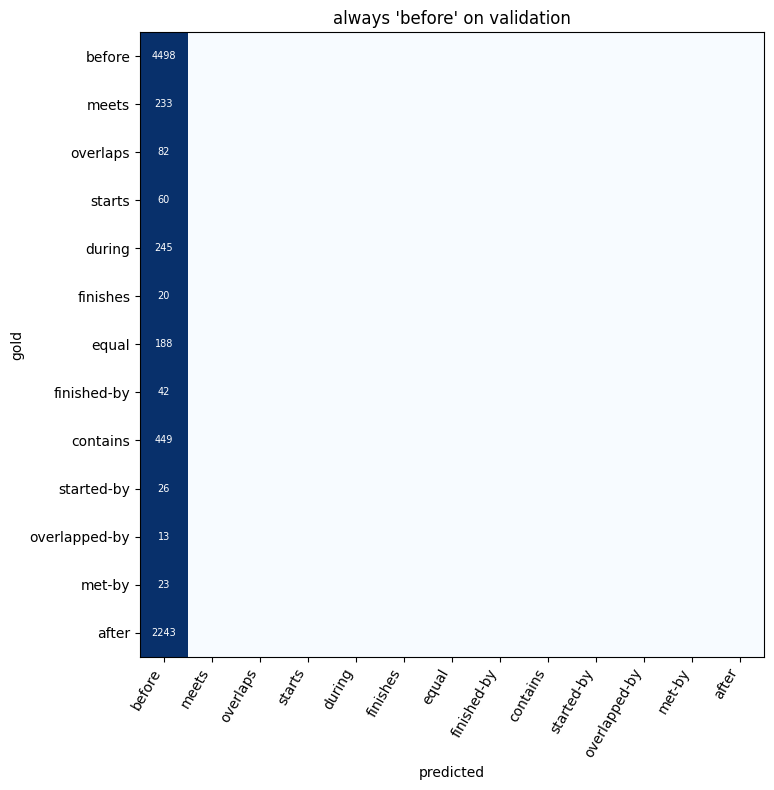

saved /kaggle/working/exp1_confusion_baseline_val.png | exists: True


In [43]:
# Cell 43 (optional): confusion-matrix heatmap of the majority baseline, saved in out_dir
png = os.path.join(CONFIG["out_dir"], f"{CONFIG['run_name']}_confusion_baseline_val.png")
plot_confusion(res_before["val"], "always 'before' on validation", save_path=png)
print("saved", png, "| exists:", os.path.exists(png))

## Step 9: full model and training loop
Cell 44: `AllenModel`, optimizer, scheduler. Cell 45: `Trainer` (training, validation, checkpoints, resume, early stopping) and `run_training`.
Cells 46-48 test it. The real training is started in the LAST cell of the notebook, after the Step 10 sanity tests. The test split is never touched.

In [44]:
# Cell 44: AllenModel, build_optimizer, lr_factor / build_scheduler (definitions only)
import math, csv, shutil, time
from torch.optim.lr_scheduler import LambdaLR

for _k in ("resume", "log_every_steps"):
    if _k not in CONFIG:
        raise KeyError(f"Cell 44: CONFIG has no '{_k}' (added in Step 9). Re-run cell 2.")


class AllenModel(TemporalModel):
    """StemEncoder (BERT + marker_embed + event mean-pooling) -> optional EventTransformer -> pair vectors -> PairMLP
    -> four endpoint heads -> constrained 13-way score. forward(batch) -> (logq [P, 4, 3], z [P, 13]).
    Batches are moved to the GPU with move_batch (cell 18)."""
    def __init__(self, cfg):
        set_seed(cfg["seed"])
        encoder = StemEncoder(cfg, cfg["bert_path"], START_ID, END_ID, len(tokenizer))
        super().__init__(encoder, EventTransformer(cfg), PairMLP(cfg), EndpointHeads(cfg))


def build_optimizer(model, cfg, verbose=True):
    """AdamW, two logical groups, each split into 'decay' (weights) and 'no_decay' (biases and LayerNorm) -> 4 torch groups.
       A = BERT (lr_bert).  B = EventTransformer, PairMLP, heads and marker_embed (lr_new)."""
    params = dict(model.named_parameters())
    frozen = [n for n, p in params.items() if not p.requires_grad]
    if frozen:
        raise ValueError(f"build_optimizer: frozen parameters found (all are expected to train): {frozen[:5]}")
    bert_ids = {id(p) for p in model.encoder.bert.parameters()}
    no_decay = {id(p) for m in model.modules() if isinstance(m, nn.LayerNorm) for p in m.parameters(recurse=False)}
    no_decay |= {id(p) for n, p in params.items() if n.endswith(".bias")}
    buckets = {"A_decay": [], "A_no_decay": [], "B_decay": [], "B_no_decay": []}
    for n, p in params.items():
        buckets[("A" if id(p) in bert_ids else "B") + ("_no_decay" if id(p) in no_decay else "_decay")].append(p)
    assert id(model.encoder.marker_embed) not in bert_ids and any(p is model.encoder.marker_embed for p in buckets["B_decay"]), \
        "build_optimizer: marker_embed must be in group B"
    spec = [("A_decay", cfg["lr_bert"], cfg["weight_decay"]), ("A_no_decay", cfg["lr_bert"], 0.0),
            ("B_decay", cfg["lr_new"], cfg["weight_decay"]), ("B_no_decay", cfg["lr_new"], 0.0)]
    opt = torch.optim.AdamW([{"params": buckets[k], "lr": lr, "weight_decay": wd, "name": k} for k, lr, wd in spec])
    n_in_groups = sum(p.numel() for g in opt.param_groups for p in g["params"])
    assert n_in_groups == sum(p.numel() for p in model.parameters()), "build_optimizer: some parameters are in no group"
    assert sum(len(g["params"]) for g in opt.param_groups) == len(params), "build_optimizer: a parameter is in two groups"
    if verbose:
        print(f"{'group':26s}{'tensors':>9s}{'parameters':>14s}{'lr':>10s}{'weight_decay':>14s}")
        for g in opt.param_groups:
            print(f"{g['name']:26s}{len(g['params']):>9d}{sum(p.numel() for p in g['params']):>14,}{g['lr']:>10.1e}{g['weight_decay']:>14.3f}")
        for tag, label in (("A", "A = BERT (lr_bert)"), ("B", "B = ET + MLP + heads + marker_embed (lr_new)")):
            gs = [g for g in opt.param_groups if g["name"].startswith(tag)]
            print(f"  group {label}: {sum(p.numel() for g in gs for p in g['params']):,} parameters, lr = {gs[0]['lr']:.1e}")
    return opt


def lr_factor(step, warmup_steps, total_steps):
    """Linear warm-up over `warmup_steps` optimizer steps (step 0 already has 1/warmup_steps), then linear decay to 0 at total_steps."""
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))


def build_scheduler(opt, total_steps, warmup_frac):
    warmup_steps = max(1, math.ceil(warmup_frac * total_steps))
    return LambdaLR(opt, lambda s: lr_factor(s, warmup_steps, total_steps)), warmup_steps


print("definitions OK | AllenModel, build_optimizer, lr_factor, build_scheduler")

definitions OK | AllenModel, build_optimizer, lr_factor, build_scheduler


In [45]:
# Cell 45: Trainer (train / validate / checkpoint / resume / early stopping) and run_training (definitions only)

class Trainer:
    """Trains `model` on train_stems and validates on val_stems (never the test split)."""
    HISTORY_COLUMNS = ["epoch", "partial", "train_total", "train_relation", "train_aux", "val_loss", "val_relation_loss", "val_aux_loss",
                       "val_macro_f1_present", "val_n_classes", "val_macro_f1_all13", "val_accuracy", "lr_bert", "lr_new",
                       "optimizer_steps", "epoch_minutes", "total_minutes", "best_so_far"]

    def __init__(self, cfg, model, train_stems, val_stems, verbose=True):
        self.cfg, self.model, self.verbose = cfg, model, verbose
        self.train_stems, self.val_stems = train_stems, val_stems
        self.lookup = {s["stem_id"]: s for s in list(train_stems) + list(val_stems)}
        self.batches_per_epoch = math.ceil(len(train_stems) / cfg["stems_per_step"])
        self.steps_per_epoch = math.ceil(self.batches_per_epoch / cfg["accum_steps"])
        self.total_steps = cfg["max_epochs"] * self.steps_per_epoch
        self.opt = build_optimizer(model, cfg, verbose=verbose)
        self.sched, self.warmup_steps = build_scheduler(self.opt, self.total_steps, cfg["warmup_frac"])
        self.scaler = torch.amp.GradScaler("cuda", enabled=cfg["use_amp"])
        self.loss_w = make_loss_weights(cfg, CLASS_WEIGHTS, DEVICE)
        self.ckpt_dir = os.path.join(cfg["out_dir"], cfg["run_name"])
        os.makedirs(self.ckpt_dir, exist_ok=True)
        self.history_path = os.path.join(cfg["out_dir"], f"{cfg['run_name']}_history.csv")
        self.history, self.step_log = [], []
        self.best, self.best_epoch, self.epochs_since_improve = -1.0, -1, 0
        self.start_epoch, self.skip_batches = 0, 0
        self.skipped_micro, self.skipped_steps, self.overflow_steps = 0, 0, 0
        self.stop_reason = None
        self.session_start = time.time()
        if verbose:
            print(f"train stems {len(train_stems)} -> {self.batches_per_epoch} micro-batches/epoch -> {self.steps_per_epoch} optimizer steps/epoch; "
                  f"total {self.total_steps} steps over {cfg['max_epochs']} epochs; warm-up {self.warmup_steps} steps; "
                  f"effective batch = {cfg['stems_per_step']} x {cfg['accum_steps']} stems")
        if cfg["resume"]:
            self.load_checkpoint(cfg["resume"])

    # ------------------------------------------------------------------ helpers
    def minutes(self):
        return (time.time() - self.session_start) / 60

    def time_exceeded(self):
        return (time.time() - self.session_start) / 3600 > self.cfg["max_run_hours"]

    def lrs(self):
        return self.opt.param_groups[0]["lr"], self.opt.param_groups[2]["lr"]          # A_decay, B_decay (the no_decay groups share them)

    def report_oom(self, stem_ids, where):
        print(f"\n!!! CUDA out of memory during {where}. Failing batch: stem_ids = {stem_ids}")
        tot_win = 0
        for sid in stem_ids:
            s = self.lookup[sid]
            wt = sum(len(w["input_ids"]) for w in s["windows"])
            tot_win += len(s["windows"])
            print(f"    stem {sid}: events={len(s['events'])} pairs={len(s['pairs'])} windows={len(s['windows'])} "
                  f"window tokens={wt} token_count={s['token_count']}")
        print(f"    batch: {len(stem_ids)} stems, {tot_win} windows | GPU allocated {torch.cuda.memory_allocated() / 1024**3:.2f} GiB, "
              f"peak {torch.cuda.max_memory_allocated() / 1024**3:.2f} GiB")
        print("    options: set use_grad_ckpt=True, or windows_per_chunk to a small integer, or stems_per_step=1 with a larger accum_steps\n")

    # ------------------------------------------------------------------ one micro-batch
    def micro_step(self, batch, gsize):
        """forward + loss + backward of one micro-batch. Returns (total, rel, aux) floats, or None if the loss was not finite."""
        batch = move_batch(batch, DEVICE)
        try:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=self.cfg["use_amp"]):
                logq, z = self.model(batch)
            try:
                total, rel, aux = compute_loss(logq, z, batch, self.loss_w, self.cfg["lambda_aux"], reduction=self.cfg["loss_reduction"])
            except FloatingPointError as err:
                self.skipped_micro += 1
                print(f"WARNING: micro-batch skipped (stems {batch['stem_ids']}): {err}")
                return None
            self.scaler.scale(total / gsize).backward()                                # gsize = micro-batches in this accumulation group
        except torch.cuda.OutOfMemoryError:
            self.report_oom(batch["stem_ids"], "training")
            raise
        return total.item(), rel.item(), aux.item()

    def optimizer_step(self, grp):
        """unscale, clip, step, scheduler step. Returns True if the weights were updated."""
        cfg = self.cfg
        if grp["n"] == 0:
            print("WARNING: every micro-batch of this accumulation group had a non-finite loss; optimizer step skipped")
            self.opt.zero_grad(set_to_none=True)
            self.skipped_steps += 1
            return False
        lr_a, lr_b = self.lrs()
        self.scaler.unscale_(self.opt)
        gnorm = torch.nn.utils.clip_grad_norm_(self.model.parameters(), cfg["grad_clip"]).item()
        if not cfg["use_amp"] and not math.isfinite(gnorm):
            print(f"WARNING: non-finite gradient norm ({gnorm}); optimizer step skipped")
            self.opt.zero_grad(set_to_none=True)
            self.skipped_steps += 1
            return False
        scale_before = self.scaler.get_scale()
        self.scaler.step(self.opt)                                                      # skipped by the scaler on fp16 overflow
        self.scaler.update()
        self.opt.zero_grad(set_to_none=True)
        if cfg["use_amp"] and self.scaler.get_scale() < scale_before:
            self.overflow_steps += 1                                                    # overflow: weights not updated, scheduler not advanced
            return False
        self.sched.step()
        self.step_log.append({"step": self.sched.last_epoch, "t": time.time(), "lr_bert": lr_a, "lr_new": lr_b, "grad_norm": gnorm,
                              "total": grp["total"] / grp["n"], "relation": grp["rel"] / grp["n"], "aux": grp["aux"] / grp["n"]})
        return True

    # ------------------------------------------------------------------ one epoch
    def run_epoch(self, epoch, skip_batches=0, max_opt_steps=None, stems=None):
        cfg, accum = self.cfg, self.cfg["accum_steps"]
        self.model.train()
        loader = build_loader(self.train_stems if stems is None else stems, shuffle=True, seed=cfg["seed"], epoch=epoch)
        nb = len(loader)
        if skip_batches >= nb and skip_batches > 0:
            raise ValueError(f"run_epoch: cannot skip {skip_batches} of {nb} micro-batches")
        keys = ("total", "rel", "aux")
        ep = dict.fromkeys(keys, 0.0); ep_n = 0
        run = dict.fromkeys(keys, 0.0); run_n = 0
        grp = dict.fromkeys(keys, 0.0); grp["n"] = 0
        self.opt.zero_grad(set_to_none=True)
        steps_here, batches_done, stopped = 0, skip_batches, None
        for b_idx, batch in enumerate(loader):
            if b_idx < skip_batches:
                continue                                                                # resume inside an epoch: same order, skip what was done
            gsize = min(accum, nb - (b_idx // accum) * accum)
            out = self.micro_step(batch, gsize)
            batches_done = b_idx + 1
            if out is not None:
                for k, v in zip(keys, out):
                    grp[k] += v; ep[k] += v; run[k] += v
                grp["n"] += 1; ep_n += 1; run_n += 1
            if batches_done % accum == 0 or batches_done == nb:
                stepped = self.optimizer_step(grp)
                grp = dict.fromkeys(keys, 0.0); grp["n"] = 0
                if stepped:
                    steps_here += 1
                    if self.sched.last_epoch % cfg["log_every_steps"] == 0 and run_n:
                        lr_a, lr_b = self.step_log[-1]["lr_bert"], self.step_log[-1]["lr_new"]
                        print(f"epoch {epoch + 1:2d}/{cfg['max_epochs']} | step {self.sched.last_epoch:5d}/{self.total_steps} | "
                              f"lr bert {lr_a:.2e} new {lr_b:.2e} | loss {run['total'] / run_n:.4f} (rel {run['rel'] / run_n:.4f}, "
                              f"aux {run['aux'] / run_n:.4f}) | grad norm {self.step_log[-1]['grad_norm']:.2f} | {self.minutes():.1f} min")
                        run = dict.fromkeys(keys, 0.0); run_n = 0
                if max_opt_steps is not None and steps_here >= max_opt_steps:
                    stopped = "max_opt_steps"
                    break
                if batches_done < nb and self.time_exceeded():
                    stopped = "max_run_hours"
                    break
        n = max(ep_n, 1)
        return {"epoch": epoch, "batches_done": batches_done, "n_batches": nb, "completed": batches_done == nb, "stopped": stopped,
                "train_total": ep["total"] / n, "train_relation": ep["rel"] / n, "train_aux": ep["aux"] / n, "steps": steps_here}

    def validate(self):
        try:
            return evaluate(self.model, self.val_stems, self.cfg)
        except torch.cuda.OutOfMemoryError:
            print("\n!!! CUDA out of memory during validation (stems_per_step validation stems per batch); validation stem_ids:",
                  [s["stem_id"] for s in self.val_stems][:10], "...")
            raise

    # ------------------------------------------------------------------ checkpoints
    def save_history_csv(self):
        with open(self.history_path, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=self.HISTORY_COLUMNS)
            w.writeheader()
            w.writerows(self.history)

    def save_checkpoint(self, epoch, completed, batches_done, improved):
        ck = {"model": self.model.state_dict(), "optimizer": self.opt.state_dict(), "scheduler": self.sched.state_dict(),
              "scaler": self.scaler.state_dict(), "epoch": epoch, "epoch_completed": completed, "batches_done": batches_done,
              "best_score": self.best, "best_epoch": self.best_epoch, "epochs_since_improve": self.epochs_since_improve,
              "optimizer_steps": self.sched.last_epoch, "config": self.cfg, "history": self.history}
        last = os.path.join(self.ckpt_dir, "last.pt")
        torch.save(ck, last + ".tmp"); os.replace(last + ".tmp", last)                 # atomic: never a half-written last.pt
        if improved:
            best = os.path.join(self.ckpt_dir, "best.pt")
            shutil.copyfile(last, best + ".tmp"); os.replace(best + ".tmp", best)      # same content, saved when val macro-F1 improved
        return last

    def load_checkpoint(self, path):
        if not os.path.isfile(path):
            raise FileNotFoundError(f"load_checkpoint: no such file {path!r}")
        ck = torch.load(path, map_location="cpu", weights_only=False)                  # our own file: contains CONFIG and history, not only tensors
        arch_keys = ["use_event_transformer", "et_layers", "et_heads", "et_ff", "mlp_hidden", "stems_per_step", "accum_steps", "seed"]
        bad = [k for k in arch_keys if ck["config"].get(k) != self.cfg.get(k)]
        if bad:
            raise ValueError(f"load_checkpoint: CONFIG differs from the checkpoint in {[(k, ck['config'].get(k), self.cfg.get(k)) for k in bad]}")
        soft = [k for k in ck["config"] if k not in ("resume", "run_name", "out_dir") and ck["config"][k] != self.cfg.get(k)]
        if soft:
            print(f"load_checkpoint: NOTE these CONFIG values differ from the checkpoint (the current ones are used where they matter): "
                  f"{[(k, ck['config'][k], self.cfg.get(k)) for k in soft]}")
        self.model.load_state_dict(ck["model"])
        self.opt.load_state_dict(ck["optimizer"])
        self.sched.load_state_dict(ck["scheduler"])
        base = {"A": self.cfg["lr_bert"], "B": self.cfg["lr_new"]}                     # re-apply the CURRENT config and schedule: the saved lr
        self.sched.base_lrs = [base[g["name"][0]] for g in self.opt.param_groups]       # belongs to the old total_steps / old base lrs
        for g, b in zip(self.opt.param_groups, self.sched.base_lrs):
            g["initial_lr"] = b
            g["lr"] = b * lr_factor(self.sched.last_epoch, self.warmup_steps, self.total_steps)
        if ck["scaler"]:
            self.scaler.load_state_dict(ck["scaler"])
        else:
            print("load_checkpoint: the checkpoint has no GradScaler state (it was trained without AMP)")
        self.history, self.best, self.best_epoch = ck["history"], ck["best_score"], ck["best_epoch"]
        self.epochs_since_improve = ck["epochs_since_improve"]
        if ck["epoch_completed"]:
            self.start_epoch, self.skip_batches = ck["epoch"] + 1, 0
        else:
            self.start_epoch, self.skip_batches = ck["epoch"], ck["batches_done"]
        print(f"resumed from {path}: epoch {ck['epoch'] + 1} {'finished' if ck['epoch_completed'] else 'interrupted after ' + str(ck['batches_done']) + ' micro-batches'}, "
              f"{ck['optimizer_steps']} optimizer steps done, best macro_f1_present {self.best:.4f} (epoch {self.best_epoch + 1}); "
              f"next: epoch {self.start_epoch + 1}, skipping {self.skip_batches} micro-batches")
        return ck

    # ------------------------------------------------------------------ the whole run
    def fit(self):
        cfg = self.cfg
        self.session_start = time.time()
        epoch, skip = self.start_epoch, self.skip_batches
        epoch_minutes = []
        if epoch >= cfg["max_epochs"]:
            self.stop_reason = "max_epochs already reached"
            print("nothing to do: the checkpoint is already at max_epochs")
        if epoch < cfg["max_epochs"] and self.epochs_since_improve >= cfg["patience"]:
            self.stop_reason = "early stopping (already reached when the checkpoint was saved)"
            print(f"nothing to do: the checkpoint had already stopped by early stopping ({self.epochs_since_improve} epochs without improvement)")
            epoch = cfg["max_epochs"]                                                   # skip the training loop
        while epoch < cfg["max_epochs"]:
            if epoch_minutes and self.minutes() / 60 + max(epoch_minutes) / 60 > cfg["max_run_hours"]:
                self.stop_reason = "max_run_hours (the next epoch would not fit)"
                break
            t0 = time.time()
            info = self.run_epoch(epoch, skip_batches=skip)
            skip = 0
            res = self.validate()
            m = res["metrics"]
            partial = not info["completed"]
            improved = m["macro_f1_present"] > self.best
            if improved:
                self.best, self.best_epoch = m["macro_f1_present"], epoch
            if not partial:
                self.epochs_since_improve = 0 if improved else self.epochs_since_improve + 1
            lr_a, lr_b = self.lrs()
            row = {"epoch": epoch + 1, "partial": partial, "train_total": info["train_total"], "train_relation": info["train_relation"],
                   "train_aux": info["train_aux"], "val_loss": res["loss"], "val_relation_loss": res["relation_loss"], "val_aux_loss": res["aux_loss"],
                   "val_macro_f1_present": m["macro_f1_present"], "val_n_classes": m["n_classes_present"], "val_macro_f1_all13": m["macro_f1_all13"],
                   "val_accuracy": m["accuracy"], "lr_bert": lr_a, "lr_new": lr_b, "optimizer_steps": self.sched.last_epoch,
                   "epoch_minutes": (time.time() - t0) / 60, "total_minutes": self.minutes(), "best_so_far": self.best}
            self.history.append(row)
            self.save_history_csv()
            self.save_checkpoint(epoch, not partial, info["batches_done"], improved)
            epoch_minutes.append(row["epoch_minutes"])
            print(f"=== epoch {epoch + 1}/{cfg['max_epochs']}{' (PARTIAL)' if partial else ''} | train loss {info['train_total']:.4f} | "
                  f"val macro_f1_present {m['macro_f1_present']:.4f} over {m['n_classes_present']} classes | accuracy {m['accuracy']:.4f} | val loss {res['loss']:.4f} | "
                  f"best {self.best:.4f} (epoch {self.best_epoch + 1}){' NEW BEST, best.pt saved' if improved else ''} | no-improve {self.epochs_since_improve}/{cfg['patience']} | "
                  f"{row['epoch_minutes']:.1f} min, total {row['total_minutes']:.1f} min ===")
            if partial:
                self.stop_reason = "max_run_hours (stopped inside the epoch; resume continues it)"
                break
            if self.epochs_since_improve >= cfg["patience"]:
                self.stop_reason = "early stopping"
                break
            if self.time_exceeded():
                self.stop_reason = "max_run_hours"
                break
            epoch += 1
        else:
            self.stop_reason = self.stop_reason or "max_epochs reached"
        print(f"\nTRAINING STOPPED: {self.stop_reason} | best validation macro_f1_present = {self.best:.4f} (epoch {self.best_epoch + 1}) | "
              f"skipped micro-batches {self.skipped_micro}, skipped steps {self.skipped_steps}, fp16 overflow steps {self.overflow_steps}")
        return self.history, self.best


def run_training(cfg):
    """Fresh AllenModel + Trainer on train/validation (resumes if cfg['resume'] is set). Returns (history, best_validation_macro_f1_present)."""
    model = AllenModel(cfg).to(DEVICE)
    trainer = Trainer(cfg, model, DATA["train"], DATA["val"])
    history, best = trainer.fit()
    return history, best


print("definitions OK | Trainer, run_training")

definitions OK | Trainer, run_training


In [46]:
# Cell 46: build the model, optimizer and scheduler; print the groups; check the learning-rate schedule (no training yet)
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
TRAIN_MODEL = AllenModel(CONFIG).to(DEVICE)
print("AllenModel parameters:", f"{sum(p.numel() for p in TRAIN_MODEL.parameters()):,}", "\n")
TRAINER = Trainer(CONFIG, TRAIN_MODEL, DATA["train"], DATA["val"])
assert not any(p.requires_grad is False for p in TRAIN_MODEL.parameters())

# decay rule: biases and LayerNorm in the no-decay groups
names = {id(p): n for n, p in TRAIN_MODEL.named_parameters()}
for g in TRAINER.opt.param_groups:
    sample = [names[id(p)] for p in g["params"]][:2]
    print(f"  {g['name']:11s} e.g. {sample}")
    if g["name"].endswith("_no_decay"):
        assert all(names[id(p)].endswith(".bias") or "LayerNorm" in names[id(p)] or "norm" in names[id(p)] for p in g["params"]), \
            f"Cell 46: a weight matrix is in {g['name']}"
    else:
        assert not any(names[id(p)].endswith(".bias") or "LayerNorm" in names[id(p)] or ".norm" in names[id(p)] for p in g["params"]),             f"Cell 46: a bias or LayerNorm weight is in {g['name']}"

# schedule shape
tot, warm = TRAINER.total_steps, TRAINER.warmup_steps
f = [lr_factor(s, warm, tot) for s in range(tot + 1)]
assert all(f[s] < f[s + 1] for s in range(warm - 1)), "Cell 46: the warm-up is not strictly increasing"
assert abs(f[warm - 1] - 1.0) < 1e-12 and max(f) == 1.0 and f[tot] == 0.0
assert all(f[s] >= f[s + 1] for s in range(warm, tot)), "Cell 46: the decay is not monotonic"
print(f"\nschedule: {warm} warm-up steps, {tot} total steps")
print(f"{'step':>6s}{'factor':>9s}{'lr bert':>11s}{'lr new':>11s}")
for s in (0, warm // 2, warm - 1, warm, tot // 2, tot - 1, tot):
    print(f"{s:>6d}{f[s]:>9.4f}{CONFIG['lr_bert'] * f[s]:>11.2e}{CONFIG['lr_new'] * f[s]:>11.2e}")
assert abs(TRAINER.lrs()[0] - CONFIG["lr_bert"] * f[0]) < 1e-15 and abs(TRAINER.lrs()[1] - CONFIG["lr_new"] * f[0]) < 1e-15
print(f"initial optimizer lrs: bert {TRAINER.lrs()[0]:.3e}, new {TRAINER.lrs()[1]:.3e} (= base x {f[0]:.4f})")
print("OPTIMIZER / SCHEDULER CHECKS PASSED")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AllenModel parameters: 123,606,284 

group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                          14    15,868,928   1.0e-04         0.010
B_no_decay                       17        16,140   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 15,885,068 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
  A_decay     e.g. ['encoder.bert.embeddings.word_embeddings.weight', 'encoder.bert.embeddings.position_embeddings.weight']
  A_no_decay  e.g. ['encoder.bert.embeddings.LayerNorm.weight', 'encoder.bert.embeddings.LayerNorm.bias']
  B_decay     e.g. ['encoder.marker_embed', 'event_trans

In [47]:
# Cell 47: 2 optimizer steps (loss and lr), then save last.pt, reload it into another model, compare one forward pass
tr = TRAINER
if "smoke_max_groups" not in CONFIG:
    raise KeyError("Cell 47: CONFIG has no 'smoke_max_groups'. Re-run cell 2.")
n_train = CONFIG["smoke_max_groups"] * CONFIG["accum_steps"] * CONFIG["stems_per_step"]   # spare stems: with fp16 the GradScaler may skip the first steps (overflow)
short_train = sorted(DATA["train"], key=lambda s: s["token_count"])[:n_train]       # the shortest stems: a quick test
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
info = tr.run_epoch(0, max_opt_steps=2, stems=short_train)                          # stops after 2 SUCCESSFUL optimizer steps
print(f"ran {info['steps']} optimizer steps over {info['batches_done']} micro-batches ({info['batches_done'] * CONFIG['stems_per_step']} stems)")
print(f"skipped steps: fp16 overflow {tr.overflow_steps}, non-finite {tr.skipped_steps}; skipped micro-batches {tr.skipped_micro}; "
      f"GradScaler scale now {tr.scaler.get_scale():g}  (a few skipped steps at the start of fp16 training are normal)")
print(f"{'step':>5s}{'lr bert':>11s}{'lr new':>11s}{'total':>9s}{'relation':>10s}{'aux':>8s}{'grad norm':>11s}")
for r in tr.step_log:
    print(f"{r['step']:>5d}{r['lr_bert']:>11.3e}{r['lr_new']:>11.3e}{r['total']:>9.4f}{r['relation']:>10.4f}{r['aux']:>8.4f}{r['grad_norm']:>11.3f}")
if len(tr.step_log) != 2 or tr.sched.last_epoch != 2:
    raise RuntimeError(f"Cell 47: only {len(tr.step_log)} of the 2 optimizer steps succeeded within {info['batches_done']} micro-batches "
                       f"(fp16 overflow skips {tr.overflow_steps}, non-finite skips {tr.skipped_steps}, skipped micro-batches {tr.skipped_micro}). "
                       f"If almost every step overflowed, fp16 training is unstable here: set CONFIG['use_amp']=False and re-run to compare; "
                       f"if micro-batches were skipped, look at the warnings printed above.")
assert 0 < tr.step_log[0]["lr_bert"] < tr.step_log[1]["lr_bert"] and 0 < tr.step_log[0]["lr_new"] < tr.step_log[1]["lr_new"], \
    "Cell 47: the learning rate does not rise during warm-up"
assert all(math.isfinite(r["total"]) and math.isfinite(r["grad_norm"]) for r in tr.step_log)
print(f"WARM-UP CHECK PASSED: lr bert {tr.step_log[0]['lr_bert']:.2e} -> {tr.step_log[1]['lr_bert']:.2e}, "
      f"lr new {tr.step_log[0]['lr_new']:.2e} -> {tr.step_log[1]['lr_new']:.2e}; next lrs {tr.lrs()[0]:.2e}, {tr.lrs()[1]:.2e}")
if DEVICE.type == "cuda":
    print(f"peak GPU memory in these steps: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GiB")

# ---- save last.pt and reload it into a DIFFERENT model (other seed) ----
tr.ckpt_dir = os.path.join(CONFIG["out_dir"], CONFIG["run_name"] + "_smoketest")
os.makedirs(tr.ckpt_dir, exist_ok=True)
path = tr.save_checkpoint(epoch=0, completed=True, batches_done=info["batches_done"], improved=False)
print(f"saved {path} ({os.path.getsize(path) / 1024**3:.2f} GiB)")
ck_keys = set(torch.load(path, map_location="cpu", weights_only=False))
assert {"model", "optimizer", "scheduler", "scaler", "epoch", "best_score", "config", "history"} <= ck_keys, f"Cell 47: checkpoint keys {ck_keys}"

val_two = sorted(DATA["val"], key=lambda s: s["token_count"])[:2]
VB = move_batch(collate_stems(val_two), DEVICE)
tr.model.eval()
with torch.no_grad():
    lq1, z1 = tr.model(VB)
model2 = AllenModel({**CONFIG, "seed": CONFIG["seed"] + 1}).to(DEVICE)             # different initialisation on purpose
tr2 = Trainer({**CONFIG, "run_name": CONFIG["run_name"] + "_smoketest", "resume": None}, model2, DATA["train"], DATA["val"], verbose=False)
model2.eval()
with torch.no_grad():
    _, z_before = model2(VB)
assert not torch.allclose(z_before, z1), "Cell 47: the second model should differ before loading"
tr2.load_checkpoint(path)
model2.eval()
with torch.no_grad():
    lq2, z2 = model2(VB)
print(f"max |z_after_load - z_original| = {(z2 - z1).abs().max().item():.1e} | max |logq diff| = {(lq2 - lq1).abs().max().item():.1e} "
      f"(before loading: {(z_before - z1).abs().max().item():.2f})")
assert torch.equal(z1, z2) and torch.equal(lq1, lq2), "Cell 47: outputs differ after reloading last.pt"
assert tr2.sched.last_epoch == tr.sched.last_epoch == 2 and tr2.lrs() == tr.lrs(), "Cell 47: scheduler state not restored"
p1, p2 = tr.opt.param_groups[0]["params"][0], tr2.opt.param_groups[0]["params"][0]
assert torch.equal(tr.opt.state[p1]["exp_avg"], tr2.opt.state[p2]["exp_avg"]), "Cell 47: optimizer state not restored"
assert tr2.scaler.get_scale() == tr.scaler.get_scale() and tr2.start_epoch == 1 and tr2.skip_batches == 0
print("CHECKPOINT RELOAD TEST PASSED: identical logq and z in eval mode; optimizer, scheduler and scaler restored; next epoch = 2")

shutil.rmtree(tr.ckpt_dir)
for f_ in (tr.history_path,):
    if os.path.exists(f_):
        os.remove(f_)
del tr, tr2, model2, TRAINER, TRAIN_MODEL, lq1, lq2, z1, z2, z_before, VB
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

ran 2 optimizer steps over 16 micro-batches (32 stems)
skipped steps: fp16 overflow 2, non-finite 0; skipped micro-batches 0; GradScaler scale now 16384  (a few skipped steps at the start of fp16 training are normal)
 step    lr bert     lr new    total  relation     aux  grad norm
    1  3.333e-07  1.667e-06   5.2248    2.7735  4.9027     53.811
    2  6.667e-07  3.333e-06   5.1821    2.7532  4.8578     49.166
WARM-UP CHECK PASSED: lr bert 3.33e-07 -> 6.67e-07, lr new 1.67e-06 -> 3.33e-06; next lrs 1.00e-06, 5.00e-06
peak GPU memory in these steps: 2.89 GiB
saved /kaggle/working/exp1_smoketest/last.pt (1.38 GiB)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resumed from /kaggle/working/exp1_smoketest/last.pt: epoch 1 finished, 2 optimizer steps done, best macro_f1_present -1.0000 (epoch 0); next: epoch 2, skipping 0 micro-batches
max |z_after_load - z_original| = 0.0e+00 | max |logq diff| = 0.0e+00 (before loading: 2.53)
CHECKPOINT RELOAD TEST PASSED: identical logq and z in eval mode; optimizer, scheduler and scaler restored; next epoch = 2


In [48]:
# Cell 48 (extra, optional, a few minutes): smoke test of fit(): history.csv, best/last, resume, early stopping, time limit
shortest = lambda stems, k: sorted(stems, key=lambda s: s["token_count"])[:k]
S_TRAIN = shortest(DATA["train"], 2 * CONFIG["accum_steps"] * CONFIG["stems_per_step"])        # 2 optimizer steps per epoch
S_VAL = shortest(DATA["val"], 3)
# fp32 on purpose: this test counts exact optimizer steps, and the fp16 GradScaler skips some steps at the start (overflow); fp16 is covered by cell 47
base = {**CONFIG, "run_name": CONFIG["run_name"] + "_smoke", "resume": None, "log_every_steps": 1, "patience": 3, "use_amp": False}
smoke_dir = os.path.join(CONFIG["out_dir"], base["run_name"])

def read_history(cfg):
    with open(os.path.join(cfg["out_dir"], f"{cfg['run_name']}_history.csv"), encoding="utf-8") as f:
        return list(csv.DictReader(f))

def fresh_run(cfg, stems=S_TRAIN):
    m = AllenModel(cfg).to(DEVICE)
    t = Trainer(cfg, m, stems, S_VAL, verbose=False)
    return m, t

def cleanup(cfg):
    shutil.rmtree(os.path.join(cfg["out_dir"], cfg["run_name"]), ignore_errors=True)
    p = os.path.join(cfg["out_dir"], f"{cfg['run_name']}_history.csv")
    if os.path.exists(p):
        os.remove(p)

# (a) two epochs: history.csv, best.pt, last.pt
cfg_a = {**base, "max_epochs": 2}
m, t = fresh_run(cfg_a)
hist, best = t.fit()
rows = read_history(cfg_a)
assert len(hist) == len(rows) == 2 and [r["epoch"] for r in rows] == ["1", "2"], "Cell 48(a): history.csv"
assert os.path.exists(os.path.join(smoke_dir, "last.pt")) and os.path.exists(os.path.join(smoke_dir, "best.pt"))
ck = torch.load(os.path.join(smoke_dir, "last.pt"), map_location="cpu", weights_only=False)
assert ck["epoch"] == 1 and ck["epoch_completed"] and abs(ck["best_score"] - best) < 1e-12 and len(ck["history"]) == 2
assert abs(best - max(float(r["val_macro_f1_present"]) for r in rows)) < 1e-12
print(f"(a) OK: 2 epochs, history.csv rows = {len(rows)}, best = {best:.4f}, columns = {list(rows[0])[:6]}...\n")
del m, t, ck; gc.collect()

# (b) resume from last.pt and train a third epoch
cfg_b = {**base, "max_epochs": 3, "resume": os.path.join(smoke_dir, "last.pt")}
m, t = fresh_run(cfg_b)
want = CONFIG["lr_bert"] * lr_factor(4, t.warmup_steps, t.total_steps)               # 4 steps done, new total = 3 epochs x 2 steps
assert abs(t.lrs()[0] - want) < 1e-15 and t.lrs()[0] > 0, f"Cell 48(b): lr after resume is {t.lrs()[0]}, expected {want}"
hist, best_b = t.fit()
assert [h["epoch"] for h in hist] == [1, 2, 3] and t.sched.last_epoch == 3 * t.steps_per_epoch, "Cell 48(b): resume"
print(f"(b) OK: resumed and ran epoch 3 only; history epochs = {[h['epoch'] for h in hist]}, optimizer steps = {t.sched.last_epoch}\n")
del m, t; gc.collect(); cleanup(base)

# (c) early stopping: lr ~ 0 so the validation score cannot improve; patience 1
cfg_c = {**base, "run_name": base["run_name"] + "_es", "max_epochs": 5, "patience": 1, "lr_bert": 1e-12, "lr_new": 1e-12}
m, t = fresh_run(cfg_c)
hist, best_c = t.fit()
assert t.stop_reason == "early stopping" and len(hist) == 2, f"Cell 48(c): stop_reason={t.stop_reason!r}, epochs={len(hist)}"
print(f"(c) OK: early stopping after {len(hist)} epochs (patience 1, no improvement)\n")
del m, t; gc.collect(); cleanup(cfg_c)

# (d) time limit inside an epoch -> partial last.pt; resume finishes that epoch
cfg_d = {**base, "run_name": base["run_name"] + "_time", "max_epochs": 1, "max_run_hours": 1e-9}
m, t = fresh_run(cfg_d)
hist, _ = t.fit()
assert hist[-1]["partial"] and "max_run_hours" in t.stop_reason and t.sched.last_epoch == 1, f"Cell 48(d): {t.stop_reason!r}"
ck = torch.load(os.path.join(CONFIG["out_dir"], cfg_d["run_name"], "last.pt"), map_location="cpu", weights_only=False)
assert not ck["epoch_completed"] and ck["batches_done"] == CONFIG["accum_steps"], "Cell 48(d): last.pt of a partial epoch"
print(f"(d1) OK: stopped after {t.sched.last_epoch} optimizer step ({ck['batches_done']} micro-batches), last.pt saved with epoch_completed=False\n")
del m, t, ck; gc.collect()
cfg_d2 = {**cfg_d, "max_run_hours": CONFIG["max_run_hours"], "resume": os.path.join(CONFIG["out_dir"], cfg_d["run_name"], "last.pt")}
m, t = fresh_run(cfg_d2)
hist, _ = t.fit()
assert [h["partial"] for h in hist] == [True, False] and t.sched.last_epoch == 2 and t.lrs()[0] == 0.0, "Cell 48(d2): resume inside the epoch"
print(f"(d2) OK: resumed inside epoch 1, finished it; optimizer steps = {t.sched.last_epoch}; final lr = {t.lrs()[0]}\n")
del m, t; gc.collect(); cleanup(cfg_d)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("SMOKE FIT PASSED: history.csv, best.pt/last.pt, resume, early stopping, time limit with mid-epoch resume")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch  1/2 | step     1/4 | lr bert 2.00e-05 new 1.00e-04 | loss 5.1674 (rel 2.7179, aux 4.8989) | grad norm 62.87 | 0.0 min
epoch  1/2 | step     2/4 | lr bert 2.00e-05 new 1.00e-04 | loss 4.1823 (rel 2.2665, aux 3.8316) | grad norm 16.76 | 0.0 min
=== epoch 1/2 | train loss 4.6748 | val macro_f1_present 0.1097 over 8 classes | accuracy 0.7818 | val loss 3.2465 | best 0.1097 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.0 min, total 0.0 min ===
epoch  2/2 | step     3/4 | lr bert 1.33e-05 new 6.67e-05 | loss 3.4821 (rel 2.0231, aux 2.9180) | grad norm 9.24 | 0.0 min
epoch  2/2 | step     4/4 | lr bert 6.67e-06 new 3.33e-05 | loss 3.3549 (rel 2.0747, aux 2.5603) | grad norm 7.95 | 0.1 min
=== epoch 2/2 | train loss 3.4185 | val macro_f1_present 0.1097 over 8 classes | accuracy 0.7818 | val loss 3.0334 | best 0.1097 (epoch 1) | no-improve 1/3 | 0.0 min, total 0.1 min ===

TRAINING STOPPED: max_epochs reached | best validation macro_f1_present = 0.1097 (epoch 1) | skipped micro-

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


load_checkpoint: NOTE these CONFIG values differ from the checkpoint (the current ones are used where they matter): [('max_epochs', 2, 3)]
load_checkpoint: the checkpoint has no GradScaler state (it was trained without AMP)
resumed from /kaggle/working/exp1_smoke/last.pt: epoch 2 finished, 4 optimizer steps done, best macro_f1_present 0.1097 (epoch 1); next: epoch 3, skipping 0 micro-batches
epoch  3/3 | step     5/6 | lr bert 8.00e-06 new 4.00e-05 | loss 3.3503 (rel 2.1573, aux 2.3860) | grad norm 7.91 | 0.0 min
epoch  3/3 | step     6/6 | lr bert 4.00e-06 new 2.00e-05 | loss 3.1342 (rel 2.0100, aux 2.2483) | grad norm 4.99 | 0.0 min
=== epoch 3/3 | train loss 3.2423 | val macro_f1_present 0.1097 over 8 classes | accuracy 0.7818 | val loss 2.9508 | best 0.1097 (epoch 1) | no-improve 2/3 | 0.0 min, total 0.0 min ===

TRAINING STOPPED: max_epochs reached | best validation macro_f1_present = 0.1097 (epoch 1) | skipped micro-batches 0, skipped steps 0, fp16 overflow steps 0
(b) OK: resume

... (5 outputs left out)

epoch  1/1 | step     1/2 | lr bert 2.00e-05 new 1.00e-04 | loss 5.1674 (rel 2.7179, aux 4.8989) | grad norm 62.87 | 0.0 min
=== epoch 1/1 (PARTIAL) | train loss 5.1674 | val macro_f1_present 0.1097 over 8 classes | accuracy 0.7818 | val loss 3.8879 | best 0.1097 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.0 min, total 0.0 min ===

TRAINING STOPPED: max_run_hours (stopped inside the epoch; resume continues it) | best validation macro_f1_present = 0.1097 (epoch 1) | skipped micro-batches 0, skipped steps 0, fp16 overflow steps 0
(d1) OK: stopped after 1 optimizer step (4 micro-batches), last.pt saved with epoch_completed=False



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


load_checkpoint: NOTE these CONFIG values differ from the checkpoint (the current ones are used where they matter): [('max_run_hours', 1e-09, 8.0)]
load_checkpoint: the checkpoint has no GradScaler state (it was trained without AMP)
resumed from /kaggle/working/exp1_smoke_time/last.pt: epoch 1 interrupted after 4 micro-batches, 1 optimizer steps done, best macro_f1_present 0.1097 (epoch 1); next: epoch 1, skipping 4 micro-batches
epoch  1/1 | step     2/2 | lr bert 2.00e-05 new 1.00e-04 | loss 4.1713 (rel 2.2598, aux 3.8230) | grad norm 16.63 | 0.0 min
=== epoch 1/1 | train loss 4.1713 | val macro_f1_present 0.1097 over 8 classes | accuracy 0.7818 | val loss 3.2470 | best 0.1097 (epoch 1) | no-improve 1/3 | 0.0 min, total 0.0 min ===

TRAINING STOPPED: max_epochs reached | best validation macro_f1_present = 0.1097 (epoch 1) | skipped micro-batches 0, skipped steps 0, fp16 overflow steps 0
(d2) OK: resumed inside epoch 1, finished it; optimizer steps = 2; final lr = 0.0

SMOKE FIT PASSE

## Step 10: sanity tests before any real training
Test A (cell 49): gradients reach every part. Test B (cell 50): overfit 4 stems. Test C (cell 51): baselines to beat.
Test D (cell 52): cost estimate with 20 real optimizer steps. Cell 53 prints PASS / FAIL for each test. Cell 54 starts the real training; run it only after all four tests passed.

In [49]:
# Cell 49: TEST A - gradients reach every part of the model (one forward + backward pass on one real batch)
SANITY = {}
for _k in ("sanity_overfit_stems", "sanity_overfit_steps", "sanity_overfit_acc_min", "sanity_overfit_f1_min", "sanity_random_draws", "sanity_cost_steps"):
    if _k not in CONFIG:
        raise KeyError(f"Cell 49: CONFIG has no '{_k}' (added in Step 10). Re-run cell 2.")
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
model_a = AllenModel(CONFIG).to(DEVICE)
model_a.train()                                                         # dropout on, as in training
batch_a = move_batch(next(iter(build_loader(DATA["train"], shuffle=True, seed=CONFIG["seed"], epoch=0))), DEVICE)
loss_w_a = make_loss_weights(CONFIG, CLASS_WEIGHTS, DEVICE)
HEAD_NAMES = ["SS head", "SE head", "ES head", "EE head"]


def parameter_groups(model):
    """group name -> list of (parameter name, parameter). Every parameter must land in exactly one group."""
    groups = {}
    for n, p in model.named_parameters():
        if n.startswith("encoder.bert.embeddings."):
            g = "BERT embeddings"
        elif n.startswith("encoder.bert.encoder.layer."):
            g = f"BERT layer {int(n.split('.')[4]):02d}"
        elif n == "encoder.marker_embed":
            g = "marker_embed"
        elif n.startswith("event_transformer.layers."):
            g = f"EventTransformer layer {int(n.split('.')[2])}"
        elif n.startswith("pair_mlp.net."):
            g = f"PairMLP Linear (net.{int(n.split('.')[2])})"
        elif n.startswith("heads.linear."):
            g = "heads.linear"                                           # split into the four heads below
        else:
            raise ValueError(f"Cell 49: parameter {n} belongs to no group")
        groups.setdefault(g, []).append((n, p))
    assert sum(len(v) for v in groups.values()) == len(list(model.parameters()))
    return groups


def gradient_report(model, grad_of, title):
    """Print, for each group, how many tensors have a gradient that is not None and not all zero. Returns (ok, failures)."""
    groups = parameter_groups(model)
    rows = []                                                           # (name, n_tensors, n_with_grad, n_nonzero, n_nonfinite, zero_names)
    for g, items in groups.items():
        if g == "heads.linear":
            W, b = dict(items)["heads.linear.weight"], dict(items)["heads.linear.bias"]
            for k, hn in enumerate(HEAD_NAMES):
                gs = [None if W.grad is None else grad_of(W)[3 * k:3 * k + 3], None if b.grad is None else grad_of(b)[3 * k:3 * k + 3]]
                rows.append((hn, 2, sum(x is not None for x in gs), sum(x is not None and bool(x.abs().max() > 0) for x in gs),
                             sum(x is not None and not bool(torch.isfinite(x).all()) for x in gs),
                             [f"{'weight' if i == 0 else 'bias'}" for i, x in enumerate(gs) if x is None or not bool(x.abs().max() > 0)]))
            continue
        gs = [(n, None if p.grad is None else grad_of(p)) for n, p in items]
        rows.append((g, len(gs), sum(x is not None for _, x in gs), sum(x is not None and bool(x.abs().max() > 0) for _, x in gs),
                     sum(x is not None and not bool(torch.isfinite(x).all()) for _, x in gs),
                     [n for n, x in gs if x is None or not bool(x.abs().max() > 0)]))
    print(f"--- {title} ---")
    print(f"{'group':30s}{'tensors':>8s}{'grad!=None':>12s}{'not all 0':>11s}{'non-finite':>12s}  zero/None tensors")
    failures = []
    for name, nt, ng, nz, nf, zeros in rows:
        shown = [z.replace("encoder.bert.encoder.layer.", "L") for z in zeros][:2]
        note = "" if not zeros else f"  {shown}{' ...' if len(zeros) > 2 else ''}"
        if nz == 0:
            failures.append(f"{name}: no tensor has a non-zero gradient")
        if nf:
            failures.append(f"{name}: {nf} tensor(s) with a non-finite gradient")
        print(f"{name:30s}{nt:>8d}{ng:>12d}{nz:>11d}{nf:>12d}{note}")
    return not failures, failures


# ---- pass 1: float32, no autocast: a clean wiring check ----
model_a.zero_grad(set_to_none=True)
logq_a, z_a = model_a(batch_a)
tot_a, rel_a, aux_a = compute_loss(logq_a, z_a, batch_a, loss_w_a, CONFIG["lambda_aux"])
tot_a.backward()
print(f"batch: stems {batch_a['stem_ids']}, {batch_a['pr_stem'].shape[0]} pairs | loss total {tot_a.item():.4f} (relation {rel_a.item():.4f}, aux {aux_a.item():.4f})")
ok1, fail1 = gradient_report(model_a, lambda p: p.grad, "pass 1: float32")
tbl = model_a.encoder.bert.embeddings.word_embeddings.weight.grad
print(f"word-embedding table: rows 0..{START_ID - 1} |grad| sum = {tbl[:START_ID].abs().sum().item():.3f}; resized rows {START_ID},{END_ID}: {tbl[START_ID:].abs().sum().item():.1f} (must be 0: unused by design)")
ok_tbl = tbl[START_ID:].abs().sum().item() == 0.0 and tbl[:START_ID].abs().sum().item() > 0
mk = model_a.encoder.marker_embed.grad.norm(dim=1).tolist()
print(f"marker_embed gradient norm per row (start, end): {[round(x, 4) for x in mk]}")
ok_marker = all(x > 0 for x in mk)

# ---- pass 2: the real fp16 autocast path with loss scaling (done by hand so the gradients can be inspected) ----
ok2, fail2 = True, []
if CONFIG["use_amp"]:
    scale = float(2 ** 16)
    for attempt in range(6):
        model_a.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16):
            logq2, z2 = model_a(batch_a)
        t2, _, _ = compute_loss(logq2, z2, batch_a, loss_w_a, CONFIG["lambda_aux"])
        (t2 * scale).backward()
        if all(bool(torch.isfinite(p.grad).all()) for p in model_a.parameters() if p.grad is not None):
            break
        print(f"  fp16 overflow with loss scale {scale:.0f}; retrying with {scale / 8:.0f}")
        scale /= 8
    ok2, fail2 = gradient_report(model_a, lambda p, s=scale: p.grad.float() / s, f"pass 2: fp16 autocast, loss scale {scale:.0f} (gradients divided back)")
else:
    print("pass 2 (fp16 autocast) skipped: CONFIG['use_amp'] is False")

failures = fail1 + fail2 + ([] if ok_tbl else ["word-embedding table gradient pattern is wrong"]) + ([] if ok_marker else ["marker_embed has a zero gradient row"])
SANITY["A"] = not failures
for f_ in failures:
    print("FAILURE:", f_)
print(f"\nNOTE: the attention key biases (attention.self.key.bias) have a mathematically zero gradient (softmax ignores a constant added to all keys), so a zero or ~1e-9 value there is normal; "
      f"they are the only tensors allowed to be zero.")
print(f"TEST A: {'PASS' if SANITY['A'] else 'FAIL'}")
del model_a, logq_a, z_a, batch_a
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


batch: stems [353, 131], 191 pairs | loss total 4.9044 (relation 2.5869, aux 4.6349)
--- pass 1: float32 ---
group                          tensors  grad!=None  not all 0  non-finite  zero/None tensors
marker_embed                         1           1          1           0
BERT embeddings                      5           5          5           0
BERT layer 00                       16          16         16           0
BERT layer 01                       16          16         16           0
BERT layer 02                       16          16         16           0
BERT layer 03                       16          16         16           0
BERT layer 04                       16          16         16           0
BERT layer 05                       16          16         16           0
BERT layer 06                       16          16         16           0
BERT layer 07                       16          16         16           0
BERT layer 08                       16          16        

In [50]:
# Cell 50: TEST B - overfit a tiny set (4 train stems, constant learning rate, dropout on, no class weights)
n_b, steps_b = CONFIG["sanity_overfit_stems"], CONFIG["sanity_overfit_steps"]
stems_b = sorted(DATA["train"], key=lambda s: s["token_count"])[:n_b]       # the 4 shortest train stems: a quick test
cfg_noweights = {**CONFIG, "class_weight_mode": "none"}                             # class weights off
set_seed(CONFIG["seed"])
model_b = AllenModel(CONFIG).to(DEVICE)
opt_b = build_optimizer(model_b, CONFIG, verbose=False)                     # real groups and learning rates, constant (no scheduler)
scaler_b = torch.amp.GradScaler("cuda", enabled=CONFIG["use_amp"])
batch_b = move_batch(collate_stems(stems_b), DEVICE)
n_pairs_b = batch_b["pr_stem"].shape[0]
print(f"stems {[s['stem_id'] for s in stems_b]} | events {[len(s['events']) for s in stems_b]} | {n_pairs_b} pairs | {steps_b} steps, "
      f"lr bert {CONFIG['lr_bert']:.0e} / new {CONFIG['lr_new']:.0e} constant, dropout on, no class weights, lambda_aux {CONFIG['lambda_aux']}")
print(f"{'step':>5s}{'total':>9s}{'relation':>10s}{'aux':>8s}{'train acc':>11s}{'grad norm':>11s}")
model_b.train()
first_loss, hist_b = None, []
t0_b = time.time()
for step in range(1, steps_b + 1):
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
        logq_b, z_b = model_b(batch_b)
    total_b, rel_b, aux_b = compute_loss(logq_b, z_b, batch_b, None, CONFIG["lambda_aux"])
    scaler_b.scale(total_b).backward()
    scaler_b.unscale_(opt_b)
    gn = torch.nn.utils.clip_grad_norm_(model_b.parameters(), CONFIG["grad_clip"]).item()
    scaler_b.step(opt_b); scaler_b.update(); opt_b.zero_grad(set_to_none=True)
    acc_b = (z_b.argmax(-1) == batch_b["pr_label"]).float().mean().item()
    first_loss = total_b.item() if first_loss is None else first_loss
    hist_b.append((step, total_b.item(), rel_b.item(), aux_b.item(), acc_b))
    if step == 1 or step % 20 == 0:
        print(f"{step:>5d}{total_b.item():>9.4f}{rel_b.item():>10.4f}{aux_b.item():>8.4f}{acc_b:>11.3f}{gn:>11.2f}")
print(f"({(time.time() - t0_b) / 60:.1f} min for {steps_b} steps)")

res_b = evaluate(model_b, stems_b, cfg_noweights)                                   # eval mode (dropout off), the same 4 stems
mb = res_b["metrics"]
print(f"\nfinal, eval mode, the same {n_b} stems: loss {res_b['loss']:.4f} (relation {res_b['relation_loss']:.4f}) | accuracy {mb['accuracy']:.4f} | "
      f"macro_f1_present {mb['macro_f1_present']:.4f} over {mb['n_classes_present']} classes")
ok_b = mb["accuracy"] >= CONFIG["sanity_overfit_acc_min"] and mb["macro_f1_present"] >= CONFIG["sanity_overfit_f1_min"]
SANITY["B"] = bool(ok_b)
if not ok_b:
    last = hist_b[-1][1]
    print(f"\nFAILED to overfit (needed accuracy >= {CONFIG['sanity_overfit_acc_min']}, macro_f1_present >= {CONFIG['sanity_overfit_f1_min']}).")
    if last > 0.8 * first_loss:
        print("  The loss barely moved (first %.3f -> last %.3f). Suspects: (1) the optimizer does not update the weights "
              "(learning rate far too small, GradScaler skipping every step because of fp16 overflow); (2) a graph break: some part of the model "
              "is detached from the loss (see Test A); (3) the labels do not belong to the pairs (pr_i/pr_j or the label order differs from the event order)." % (first_loss, last))
    else:
        print("  The loss went down but the 4 stems were not memorised (loss %.3f -> %.3f). Suspects: (1) too few steps or too small a learning rate for "
              "BERT at 2e-5; (2) dropout 0.1 on the pair MLP and EventTransformer slows memorisation; (3) a pair/label misalignment makes part of the labels "
              "unlearnable (check the event positions in the pair table)." % (first_loss, last))
    print("  Do NOT start a full run until this is understood.")
print(f"TEST B: {'PASS' if SANITY['B'] else 'FAIL'}")
del model_b, opt_b, scaler_b, batch_b, logq_b, z_b
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


stems [468, 461, 467, 464] | events [10, 13, 11, 10] | 223 pairs | 200 steps, lr bert 2e-05 / new 1e-04 constant, dropout on, no class weights, lambda_aux 0.5
 step    total  relation     aux  train acc  grad norm
    1   5.2073    2.7540  4.9067      0.018        inf
   20   1.3576    0.7816  1.1520      0.780       3.79
   40   0.2044    0.1057  0.1975      0.982       2.43
   60   0.0371    0.0182  0.0378      1.000       1.05
   80   0.0106    0.0052  0.0108      1.000       0.49
  100   0.0026    0.0012  0.0028      1.000       0.06
  120   0.0018    0.0008  0.0021      1.000       0.05
  140   0.0018    0.0008  0.0020      1.000       0.07
  160   0.0008    0.0004  0.0009      1.000       0.02
  180   0.0007    0.0004  0.0007      1.000       0.03
  200   0.0007    0.0003  0.0007      1.000       0.02
(0.3 min for 200 steps)

final, eval mode, the same 4 stems: loss 0.0002 (relation 0.0001) | accuracy 1.0000 | macro_f1_present 1.0000 over 9 classes
TEST B: PASS


In [51]:
# Cell 51: TEST C - baselines on the validation set (the trained model has to beat both)
gold_v = np.array([p["label_id"] for s in DATA["val"] for p in s["pairs"]], dtype=np.int64)
train_freq = LABEL_COUNTS["train"] / LABEL_COUNTS["train"].sum()                      # class frequencies of the TRAIN set
val_freq = np.bincount(gold_v, minlength=NUM_CLASSES) / gold_v.size

# (1) always "before"
m_before = compute_metrics(gold_v, np.zeros_like(gold_v))

# (2) a predictor that samples a class from the train class frequencies (many draws, fixed seed)
rng = np.random.default_rng(CONFIG["seed"])
accs, f1s = [], []
for _ in range(CONFIG["sanity_random_draws"]):
    pred = rng.choice(NUM_CLASSES, size=gold_v.size, p=train_freq)
    mm = compute_metrics(gold_v, pred)
    accs.append(mm["accuracy"]); f1s.append(mm["macro_f1_present"])
accs, f1s = np.array(accs), np.array(f1s)
exp_acc = float((train_freq * val_freq).sum())                                        # expected accuracy of that sampler, analytically

print(f"validation: {len(DATA['val'])} stems, {gold_v.size} pairs, {int((val_freq > 0).sum())} classes present")
print(f"{'baseline':45s}{'accuracy':>12s}{'macro_f1_present':>20s}")
print(f"{'(1) always \"before\"':45s}{m_before['accuracy']:>12.4f}{m_before['macro_f1_present']:>20.4f}")
print(f"{'(2) sample from train frequencies (mean of ' + str(len(accs)) + ')':45s}{accs.mean():>12.4f}{f1s.mean():>20.4f}")
print(f"{'    standard deviation over the draws':45s}{accs.std():>12.4f}{f1s.std():>20.4f}")
print(f"    analytic expected accuracy of (2): sum_c p_train(c) * p_val(c) = {exp_acc:.4f}")
ok_c = (abs(accs.mean() - exp_acc) < 4 * accs.std() / math.sqrt(len(accs)) + 1e-3 and 0 < m_before["macro_f1_present"] < 1
        and abs(m_before["accuracy"] - val_freq[0]) < 1e-12)
BASELINES = {"always_before": {"accuracy": m_before["accuracy"], "macro_f1_present": m_before["macro_f1_present"]},
             "sample_train_freq": {"accuracy": float(accs.mean()), "macro_f1_present": float(f1s.mean())}}
need_acc = max(b["accuracy"] for b in BASELINES.values()); need_f1 = max(b["macro_f1_present"] for b in BASELINES.values())
print(f"\nTHE TRAINED MODEL MUST BEAT, ON VALIDATION: accuracy > {need_acc:.4f} and macro_f1_present > {need_f1:.4f}")
SANITY["C"] = bool(ok_c)
print(f"TEST C: {'PASS' if SANITY['C'] else 'FAIL'}   (the baselines were computed and the sampler matches its analytic expectation)")

validation: 31 stems, 8122 pairs, 13 classes present
baseline                                         accuracy    macro_f1_present
(1) always "before"                                0.5538              0.0548
(2) sample from train frequencies (mean of 200)      0.3955              0.0757
    standard deviation over the draws              0.0043              0.0028
    analytic expected accuracy of (2): sum_c p_train(c) * p_val(c) = 0.3953

THE TRAINED MODEL MUST BEAT, ON VALIDATION: accuracy > 0.5538 and macro_f1_present > 0.0757
TEST C: PASS   (the baselines were computed and the sampler matches its analytic expectation)


In [52]:
# Cell 52: TEST D - cost estimate: 20 real optimizer steps with the real settings, then extrapolate
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
TOTAL_GIB_D = torch.cuda.get_device_properties(0).total_memory / 1024**3
steps_d = CONFIG["sanity_cost_steps"]
model_d = AllenModel(CONFIG).to(DEVICE)
tr_d = Trainer(CONFIG, model_d, DATA["train"], DATA["val"], verbose=False)         # real scheduler, AMP, checkpointing, accumulation, order of epoch 0
torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
t0 = time.time()
info_d = tr_d.run_epoch(0, max_opt_steps=steps_d)
torch.cuda.synchronize()
wall = time.time() - t0
peak_real = torch.cuda.max_memory_allocated() / 1024**3
log = tr_d.step_log
assert len(log) == steps_d, f"Cell 52: {len(log)} optimizer steps were made, expected {steps_d} (skipped/overflow steps: {tr_d.skipped_steps}/{tr_d.overflow_steps})"
stamps = [t0] + [r["t"] for r in log]
durs = np.diff(stamps)                                                               # seconds of each optimizer step (the first one includes start-up)
steady = float(durs[1:].mean())
print(f"\n{steps_d} optimizer steps ({info_d['batches_done']} micro-batches = {info_d['batches_done'] * CONFIG['stems_per_step']} stems) in {wall:.1f} s")
print(f"seconds per optimizer step: first {durs[0]:.2f} (start-up) | steady-state mean {steady:.2f} | min {durs[1:].min():.2f} | max {durs[1:].max():.2f}")

# tokens processed (window tokens) in these steps, to extrapolate by tokens as well as by steps
order = list(build_loader(DATA["train"], shuffle=True, seed=CONFIG["seed"], epoch=0).sampler)[:info_d["batches_done"] * CONFIG["stems_per_step"]]
win_tok = lambda s: sum(len(w["input_ids"]) for w in s["windows"])
tok_done = sum(win_tok(DATA["train"][i]) for i in order)
tok_epoch = sum(win_tok(s) for s in DATA["train"])
tok_per_s = tok_done / float(durs[1:].sum() + durs[0])
print(f"window tokens in these steps: {tok_done:,} of {tok_epoch:,} per epoch ({100 * tok_done / tok_epoch:.0f}% of an epoch) -> {tok_per_s:,.0f} tokens/s")

# epoch overhead: validation and checkpoint writing
torch.cuda.synchronize(); t1 = time.time()
res_d = evaluate(model_d, DATA["val"], CONFIG)
torch.cuda.synchronize(); t_val = time.time() - t1
tr_d.ckpt_dir = os.path.join(CONFIG["out_dir"], CONFIG["run_name"] + "_costtest")
os.makedirs(tr_d.ckpt_dir, exist_ok=True)
t1 = time.time(); tr_d.save_checkpoint(0, True, info_d["batches_done"], improved=True); t_ckpt = time.time() - t1
shutil.rmtree(tr_d.ckpt_dir)
if os.path.exists(tr_d.history_path):
    os.remove(tr_d.history_path)
print(f"validation pass: {t_val:.1f} s | checkpoint write (last.pt + best.pt copy): {t_ckpt:.1f} s")

# extrapolation
epoch_by_steps = tr_d.steps_per_epoch * steady
epoch_by_tokens = tok_epoch / tok_per_s
epoch_train = max(epoch_by_steps, epoch_by_tokens)                                    # the more cautious of the two
epoch_total = epoch_train + t_val + t_ckpt
hours_all = CONFIG["max_epochs"] * epoch_total / 3600
print(f"\none epoch: training {epoch_by_steps / 60:.1f} min by steps, {epoch_by_tokens / 60:.1f} min by tokens (using the larger) "
      f"+ validation and checkpoint {(t_val + t_ckpt) / 60:.1f} min = {epoch_total / 60:.1f} min")
print(f"{CONFIG['max_epochs']} epochs: {hours_all:.2f} h  (budget CONFIG['max_run_hours'] = {CONFIG['max_run_hours']} h)")
epochs_fit = int(CONFIG["max_run_hours"] * 3600 // epoch_total)

# memory: realistic (these steps) and worst case (the two heaviest train stems in one micro-batch)
heavy = sorted(DATA["train"], key=win_tok, reverse=True)[:CONFIG["stems_per_step"]]
tr_d.opt.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()
hb = move_batch(collate_stems(heavy), DEVICE)
try:
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
        lq_h, z_h = model_d(hb)
    tot_h, _, _ = compute_loss(lq_h, z_h, hb, tr_d.loss_w, CONFIG["lambda_aux"])
    tr_d.scaler.scale(tot_h).backward()
    torch.cuda.synchronize()
    peak_worst = torch.cuda.max_memory_allocated() / 1024**3
    oom = False
except torch.cuda.OutOfMemoryError:
    peak_worst, oom = float("inf"), True
tr_d.opt.zero_grad(set_to_none=True)
limit = CONFIG["mem_safety_frac"] * TOTAL_GIB_D
print(f"peak GPU memory: {peak_real:.2f} GiB in the {steps_d} steps | {'OUT OF MEMORY' if oom else f'{peak_worst:.2f} GiB'} for the heaviest micro-batch "
      f"({[len(s['windows']) for s in heavy]} windows) | limit {limit:.1f} of {TOTAL_GIB_D:.1f} GiB | use_grad_ckpt={CONFIG['use_grad_ckpt']}, windows_per_chunk={CONFIG['windows_per_chunk']}")

fits_time, fits_mem = hours_all <= CONFIG["max_run_hours"], peak_worst <= limit
print(f"\n20-epoch plan fits the time budget: {'YES' if fits_time else 'NO'} | fits the memory limit: {'YES' if fits_mem else 'NO'}")
if not fits_time:
    print(f"  -> {CONFIG['max_epochs']} epochs need {hours_all:.1f} h but only {CONFIG['max_run_hours']} h are allowed. Options:")
    print(f"     1. set max_epochs = {max(epochs_fit, 1)} (that many epochs fit; the schedule is built for max_epochs, so change it BEFORE training), "
          f"or keep {CONFIG['max_epochs']} and rely on early stopping (patience {CONFIG['patience']}) - the run is saved and resumable at the time limit;")
    print("     2. stems_per_step / accum_steps do not change the compute per epoch (same tokens); gradient checkpointing makes it ~30% SLOWER, "
          "so use it only if memory requires it;")
    print("     3. raise max_run_hours (Kaggle allows about 9-12 h per session) and resume with CONFIG['resume'] in a second session.")
if not fits_mem:
    print("  -> memory: set use_grad_ckpt=True, or windows_per_chunk=2 (chunks of windows), or stems_per_step=1 with accum_steps doubled (same effective batch).")
SANITY["D"] = bool(fits_time and fits_mem and all(math.isfinite(r["total"]) for r in log))
COST = {"seconds_per_step": steady, "epoch_minutes": epoch_total / 60, "hours_all_epochs": hours_all, "epochs_that_fit": epochs_fit,
        "peak_gib_real": peak_real, "peak_gib_worst": peak_worst}
print(f"TEST D: {'PASS' if SANITY['D'] else 'FAIL'}")
del model_d, tr_d, hb
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 4.5423 (rel 2.4672, aux 4.1503) | grad norm 10.34 | 0.1 min

20 optimizer steps (88 micro-batches = 176 stems) in 7.2 s
seconds per optimizer step: first 0.95 (start-up) | steady-state mean 0.33 | min 0.26 | max 0.45
window tokens in these steps: 82,420 of 105,309 per epoch (78% of an epoch) -> 11,493 tokens/s
validation pass: 0.4 s | checkpoint write (last.pt + best.pt copy): 1.6 s

one epoch: training 0.2 min by steps, 0.2 min by tokens (using the larger) + validation and checkpoint 0.0 min = 0.2 min
20 epochs: 0.07 h  (budget CONFIG['max_run_hours'] = 8.0 h)
peak GPU memory: 5.29 GiB in the 20 steps | 5.49 GiB for the heaviest micro-batch ([5, 3] windows) | limit 13.1 of 14.6 GiB | use_grad_ckpt=False, windows_per_chunk=None

20-epoch plan fits the time budget: YES | fits the memory limit: YES
TEST D: PASS


In [53]:
# Cell 53: summary of the four sanity tests
names = {"A": "gradients reach every part", "B": "overfit 4 train stems", "C": "baselines (always 'before', train-frequency sampler)", "D": "cost estimate (time and memory)"}
missing = [k for k in "ABCD" if k not in SANITY]
if missing:
    raise RuntimeError(f"Cell 53: run the test cell(s) for {missing} first")
for k in "ABCD":
    print(f"TEST {k}: {'PASS' if SANITY[k] else 'FAIL'}   {names[k]}")
print("\nALL SANITY TESTS PASSED: it is safe to start the real training (next cell)" if all(SANITY.values())
      else "\nAT LEAST ONE TEST FAILED: do not start the real training before reading the messages above")

TEST A: PASS   gradients reach every part
TEST B: PASS   overfit 4 train stems
TEST C: PASS   baselines (always 'before', train-frequency sampler)
TEST D: PASS   cost estimate (time and memory)

ALL SANITY TESTS PASSED: it is safe to start the real training (next cell)


In [54]:
# Cell 54: START THE REAL TRAINING (run only after TEST A-D passed). Uses train + validation; the test file is not touched.
# To resume an interrupted run, set CONFIG["resume"] = "/kaggle/working/<run_name>/last.pt" in cell 2 and run this cell again.
if not all(SANITY.get(k) for k in "ABCD"):
    raise RuntimeError("Cell 54: the sanity tests A-D have not all passed (run cells 49-53). Not starting the training.")
HISTORY, BEST_VAL_F1 = run_training(CONFIG)
print(f"\nbest validation macro_f1_present = {BEST_VAL_F1:.4f} | epochs run = {len(HISTORY)} | checkpoints in {os.path.join(CONFIG['out_dir'], CONFIG['run_name'])}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                          14    15,868,928   1.0e-04         0.010
B_no_decay                       17        16,140   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 15,885,068 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 4.5423 (rel 2.4672, aux 4.1502) | grad norm 10.34 | 0.1 min
=== epoch 1/20 | train loss 4.3611 | val macro_f1_present 0.0567 over 13 classes | accuracy 0.5525 | val loss 3.8171 | best 0.0567 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.2 min, to

## Step 11: experiments 1 to 3 (validation data only; the test file is never read)
Cell 55 defines `run_experiment`. Cell 56 checks the plan (the three override sets, disk space) without training. Cells 57, 58, 59 each run ONE experiment: run them one at a time.
Cell 60 compares the three runs from `results.csv`. If the Kaggle session ends in the middle of a run: restart, re-run cells 1-45 (skip cell 24) and cells 55-56, then set `RESUME = True` in the cell of that experiment and run it again (this is the same as `CONFIG["resume"]`, pointing at `<out_dir>/<name>/last.pt`).

In [55]:
# Cell 55: run_experiment and its helpers (definitions only; nothing is trained here)
import copy, csv, datetime, gc, json, math, shutil, time

for _k in ("experiments", "results_file", "exp_delete_last_pt", "exp_noise_gap", "exp_relation_gap", "exp_recheck_tol"):
    if _k not in CONFIG:
        raise KeyError(f"Cell 55: CONFIG has no '{_k}' (added in Step 11). Re-run cell 2.")
validate_config(CONFIG)

RESULT_META = ["name", "finished", "stop_reason", "seed", "overrides", "best_epoch", "epochs_run",
               "macro_f1_present", "macro_f1_all13", "accuracy", "minutes", "best_path", "finished_at"]
RESULT_COLUMNS = RESULT_META + ["f1_" + n for n in RELATION_NAMES]          # one F1 column per relation (empty if the class is absent in validation)
EXP_RESULTS = {}                                                             # name -> result dict of the runs made in this session


def results_path(cfg):
    return os.path.join(cfg["out_dir"], cfg["results_file"])


def make_experiment_config(name, overrides=None, resume=False):
    """A deep copy of CONFIG with the overrides applied, run_name = name, resume = <out_dir>/<name>/last.pt (or None). Validated."""
    if not isinstance(name, str) or name == "" or not name.isascii() or not all(c.isalnum() or c in "_.-" for c in name):
        raise ValueError(f"run_experiment: name {name!r} must be a non-empty ASCII string of letters, digits, '_', '.', '-' (it becomes a folder name)")
    overrides = {} if overrides is None else dict(overrides)
    bad = [k for k in overrides if k not in CONFIG or k in EXPERIMENT_FORBIDDEN_KEYS]
    if bad:
        raise KeyError(f"run_experiment({name!r}): {bad} are not CONFIG keys that an experiment may override (not allowed: {EXPERIMENT_FORBIDDEN_KEYS})")
    cfg = copy.deepcopy(CONFIG)
    cfg.update(copy.deepcopy(overrides))
    cfg["run_name"] = name
    cfg["resume"] = os.path.join(cfg["out_dir"], name, "last.pt") if resume else None     # CONFIG["resume"] of the base config is NOT inherited
    validate_config(cfg)
    return cfg


def release_gpu_objects():
    """Delete leftovers of earlier cells (Trainer, TemporalModel/AllenModel, StemEncoder objects) so that a run starts with a free GPU."""
    freed = [k for k, v in list(globals().items()) if isinstance(v, (Trainer, TemporalModel, StemEncoder))]
    for k in freed:
        del globals()[k]
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        held = torch.cuda.memory_allocated() / 1024**3
        print(f"released {freed if freed else 'nothing'} | GPU memory still allocated: {held:.2f} GiB")
        if held > 0.5:
            print("  WARNING: something else still holds GPU memory. If this run runs out of memory, restart the kernel and re-run the definition cells.")
    else:
        print(f"released {freed if freed else 'nothing'}")


def check_run_folder(cfg, resume):
    folder = os.path.join(cfg["out_dir"], cfg["run_name"])
    if resume:
        if not os.path.isfile(cfg["resume"]):
            raise FileNotFoundError(f"run_experiment({cfg['run_name']!r}, resume=True): there is no checkpoint {cfg['resume']!r}. "
                                    f"Run it with resume=False to start it from the beginning.")
        return
    held = [f for f in ("best.pt", "last.pt") if os.path.isfile(os.path.join(folder, f))]
    if held:
        raise FileExistsError(f"run_experiment({cfg['run_name']!r}): {folder} already holds {held}. Starting again would overwrite them. "
                              f"Use resume=True to continue that run, choose another name, or delete the folder if you really want to redo it.")


def append_result(cfg, r):
    """Append one row to out_dir/results.csv (header written if the file is new; a different header raises)."""
    path = results_path(cfg)
    row = {"name": r["name"], "finished": r["finished"], "stop_reason": r["stop_reason"], "seed": r["seed"],
           "overrides": json.dumps(r["overrides"], sort_keys=True), "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
           "macro_f1_present": f"{r['macro_f1_present']:.6f}", "macro_f1_all13": f"{r['macro_f1_all13']:.6f}", "accuracy": f"{r['accuracy']:.6f}",
           "minutes": f"{r['minutes']:.2f}", "best_path": r["best_path"], "finished_at": r["finished_at"]}
    for n in RELATION_NAMES:
        v = r["per_relation_f1"][n]
        row["f1_" + n] = "" if v is None else f"{v:.6f}"
    is_new = not os.path.isfile(path)
    if not is_new:
        with open(path, newline="", encoding="utf-8") as f:
            header = next(csv.reader(f), None)
        if header != RESULT_COLUMNS:
            raise ValueError(f"append_result: {path} has a different header than this notebook writes: {header}. Move or delete that file.")
    with open(path, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=RESULT_COLUMNS)
        if is_new:
            w.writeheader()
        w.writerow(row)
    return path


def load_results(cfg):
    """{name: row} from results.csv; when a name occurs several times, the LAST row wins."""
    path = results_path(cfg)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"load_results: {path} does not exist yet; run an experiment first")
    with open(path, newline="", encoding="utf-8") as f:
        rd = csv.DictReader(f)
        if rd.fieldnames != RESULT_COLUMNS:
            raise ValueError(f"load_results: {path} has a different header than this notebook writes: {rd.fieldnames}")
        rows = list(rd)
    latest = {}
    for r in rows:
        latest[r["name"]] = r
    return latest


def print_result(r, support):
    print(f"\n######## RESULT {r['name']} ({'finished' if r['finished'] else 'NOT FINISHED'}: {r['stop_reason']}) ########")
    print(f"overrides            : {r['overrides']}   seed {r['seed']}")
    print(f"best macro_f1_present: {r['macro_f1_present']:.4f}  (epoch {r['best_epoch']}; {r['epochs_run']} epochs run)")
    print(f"accuracy at best     : {r['accuracy']:.4f}   | macro_f1_all13 {r['macro_f1_all13']:.4f}")
    print(f"minutes (train+val)  : {r['minutes']:.1f}   | best.pt: {r['best_path']}")
    print(f"{'id':>2s} {'relation':14s}{'val support':>12s}{'F1':>8s}")
    for c, n in enumerate(RELATION_NAMES):
        v = r["per_relation_f1"][n]
        print(f"{c:>2d} {n:14s}{int(support[c]):>12d}{'   -   ' if v is None else f'{v:>8.4f}'}")


def run_experiment(name, overrides=None, resume=False, train_stems=None):
    """Fresh model + optimizer, the Step 9 training loop, then the best epoch re-evaluated on validation.
    Returns {name, overrides, seed, finished, stop_reason, macro_f1_present, macro_f1_all13, best_epoch, epochs_run, accuracy,
             per_relation_f1 {relation: F1 or None}, minutes, best_path, finished_at}. Appends the result to out_dir/results.csv.
    resume=True continues the run from out_dir/<name>/last.pt (same as CONFIG['resume']). Only train and validation stems are used.
    train_stems (default: all of DATA['train']) may be a modified copy of training stems, e.g. with fewer pairs per stem; validation is always the full validation set."""
    cfg = make_experiment_config(name, overrides, resume)
    if train_stems is None:
        train_stems = DATA["train"]
    else:
        _train_ids = {s["stem_id"] for s in DATA["train"]}
        if not isinstance(train_stems, list) or not train_stems or not all(s["stem_id"] in _train_ids for s in train_stems):
            raise ValueError(f"run_experiment({name!r}): train_stems must be a non-empty list of stems taken from DATA['train'] (no validation or test stems)")
    check_run_folder(cfg, resume)
    release_gpu_objects()
    print(f"\n######## EXPERIMENT {name} | overrides {overrides} | seed {cfg['seed']} | {'RESUMING ' + cfg['resume'] if resume else 'fresh start'} ########")
    print(f"If the session ends before this run finishes: restart, re-run cells 1-45 (skip 24) and 55-56, then run this experiment again with RESUME = True\n"
          f"(it continues from {os.path.join(cfg['out_dir'], name, 'last.pt')}, exactly like CONFIG['resume']).")
    set_seed(cfg["seed"])                                                        # same seed for every experiment: same data order, same dropout stream start
    model = AllenModel(cfg).to(DEVICE)                                           # FRESH weights (pretrained BERT + new layers); AllenModel also re-seeds
    trainer = Trainer(cfg, model, train_stems, DATA["val"])                      # FRESH optimizer, scheduler and scaler
    history, best = trainer.fit()
    if not history or trainer.best_epoch < 0:
        raise RuntimeError(f"run_experiment({name!r}): training produced no validation result (history has {len(history)} rows)")
    best_path = os.path.join(trainer.ckpt_dir, "best.pt")
    if not os.path.isfile(best_path):
        raise RuntimeError(f"run_experiment({name!r}): {best_path} does not exist although best_epoch={trainer.best_epoch + 1}")

    # per-relation F1 at the best epoch: put the best weights back and evaluate the validation set once more
    ck = torch.load(best_path, map_location="cpu", weights_only=False)
    if ck["best_epoch"] != trainer.best_epoch:
        raise RuntimeError(f"run_experiment({name!r}): best.pt is from epoch {ck['best_epoch'] + 1} but the trainer's best epoch is {trainer.best_epoch + 1}")
    model.load_state_dict(ck["model"])
    del ck
    res = evaluate(model, DATA["val"], cfg)
    m = res["metrics"]
    row = min(reversed(history), key=lambda h: abs(h["val_macro_f1_present"] - trainer.best))      # the history row of the best epoch
    for what, again, logged in (("macro_f1_present", m["macro_f1_present"], row["val_macro_f1_present"]), ("accuracy", m["accuracy"], row["val_accuracy"])):
        if abs(again - logged) > cfg["exp_recheck_tol"]:
            raise RuntimeError(f"run_experiment({name!r}): re-evaluating best.pt gives {what} {again:.6f} but training logged {logged:.6f} "
                               f"(tolerance {cfg['exp_recheck_tol']}); checkpoint and history disagree")
    stop = trainer.stop_reason or "unknown"
    finished = not stop.startswith("max_run_hours")                              # a time-limit stop is not a finished run
    result = {"name": name, "overrides": dict(overrides or {}), "seed": cfg["seed"], "finished": finished, "stop_reason": stop,
              "macro_f1_present": m["macro_f1_present"], "macro_f1_all13": m["macro_f1_all13"], "best_epoch": trainer.best_epoch + 1,
              "epochs_run": sum(1 for h in history if not h["partial"]), "accuracy": m["accuracy"],
              "per_relation_f1": {n: (float(m["f1"][c]) if m["support"][c] > 0 else None) for c, n in enumerate(RELATION_NAMES)},
              "minutes": float(sum(h["epoch_minutes"] for h in history)),       # training + validation time of all epochs (also those before a resume)
              "best_path": best_path, "finished_at": datetime.datetime.now().isoformat(timespec="seconds")}
    csv_path = append_result(cfg, result)
    print_result(result, m["support"])
    print(f"\nappended to {csv_path}")
    last_path = os.path.join(trainer.ckpt_dir, "last.pt")
    if finished and cfg["exp_delete_last_pt"] and os.path.isfile(last_path):
        os.remove(last_path)                                                     # finished: only best.pt is needed; saves disk space
        print(f"deleted {last_path} (exp_delete_last_pt=True); best.pt is kept")
    if not finished:
        print(f"\nNOT FINISHED ({stop}). Run this experiment again with RESUME = True to continue from {last_path}.")
    del trainer, model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    EXP_RESULTS[name] = result
    return result


print("definitions OK | run_experiment, make_experiment_config, release_gpu_objects, check_run_folder, append_result, load_results, print_result")


definitions OK | run_experiment, make_experiment_config, release_gpu_objects, check_run_folder, append_result, load_results, print_result


In [56]:
# Cell 56: plan check before any training (the three override sets, data, disk space); nothing is trained
names = list(CONFIG["experiments"])
exp_cfgs = {n: make_experiment_config(n, CONFIG["experiments"][n]) for n in names}      # validates every override set
ref = names[0]
print("EXPERIMENTS (the first one is the reference; * marks a value that differs from the reference):")
for n in names:
    parts = [f"{'*' if exp_cfgs[n][k] != exp_cfgs[ref][k] else ' '}{k}={v!r}" for k, v in CONFIG["experiments"][n].items()]
    print(f"  {n:12s} {'  '.join(parts)}{'   <- reference' if n == ref else ''}")
c0 = exp_cfgs[ref]
print(f"\nsame for all three: seed {c0['seed']} | max_epochs {c0['max_epochs']} | patience {c0['patience']} on val macro_f1_present | "
      f"effective batch {c0['stems_per_step']} x {c0['accum_steps']} stems | lr bert {c0['lr_bert']} / new {c0['lr_new']} | "
      f"class_weight_mode {c0['class_weight_mode']} | fp16 {c0['use_amp']} | max_run_hours {c0['max_run_hours']} per run")
print(f"data: train {len(DATA['train'])} stems, validation {len(DATA['val'])} stems. The test file is not used in this step.")
if len(set(json.dumps({k: v for k, v in exp_cfgs[n].items() if k not in ('run_name', 'resume')}, sort_keys=True) for n in names)) != len(names):
    raise ValueError("Cell 56: two experiments have identical settings; they would give the same result")

# disk space: a checkpoint = fp32 weights + the two AdamW moment tensors
_probe = AllenModel({**CONFIG, "use_event_transformer": True})
n_params = sum(p.numel() for p in _probe.parameters())
del _probe
ckpt_gb = n_params * 4 * 3 / 1024**3
if CONFIG["exp_delete_last_pt"]:
    need_gb, how = ckpt_gb * len(names) + ckpt_gb, "best.pt of each run + one last.pt during the run that is training"
else:
    need_gb, how = ckpt_gb * 2 * len(names), "best.pt and last.pt of each run"
free_gb = shutil.disk_usage(CONFIG["out_dir"]).free / 1024**3
print(f"\ndisk: one checkpoint ~ {ckpt_gb:.2f} GiB ({n_params:,} parameters); need ~ {need_gb:.1f} GiB ({how}); free in {CONFIG['out_dir']}: {free_gb:.1f} GiB")
if free_gb < need_gb * 1.05:
    raise RuntimeError(f"Cell 56: only {free_gb:.1f} GiB free but about {need_gb:.1f} GiB are needed. Delete old checkpoints (see below) or set exp_delete_last_pt=True.")
old = [d for d in sorted(os.listdir(CONFIG["out_dir"])) if d.endswith("_smoketest") and os.path.isdir(os.path.join(CONFIG["out_dir"], d))]
for d in old:
    p = os.path.join(CONFIG["out_dir"], d)
    gb = sum(os.path.getsize(os.path.join(a, f)) for a, _, fs in os.walk(p) for f in fs) / 1024**3
    print(f"  leftover smoke-test folder {p} ({gb:.2f} GiB). To free it: shutil.rmtree({p!r})")
taken = [n for n in names if os.path.isdir(os.path.join(CONFIG["out_dir"], n))]
if taken:
    print(f"  NOTE: folders for {taken} already exist in {CONFIG['out_dir']}; run_experiment refuses to overwrite them (use RESUME = True, or delete the folder)")
if os.path.isfile(results_path(CONFIG)):
    print(f"  results.csv already has rows for {sorted(load_results(CONFIG))}")
print("PLAN CHECK PASSED")


EXPERIMENTS (the first one is the reference; * marks a value that differs from the reference):
  exp1_base     use_event_transformer=False   lambda_aux=0.0   <- reference
  exp2_et      *use_event_transformer=True   lambda_aux=0.0
  exp3_aux      use_event_transformer=False  *lambda_aux=0.5

same for all three: seed 42 | max_epochs 20 | patience 3 on val macro_f1_present | effective batch 2 x 4 stems | lr bert 2e-05 / new 0.0001 | class_weight_mode inv_sqrt | fp16 True | max_run_hours 8.0 per run
data: train 236 stems, validation 31 stems. The test file is not used in this step.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



disk: one checkpoint ~ 1.38 GiB (123,606,284 parameters); need ~ 5.5 GiB (best.pt of each run + one last.pt during the run that is training); free in /kaggle/working: 16.3 GiB
PLAN CHECK PASSED


In [57]:
# Cell 57: EXPERIMENT 1 (the reference) - run this cell on its own; it trains until early stopping, max_epochs or max_run_hours
EXP_NAME = list(CONFIG["experiments"])[0]
RESUME = False          # set True to continue an interrupted run of this experiment from <out_dir>/<name>/last.pt (same as CONFIG["resume"])
EXP_RESULTS[EXP_NAME] = run_experiment(EXP_NAME, CONFIG["experiments"][EXP_NAME], resume=RESUME)


released ['ENCODER', 'MODEL'] | GPU memory still allocated: 2.69 GiB

######## EXPERIMENT exp1_base | overrides {'use_event_transformer': False, 'lambda_aux': 0.0} | seed 42 | fresh start ########
If the session ends before this run finishes: restart, re-run cells 1-45 (skip 24) and 55-56, then run this experiment again with RESUME = True
(it continues from /kaggle/working/exp1_base/last.pt, exactly like CONFIG['resume']).


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                           4     1,708,544   1.0e-04         0.010
B_no_decay                        3           780   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 1,709,324 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 2.5102 (rel 2.5102, aux 0.0000) | grad norm 4.04 | 0.1 min
=== epoch 1/20 | train loss 2.4274 | val macro_f1_present 0.0548 over 13 classes | accuracy 0.5538 | val loss 2.1311 | best 0.0548 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.2 min, tota

In [58]:
# Cell 58: EXPERIMENT 2 - run this cell on its own; it trains until early stopping, max_epochs or max_run_hours
EXP_NAME = list(CONFIG["experiments"])[1]
RESUME = False          # set True to continue an interrupted run of this experiment from <out_dir>/<name>/last.pt (same as CONFIG["resume"])
EXP_RESULTS[EXP_NAME] = run_experiment(EXP_NAME, CONFIG["experiments"][EXP_NAME], resume=RESUME)


released nothing | GPU memory still allocated: 2.69 GiB

######## EXPERIMENT exp2_et | overrides {'use_event_transformer': True, 'lambda_aux': 0.0} | seed 42 | fresh start ########
If the session ends before this run finishes: restart, re-run cells 1-45 (skip 24) and 55-56, then run this experiment again with RESUME = True
(it continues from /kaggle/working/exp2_et/last.pt, exactly like CONFIG['resume']).


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                          14    15,868,928   1.0e-04         0.010
B_no_decay                       17        16,140   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 15,885,068 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 2.4201 (rel 2.4201, aux 0.0000) | grad norm 1.95 | 0.1 min
=== epoch 1/20 | train loss 2.3514 | val macro_f1_present 0.1022 over 13 classes | accuracy 0.6394 | val loss 2.0084 | best 0.1022 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.2 min, tot

In [59]:
# Cell 59: EXPERIMENT 3 - run this cell on its own; it trains until early stopping, max_epochs or max_run_hours
EXP_NAME = list(CONFIG["experiments"])[2]
RESUME = False          # set True to continue an interrupted run of this experiment from <out_dir>/<name>/last.pt (same as CONFIG["resume"])
EXP_RESULTS[EXP_NAME] = run_experiment(EXP_NAME, CONFIG["experiments"][EXP_NAME], resume=RESUME)


released nothing | GPU memory still allocated: 2.69 GiB

######## EXPERIMENT exp3_aux | overrides {'use_event_transformer': False, 'lambda_aux': 0.5} | seed 42 | fresh start ########
If the session ends before this run finishes: restart, re-run cells 1-45 (skip 24) and 55-56, then run this experiment again with RESUME = True
(it continues from /kaggle/working/exp3_aux/last.pt, exactly like CONFIG['resume']).


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                           4     1,708,544   1.0e-04         0.010
B_no_decay                        3           780   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 1,709,324 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 4.6002 (rel 2.5198, aux 4.1608) | grad norm 10.18 | 0.1 min
=== epoch 1/20 | train loss 4.4314 | val macro_f1_present 0.0548 over 13 classes | accuracy 0.5538 | val loss 4.2777 | best 0.0548 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.2 min, tot

In [60]:
# Cell 60: comparison of the three experiments, read from results.csv (validation only)
names = list(CONFIG["experiments"])
latest = load_results(CONFIG)
absent = [n for n in names if n not in latest]
if absent:
    raise RuntimeError(f"Cell 60: results.csv has no row for {absent}; run their cells (57-59) first")
unfinished = [n for n in names if latest[n]["finished"] != "True"]
if unfinished:
    raise RuntimeError(f"Cell 60: {unfinished} stopped before finishing ({[latest[n]['stop_reason'] for n in unfinished]}); "
                       f"set RESUME = True in their cell and run it again")
R = {n: {"f1": float(latest[n]["macro_f1_present"]), "acc": float(latest[n]["accuracy"]), "ep": int(latest[n]["best_epoch"]),
         "min": float(latest[n]["minutes"]), "seed": latest[n]["seed"], "ov": json.loads(latest[n]["overrides"]),
         "rel": [None if latest[n]["f1_" + rn] == "" else float(latest[n]["f1_" + rn]) for rn in RELATION_NAMES]} for n in names}
ref, gap, rel_gap = names[0], CONFIG["exp_noise_gap"], CONFIG["exp_relation_gap"]
support = np.bincount([p["label_id"] for s in DATA["val"] for p in s["pairs"]], minlength=NUM_CLASSES)


def switch_text(a, b):
    """The settings in which experiment b differs from experiment a, as 'key: a_value -> b_value'."""
    diffs = []
    for k in sorted(set(R[a]["ov"]) | set(R[b]["ov"])):
        va, vb = R[a]["ov"].get(k, CONFIG[k]), R[b]["ov"].get(k, CONFIG[k])
        if va != vb:
            diffs.append(f"{k}: {va} -> {vb}")
    return ", ".join(diffs) if diffs else "(no difference in the overrides)"


w = max(len(n) for n in names) + 2
print(f"TABLE 1: best validation epoch of each run (reference = {ref}; 1 macro-F1 point = 0.01)")
print(f"{'run':{w}s}{'macro_f1_present':>18s}{'vs ref (pts)':>14s}{'accuracy':>10s}{'best epoch':>12s}{'minutes':>9s}{'seed':>6s}   switch vs reference")
for n in names:
    d = "" if n == ref else f"{(R[n]['f1'] - R[ref]['f1']) * 100:+.2f}"
    print(f"{n:{w}s}{R[n]['f1']:>18.4f}{d:>14s}{R[n]['acc']:>10.4f}{R[n]['ep']:>12d}{R[n]['min']:>9.1f}{R[n]['seed']:>6s}   {'-' if n == ref else switch_text(ref, n)}")

print(f"\nTABLE 2: F1 per relation (validation; * = best run for that relation; d = difference to {ref} in F1 points)")
print(f"{'id':>2s} {'relation':14s}{'support':>8s}" + "".join(f"{n:>{w + 2}s}" for n in names) + "".join(f"{'d ' + n:>{w + 4}s}" for n in names[1:]))
for c, rn in enumerate(RELATION_NAMES):
    vals = [R[n]["rel"][c] for n in names]
    present = [v for v in vals if v is not None]
    top = max(present) if present else None
    line = f"{c:>2d} {rn:14s}{int(support[c]):>8d}"
    for v in vals:
        if v is None:
            txt = "-"
        else:
            txt = f"{v:.3f}" + ("*" if v == top and present.count(top) == 1 else " ")
        line += f"{txt:>{w + 2}s}"
    for v in vals[1:]:
        txt = "-" if (vals[0] is None or v is None) else f"{(v - vals[0]) * 100:+.1f}"
        line += f"{txt:>{w + 4}s}"
    print(line)

print(f"\nRELATIONS EACH SWITCH CHANGED BY AT LEAST {rel_gap * 100:.0f} F1 POINTS (support in brackets; small supports are noisy):")
for n in names[1:]:
    up = [f"{RELATION_NAMES[c]} ({(R[n]['rel'][c] - R[ref]['rel'][c]) * 100:+.0f}, n={support[c]})" for c in range(NUM_CLASSES)
          if R[n]["rel"][c] is not None and R[ref]["rel"][c] is not None and R[n]["rel"][c] - R[ref]["rel"][c] >= rel_gap]
    down = [f"{RELATION_NAMES[c]} ({(R[n]['rel'][c] - R[ref]['rel'][c]) * 100:+.0f}, n={support[c]})" for c in range(NUM_CLASSES)
            if R[n]["rel"][c] is not None and R[ref]["rel"][c] is not None and R[n]["rel"][c] - R[ref]["rel"][c] <= -rel_gap]
    print(f"  [{switch_text(ref, n)}]  helped: {', '.join(up) if up else 'none'}  |  hurt: {', '.join(down) if down else 'none'}")

print("\n==================== WRITTEN COMPARISON ====================")
print(f"Reference {ref}: macro_f1_present {R[ref]['f1']:.4f}. A gap counts only if it is bigger than {gap * 100:.1f} macro-F1 point(s).")
verdicts = {}
for n in names[1:]:
    d = R[n]["f1"] - R[ref]["f1"]
    verdicts[n] = "helped" if d > gap else ("hurt" if d < -gap else "within noise")
    size = f"not bigger than {gap * 100:.1f} point" if verdicts[n] == "within noise" else f"bigger than {gap * 100:.1f} point"
    print(f"- switch [{switch_text(ref, n)}] ({n}): {d * 100:+.2f} macro-F1 points -> {verdicts[n].upper()} ({size}); "
          f"accuracy {(R[n]['acc'] - R[ref]['acc']) * 100:+.2f} points.")
best_n = max(names, key=lambda n: R[n]["f1"])
second = sorted((R[n]["f1"] for n in names if n != best_n), reverse=True)[0]
print(f"- best run: {best_n} ({R[best_n]['f1']:.4f}), {(R[best_n]['f1'] - second) * 100:+.2f} points ahead of the next best "
      f"({'bigger' if R[best_n]['f1'] - second > gap else 'not bigger'} than {gap * 100:.1f} point).")
noisy = [n for n, v in verdicts.items() if v == "within noise"]
if noisy:
    print(f"- WITHIN NOISE: the gap to the reference is not bigger than {gap * 100:.1f} point for {noisy}. One seed on {len(DATA['val'])} validation stems "
          f"cannot be told apart from seed-to-seed variation, so draw no conclusion about those switches yet.")
    print("  PROPOSAL: repeat the three runs with seeds 43 and 44 (one cell each), then compare the mean and the spread of each run:")
    for sd in (43, 44):
        for n in names:
            print(f'    run_experiment("{n}_s{sd}", {{**CONFIG["experiments"]["{n}"], "seed": {sd}}})')
else:
    print(f"- Both gaps to the reference are bigger than {gap * 100:.1f} point. With one seed per run this is an indication, not proof; seeds 43 and 44 would confirm it.")
print("Note: each score is the best epoch picked on the same validation set that is reported, so all three are slightly optimistic (alike).")


TABLE 1: best validation epoch of each run (reference = exp1_base; 1 macro-F1 point = 0.01)
run          macro_f1_present  vs ref (pts)  accuracy  best epoch  minutes  seed   switch vs reference
exp1_base              0.2992                  0.7011          20      3.0    42   -
exp2_et                0.2922         -0.71    0.7145           9      2.0    42   use_event_transformer: False -> True
exp3_aux               0.2827         -1.65    0.7278          12      2.3    42   lambda_aux: 0.0 -> 0.5

TABLE 2: F1 per relation (validation; * = best run for that relation; d = difference to exp1_base in F1 points)
id relation       support    exp1_base      exp2_et     exp3_aux      d exp2_et     d exp3_aux
 0 before            4498       0.786        0.799        0.815*           +1.3           +2.9
 1 meets              233       0.279        0.246        0.281*           -3.3           +0.2
 2 overlaps            82       0.042        0.039        0.070*           -0.3           +2.7
 

## Quick check: train on at most ~1,000 pairs per relation (validation only; the test file is not used)
Cell 61 builds the balanced training subset and prints the counts (no training). Cell 62 trains one run with the exp1_base settings on that subset. Cell 63 compares it with exp1_base (full data, class weights). Run cell 2 and cell 55 again first.

In [61]:
# Cell 61: balanced training subset: at most CONFIG["subsample_pairs_per_relation"] pairs per relation (nothing is trained here)
if "subsample_pairs_per_relation" not in CONFIG:
    raise KeyError("Cell 61: CONFIG has no 'subsample_pairs_per_relation'. Re-run cell 2.")


def subsample_pairs_per_relation(stems, cap, seed):
    """Copies of the stems whose 'pairs' keep at most `cap` randomly chosen pairs of each relation, drawn over ALL pairs of the given stems
    (a relation with fewer than `cap` pairs keeps all of them). Stems left without pairs are dropped. Text, events and windows are untouched,
    so BERT still reads every whole stem; only the supervision shrinks."""
    if not isinstance(cap, int) or cap < 1:
        raise ValueError(f"subsample_pairs_per_relation: cap must be an int >= 1, got {cap!r}")
    rng = random.Random(seed)                                   # its own generator: the global random state is not touched
    pool = [[] for _ in range(NUM_CLASSES)]
    for si, s in enumerate(stems):
        for pi, p in enumerate(s["pairs"]):
            pool[p["label_id"]].append((si, pi))
    keep = set()
    for c in range(NUM_CLASSES):
        keep.update(pool[c] if len(pool[c]) <= cap else rng.sample(pool[c], cap))
    out = []
    for si, s in enumerate(stems):
        kept = [p for pi, p in enumerate(s["pairs"]) if (si, pi) in keep]      # the original order inside the stem is kept
        if kept:
            s2 = dict(s)                                        # shallow copy: windows and events are shared, not duplicated
            s2["pairs"], s2["pair_count"] = kept, len(kept)
            out.append(s2)
    return out


SUB_CAP = CONFIG["subsample_pairs_per_relation"]
SUB_TRAIN = subsample_pairs_per_relation(DATA["train"], SUB_CAP, CONFIG["seed"])
FULL_COUNTS = np.bincount([p["label_id"] for s in DATA["train"] for p in s["pairs"]], minlength=NUM_CLASSES)
SUB_COUNTS = np.bincount([p["label_id"] for s in SUB_TRAIN for p in s["pairs"]], minlength=NUM_CLASSES)

# checks: exact counts, kept pairs are the original pairs, the full training data is untouched
for c in range(NUM_CLASSES):
    assert SUB_COUNTS[c] == min(SUB_CAP, FULL_COUNTS[c]), f"Cell 61: relation {RELATION_NAMES[c]}: kept {SUB_COUNTS[c]}, expected {min(SUB_CAP, FULL_COUNTS[c])}"
_by_id = {s["stem_id"]: s for s in DATA["train"]}
for s in SUB_TRAIN:
    o = _by_id[s["stem_id"]]
    orig = {(p["event_i"], p["event_j"]): p for p in o["pairs"]}
    assert all(orig[(p["event_i"], p["event_j"])] is p for p in s["pairs"]), f"Cell 61: stem {s['stem_id']}: a kept pair is not an original pair"
    assert s["events"] is o["events"] and s["windows"] is o["windows"] and s["pair_count"] == len(s["pairs"]) > 0
assert sum(len(s["pairs"]) for s in DATA["train"]) == FULL_COUNTS.sum(), "Cell 61: DATA['train'] was changed"
assert len({s["stem_id"] for s in SUB_TRAIN}) == len(SUB_TRAIN)

print(f"cap = {SUB_CAP} pairs per relation, seed {CONFIG['seed']}")
print(f"{'id':>2s} {'relation':14s}{'train pairs':>12s}{'kept':>8s}{'kept %':>9s}")
for c in range(NUM_CLASSES):
    print(f"{c:>2d} {RELATION_NAMES[c]:14s}{FULL_COUNTS[c]:>12d}{SUB_COUNTS[c]:>8d}{100 * SUB_COUNTS[c] / FULL_COUNTS[c]:>8.1f}%")
n_keep = [len(s["pairs"]) for s in SUB_TRAIN]
print(f"{'total':17s}{FULL_COUNTS.sum():>12d}{SUB_COUNTS.sum():>8d}{100 * SUB_COUNTS.sum() / FULL_COUNTS.sum():>8.1f}%")
print(f"stems kept {len(SUB_TRAIN)} of {len(DATA['train'])} (dropped: {len(DATA['train']) - len(SUB_TRAIN)} without any kept pair) | pairs per stem: mean {np.mean(n_keep):.0f}, min {min(n_keep)}, max {max(n_keep)}")
print(f"share of 'before' in the subset: {100 * SUB_COUNTS[0] / SUB_COUNTS.sum():.1f}% (full training data: {100 * FULL_COUNTS[0] / FULL_COUNTS.sum():.1f}%)")
print("SUBSET CHECKS PASSED")


cap = 1000 pairs per relation, seed 42
id relation       train pairs    kept   kept %
 0 before               33276    1000     3.0%
 1 meets                 1559    1000    64.1%
 2 overlaps               734     734   100.0%
 3 starts                 359     359   100.0%
 4 during                1669    1000    59.9%
 5 finishes               212     212   100.0%
 6 equal                 1896    1000    52.7%
 7 finished-by            584     584   100.0%
 8 contains              2800    1000    35.7%
 9 started-by             144     144   100.0%
10 overlapped-by          448     448   100.0%
11 met-by                 465     465   100.0%
12 after                10807    1000     9.3%
total                   54953    8946    16.3%
stems kept 236 of 236 (dropped: 0 without any kept pair) | pairs per stem: mean 38, min 1, max 539
share of 'before' in the subset: 11.2% (full training data: 60.6%)
SUBSET CHECKS PASSED


In [62]:
# Cell 62: QUICK CHECK RUN - the exp1_base settings (EventTransformer off, lambda 0) trained on SUB_TRAIN; validation is the full validation set
if "SUB_TRAIN" not in globals():
    raise RuntimeError("Cell 62: run cell 61 first")
SUB_NAME = "sub1k_base"
# class weights are OFF here: the subsampling already balances the relations, and weights computed from the full counts would correct a second time
SUB_OVERRIDES = {**CONFIG["experiments"]["exp1_base"], "class_weight_mode": "none", "subsample_pairs_per_relation": CONFIG["subsample_pairs_per_relation"]}
RESUME = False          # set True to continue an interrupted run from <out_dir>/sub1k_base/last.pt (same as CONFIG["resume"])
EXP_RESULTS[SUB_NAME] = run_experiment(SUB_NAME, SUB_OVERRIDES, resume=RESUME, train_stems=SUB_TRAIN)


released nothing | GPU memory still allocated: 2.69 GiB

######## EXPERIMENT sub1k_base | overrides {'use_event_transformer': False, 'lambda_aux': 0.0, 'class_weight_mode': 'none', 'subsample_pairs_per_relation': 1000} | seed 42 | fresh start ########
If the session ends before this run finishes: restart, re-run cells 1-45 (skip 24) and 55-56, then run this experiment again with RESUME = True
(it continues from /kaggle/working/sub1k_base/last.pt, exactly like CONFIG['resume']).


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /kaggle/working/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


group                       tensors    parameters        lr  weight_decay
A_decay                          75   107,599,872   2.0e-05         0.010
A_no_decay                      122       121,344   2.0e-05         0.000
B_decay                           4     1,708,544   1.0e-04         0.010
B_no_decay                        3           780   1.0e-04         0.000
  group A = BERT (lr_bert): 107,721,216 parameters, lr = 2.0e-05
  group B = ET + MLP + heads + marker_embed (lr_new): 1,709,324 parameters, lr = 1.0e-04
train stems 236 -> 118 micro-batches/epoch -> 30 optimizer steps/epoch; total 600 steps over 20 epochs; warm-up 60 steps; effective batch = 2 x 4 stems
epoch  1/20 | step    20/600 | lr bert 6.67e-06 new 3.33e-05 | loss 2.5453 (rel 2.5453, aux 0.0000) | grad norm 2.37 | 0.1 min
=== epoch 1/20 | train loss 2.5143 | val macro_f1_present 0.0846 over 13 classes | accuracy 0.6045 | val loss 2.0454 | best 0.0846 (epoch 1) NEW BEST, best.pt saved | no-improve 0/3 | 0.1 min, tota

In [63]:
# Cell 63: balanced subset (sub1k_base) versus exp1_base (same architecture; full data + inv_sqrt class weights); validation only
ref_name, sub_name = list(CONFIG["experiments"])[0], "sub1k_base"
latest = load_results(CONFIG)
absent = [n for n in (ref_name, sub_name) if n not in latest]
if absent:
    raise RuntimeError(f"Cell 63: results.csv has no row for {absent}; run their cells first (exp1_base: cell 57, sub1k_base: cell 62)")
unfinished = [n for n in (ref_name, sub_name) if latest[n]["finished"] != "True"]
if unfinished:
    raise RuntimeError(f"Cell 63: {unfinished} did not finish; resume them first")
if "FULL_COUNTS" not in globals():
    raise RuntimeError("Cell 63: run cell 61 first (it defines FULL_COUNTS and SUB_COUNTS)")
G = {n: {"f1": float(latest[n]["macro_f1_present"]), "acc": float(latest[n]["accuracy"]), "ep": int(latest[n]["best_epoch"]), "min": float(latest[n]["minutes"]),
         "rel": [None if latest[n]["f1_" + rn] == "" else float(latest[n]["f1_" + rn]) for rn in RELATION_NAMES]} for n in (ref_name, sub_name)}
val_support = np.bincount([p["label_id"] for s in DATA["val"] for p in s["pairs"]], minlength=NUM_CLASSES)
gap = CONFIG["exp_noise_gap"]

print(f"{'run':12s}{'train pairs':>12s}{'class weights':>15s}{'macro_f1_present':>18s}{'accuracy':>10s}{'best epoch':>12s}{'minutes':>9s}")
print(f"{ref_name:12s}{FULL_COUNTS.sum():>12d}{'inv_sqrt':>15s}{G[ref_name]['f1']:>18.4f}{G[ref_name]['acc']:>10.4f}{G[ref_name]['ep']:>12d}{G[ref_name]['min']:>9.1f}")
print(f"{sub_name:12s}{SUB_COUNTS.sum():>12d}{'none':>15s}{G[sub_name]['f1']:>18.4f}{G[sub_name]['acc']:>10.4f}{G[sub_name]['ep']:>12d}{G[sub_name]['min']:>9.1f}")

print(f"\nF1 per relation on validation (d = {sub_name} minus {ref_name}, in F1 points; the 'down-sampled' column marks relations that had more than the cap)")
print(f"{'id':>2s} {'relation':14s}{'val n':>7s}{'train n':>9s}{'used':>7s}{'down':>6s}{ref_name:>12s}{sub_name:>12s}{'d':>8s}")
for c, rn in enumerate(RELATION_NAMES):
    a, b = G[ref_name]["rel"][c], G[sub_name]["rel"][c]
    d = "-" if (a is None or b is None) else f"{(b - a) * 100:+.1f}"
    print(f"{c:>2d} {rn:14s}{int(val_support[c]):>7d}{int(FULL_COUNTS[c]):>9d}{int(SUB_COUNTS[c]):>7d}{'yes' if FULL_COUNTS[c] > SUB_COUNTS[c] else '':>6s}"
          f"{'-' if a is None else format(a, '.3f'):>12s}{'-' if b is None else format(b, '.3f'):>12s}{d:>8s}")

mean_f1 = lambda n, idx: float(np.mean([G[n]["rel"][c] for c in idx if G[n]["rel"][c] is not None]))
down = [c for c in range(NUM_CLASSES) if FULL_COUNTS[c] > SUB_COUNTS[c]]
whole = [c for c in range(NUM_CLASSES) if FULL_COUNTS[c] == SUB_COUNTS[c]]
print(f"\nmean F1 over the {len(down)} down-sampled relations {[RELATION_NAMES[c] for c in down]}: {mean_f1(ref_name, down):.3f} -> {mean_f1(sub_name, down):.3f}")
print(f"mean F1 over the {len(whole)} relations kept whole {[RELATION_NAMES[c] for c in whole]}: {mean_f1(ref_name, whole):.3f} -> {mean_f1(sub_name, whole):.3f}")

d = G[sub_name]["f1"] - G[ref_name]["f1"]
verdict = "HELPED" if d > gap else ("HURT" if d < -gap else "within noise")
print("\n==================== WRITTEN COMPARISON ====================")
print(f"{sub_name} ({SUB_COUNTS.sum()} of {FULL_COUNTS.sum()} train pairs, no class weights) vs {ref_name} (all pairs, inv_sqrt weights): "
      f"{d * 100:+.2f} macro-F1 points -> {verdict.upper()} (threshold {gap * 100:.1f} point); accuracy {(G[sub_name]['acc'] - G[ref_name]['acc']) * 100:+.2f} points.")
print("Two things changed at once (fewer, balanced pairs AND no class weights), and there is one seed per run: for a firm conclusion repeat both with seeds 43 and 44.")


run          train pairs  class weights  macro_f1_present  accuracy  best epoch  minutes
exp1_base          54953       inv_sqrt            0.2992    0.7011          20      3.0
sub1k_base          8946           none            0.2398    0.5937           7      1.5

F1 per relation on validation (d = sub1k_base minus exp1_base, in F1 points; the 'down-sampled' column marks relations that had more than the cap)
id relation        val n  train n   used  down   exp1_base  sub1k_base       d
 0 before           4498    33276   1000   yes       0.786       0.655   -13.1
 1 meets             233     1559   1000   yes       0.279       0.194    -8.5
 2 overlaps           82      734    734             0.042       0.000    -4.2
 3 starts             60      359    359             0.199       0.141    -5.8
 4 during            245     1669   1000   yes       0.391       0.348    -4.4
 5 finishes           20      212    212             0.216       0.044   -17.2
 6 equal             188     189